## Requirements

In [1]:
from multiprocessing import cpu_count
from google.colab import drive
from os.path import join
from os.path import exists
drive.mount('/content/drive')

# Directories
working_directory_path = '/content/drive/My Drive/Allergy'
h5ad_directory = join(working_directory_path, "H5AD")
font_path = join(working_directory_path, "Configs/times.ttf")
figures_path = join(working_directory_path, "Figures")
temp_adata_path = join(working_directory_path, "Temp")


print(exists(h5ad_directory))
print(exists(font_path))
print(exists(temp_adata_path))
print("CPU:", cpu_count())

Mounted at /content/drive
True
True
True
CPU: 2


In [2]:
!pip install scanpy anndata igraph python-igraph leidenalg scib-metrics scanorama phate pacmap trimap pydiffmap scvi-tools rpy2 pyod combo fancyimpute
!pip uninstall -y mnnpy
!git clone https://github.com/chriscainx/mnnpy.git
%cd mnnpy
!pip install .
!pip show mnnpy
!cat /usr/local/lib/python3.10/dist-packages/mnnpy/utils.py

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.0/58.0 kB 2.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 6.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 5.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 17.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 3.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Using cached nose-1.3.7-py3-none-any.whl.metadata (1.7 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 59.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 175.3/175.3 kB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 72.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 55

In [3]:
from scib_metrics.benchmark import Benchmarker, BioConservation, BatchCorrection
from sklearn.manifold import LocallyLinearEmbedding, Isomap, SpectralEmbedding
from sklearn.decomposition import FastICA, FactorAnalysis
from sklearn.metrics import mean_squared_error
from pydiffmap import diffusion_map
from scipy import sparse
import pandas as pd
import scanpy as sc
import numpy as np
import anndata
import json
import scanorama
import phate
import pacmap
import trimap
import scvi
import mnnpy
import rpy2.robjects as ro
from rpy2.robjects import pandas2ri
from rpy2.robjects.packages import importr, isinstalled
from pyod.models.iforest import IForest
from pyod.models.feature_bagging import FeatureBagging
from pyod.models.auto_encoder import AutoEncoder
from sklearn.metrics import silhouette_score
from scipy.interpolate import griddata
from mpl_toolkits.mplot3d import Axes3D
from fancyimpute import IterativeSVD
import scipy.sparse as sp

/content/mnnpy/mnnpy/utils.py:30: NumbaPerformanceWarning: np.dot() is faster on contiguous arrays, called on (Array(float32, 1, 'A', False, aligned=True), Array(float32, 1, 'A', False, aligned=True))
  dist[i, j] = np.dot(m[i], n[j])
/content/mnnpy/mnnpy/utils.py:205: NumbaPerformanceWarning: np.dot() is faster on contiguous arrays, called on (Array(float32, 1, 'C', False, aligned=True), Array(float32, 1, 'A', False, aligned=True))
  scale = np.dot(working, grad)
/content/mnnpy/mnnpy/utils.py:215: NumbaPerformanceWarning: np.dot() is faster on contiguous arrays, called on (Array(float32, 1, 'C', False, aligned=True), Array(float32, 1, 'A', False, aligned=True))
  curproj = np.dot(grad, curcell)


Cython module _utils not initialized. Fallback to python.


In [4]:
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt

fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Times New Roman'

print([f.name for f in fm.fontManager.ttflist if "Times" in f.name])
print(plt.rcParams['font.size'])

['Times New Roman']
10.0


## Preprocessing

In [5]:
def adata_head(adata, name):
    X = adata.X
    print(f"=== {name} ===")
    print(f"Shape: {X.shape}")
    print(f"Mean: {np.mean(X):.4f}")
    print(f"Min:  {np.min(X):.4f}")
    print(f"Max:  {np.max(X):.4f}")
    print(f"Non-zero fraction: {(np.count_nonzero(X) / X.size):.4f}")
    print(adata)
    print()

In [7]:
adata_zjc = sc.read_h5ad(join(h5ad_directory, "adata_zjc.h5ad"))
adata_wz_zjt_scc = sc.read_h5ad(join(h5ad_directory, "adata_wz_zjt_scc.h5ad"))

adata_head(adata_zjc, name="Adata ZJC")
adata_head(adata_wz_zjt_scc, name="Adata WZ/ZJT/SCC")

=== Adata ZJC ===
Shape: (240, 11858)
Mean: 4725824.0000
Min:  0.0000
Max:  19507156992.0000
Non-zero fraction: 0.2455
AnnData object with n_obs × n_vars = 240 × 11858
    obs: 'label', 'batch'
    var: 'taxid', 'root', 'domain', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'species', 'strain'
    layers: 'raw_counts'

=== Adata WZ/ZJT/SCC ===
Shape: (120, 11858)
Mean: 4663550.0000
Min:  0.0000
Max:  26144700416.0000
Non-zero fraction: 0.2322
AnnData object with n_obs × n_vars = 120 × 11858
    obs: 'label', 'batch'
    var: 'taxid', 'root', 'domain', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'species', 'strain'
    layers: 'raw_counts'



In [8]:
def count_empty_vars(adata):
    """
    Count variables (genes) in an AnnData object whose expression is entirely
    zero or NaN across all observations.
    """
    X = adata.X

    # Convert sparse to dense only for logical checks; stay sparse when possible
    if sp.issparse(X):
        # All-zero columns: a column is zero if its nnz == 0
        zero_mask = np.array((X != 0).sum(axis=0)).ravel() == 0

        # To check NaN we need data; sparse matrices do not represent NaN positions,
        # so convert to dense boolean mask only for NaN test
        dense = X.toarray()
        nan_mask = np.isnan(dense).all(axis=0)
    else:
        zero_mask = (X == 0).all(axis=0)
        nan_mask = np.isnan(X).all(axis=0)

    empty_mask = zero_mask | nan_mask

    return {
        "n_total_vars": adata.n_vars,
        "n_all_zero": int(zero_mask.sum()),
        "n_all_nan": int(nan_mask.sum()),
        "n_empty": int(empty_mask.sum()),
        "empty_var_indices": np.where(empty_mask)[0]
    }


empty_info_adata_zjc = count_empty_vars(adata_zjc)
empty_info_adata_wz_zjt_scc = count_empty_vars(adata_wz_zjt_scc)

print(empty_info_adata_zjc)
print(empty_info_adata_wz_zjt_scc)

{'n_total_vars': 11858, 'n_all_zero': 6249, 'n_all_nan': 0, 'n_empty': 6249, 'empty_var_indices': array([    1,     3,     4, ..., 11855, 11856, 11857])}
{'n_total_vars': 11858, 'n_all_zero': 6458, 'n_all_nan': 0, 'n_empty': 6458, 'empty_var_indices': array([    1,     3,     4, ..., 11855, 11856, 11857])}


## Cleaning & Protein Fraction Detection

In [9]:
# adata_zjc, adata_wz_zjt_scc
def zero_fraction_filter(adata, zero_fraction=0.1):
  _adata_copy = adata.copy()
  mask = (np.count_nonzero(_adata_copy.X, axis=0) / _adata_copy.n_obs) >= zero_fraction
  _adata_new = _adata_copy[:, mask].copy()
  non_zero_fraction = np.count_nonzero(_adata_new.X) / _adata_new.X.size
  print(f"After filtering, non-zero fraction = {non_zero_fraction:.3f}")
  return _adata_new

adata_zjc_filtered = zero_fraction_filter(adata_zjc)
adata_wz_zjt_scc_filtered = zero_fraction_filter(adata_wz_zjt_scc)
print("="*100)

print(adata_zjc_filtered)
adata_head(adata_zjc_filtered, name="Adata ZJC")
print("="*100)
print(adata_wz_zjt_scc_filtered)
adata_head(adata_wz_zjt_scc_filtered, name="Adata WZ/ZJT/SCC")

# # Save filtered zero adatas to Temp folder
# sc.write(join(temp_adata_path, "adata_zjc_filtered.h5ad"), adata_zjc_filtered)
# sc.write(join(temp_adata_path, "adata_wz_zjt_scc_filtered.h5ad"), adata_wz_zjt_scc_filtered)
# print("Done Saving Temp")

After filtering, non-zero fraction = 0.610
After filtering, non-zero fraction = 0.576
AnnData object with n_obs × n_vars = 240 × 4722
    obs: 'label', 'batch'
    var: 'taxid', 'root', 'domain', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'species', 'strain'
    layers: 'raw_counts'
=== Adata ZJC ===
Shape: (240, 4722)
Mean: 11834136.0000
Min:  0.0000
Max:  19507156992.0000
Non-zero fraction: 0.6102
AnnData object with n_obs × n_vars = 240 × 4722
    obs: 'label', 'batch'
    var: 'taxid', 'root', 'domain', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'species', 'strain'
    layers: 'raw_counts'

AnnData object with n_obs × n_vars = 120 × 4725
    obs: 'label', 'batch'
    var: 'taxid', 'root', 'domain', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'species', 'strain'
    layers: 'raw_counts'
=== Adata WZ/ZJT/SCC ===
Shape: (120, 4725)
Mean: 11667950.0000
Min:  0.0000
Max:  26144700416.0000
Non-zero fraction: 0.5763
AnnData object with n_obs × n

## Normalization

In [10]:
# adata_zjc_filtered, adata_wz_zjt_scc_filtered

def normalize_for_pimms(adata_train, adata_test):
    """Log2-transform proteomics intensities for PIMMS-based imputation."""
    adata_train_norm = adata_train.copy()
    adata_test_norm = adata_test.copy()

    # Backup raw values
    adata_train_norm.layers["raw"] = adata_train_norm.X.copy()
    adata_test_norm.layers["raw"] = adata_test_norm.X.copy()

    print("Applying log2 transformation (log2(x + 1)) to ZJC cohort...")
    adata_train_norm.X = np.log2(adata_train_norm.X + 1)

    print("Applying log2 transformation (log2(x + 1)) to WZ/ZJT/SCC cohort...")
    adata_test_norm.X = np.log2(adata_test_norm.X + 1)

    print("Log2 normalization complete.")
    print(f"ZJC mean: {adata_train_norm.X.mean():.4f}")
    print(f"WZ/ZJT/SCC mean:  {adata_test_norm.X.mean():.4f}")

    return adata_train_norm, adata_test_norm


adata_zjc_normalized, adata_wz_zjt_scc_normalized = normalize_for_pimms(adata_zjc_filtered, adata_wz_zjt_scc_filtered)
adata_head(adata_zjc_normalized, name="Adata ZJC Normalized")
print("="*100)
adata_head(adata_wz_zjt_scc_normalized, name="Aadata WZ/ZJT/SCC Normalized")

# # Save normalized adatas to Temp folder
# sc.write(join(temp_adata_path, "adata_zjc_normalized.h5ad"), adata_zjc_normalized)
# sc.write(join(temp_adata_path, "adata_wz_zjt_scc_normalized.h5ad"), adata_wz_zjt_scc_normalized)
# print("Done Saving Temp")

Applying log2 transformation (log2(x + 1)) to ZJC cohort...
Applying log2 transformation (log2(x + 1)) to WZ/ZJT/SCC cohort...
Log2 normalization complete.
ZJC mean: 13.6139
WZ/ZJT/SCC mean:  12.7496
=== Adata ZJC Normalized ===
Shape: (240, 4722)
Mean: 13.6139
Min:  0.0000
Max:  34.1833
Non-zero fraction: 0.6102
AnnData object with n_obs × n_vars = 240 × 4722
    obs: 'label', 'batch'
    var: 'taxid', 'root', 'domain', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'species', 'strain'
    layers: 'raw_counts', 'raw'

=== Aadata WZ/ZJT/SCC Normalized ===
Shape: (120, 4725)
Mean: 12.7496
Min:  0.0000
Max:  34.6058
Non-zero fraction: 0.5763
AnnData object with n_obs × n_vars = 120 × 4725
    obs: 'label', 'batch'
    var: 'taxid', 'root', 'domain', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'species', 'strain'
    layers: 'raw_counts', 'raw'



## Plot 1 - Before Imputation

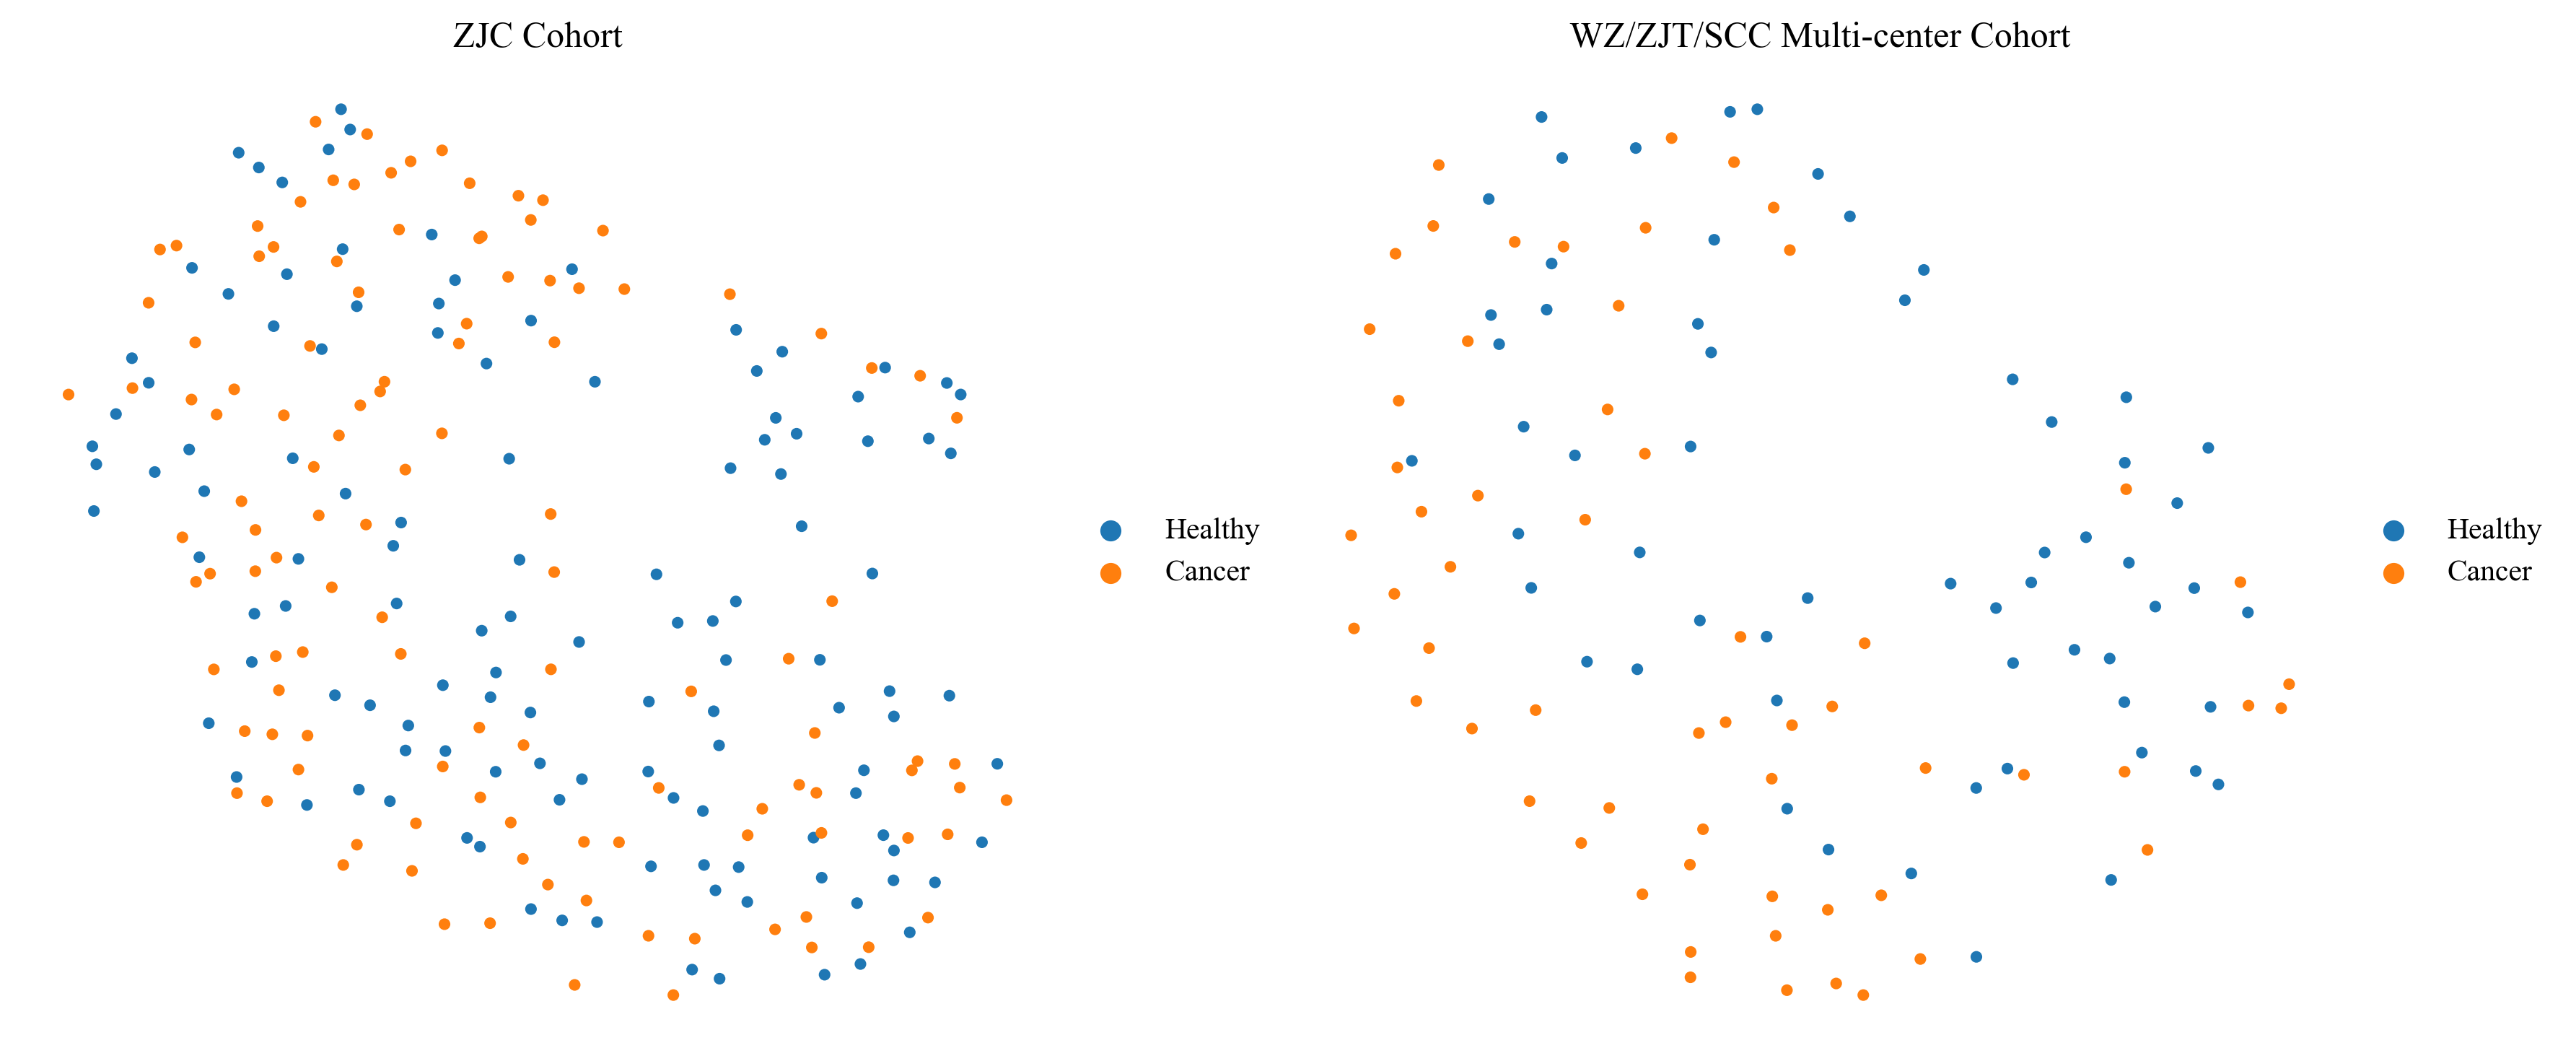

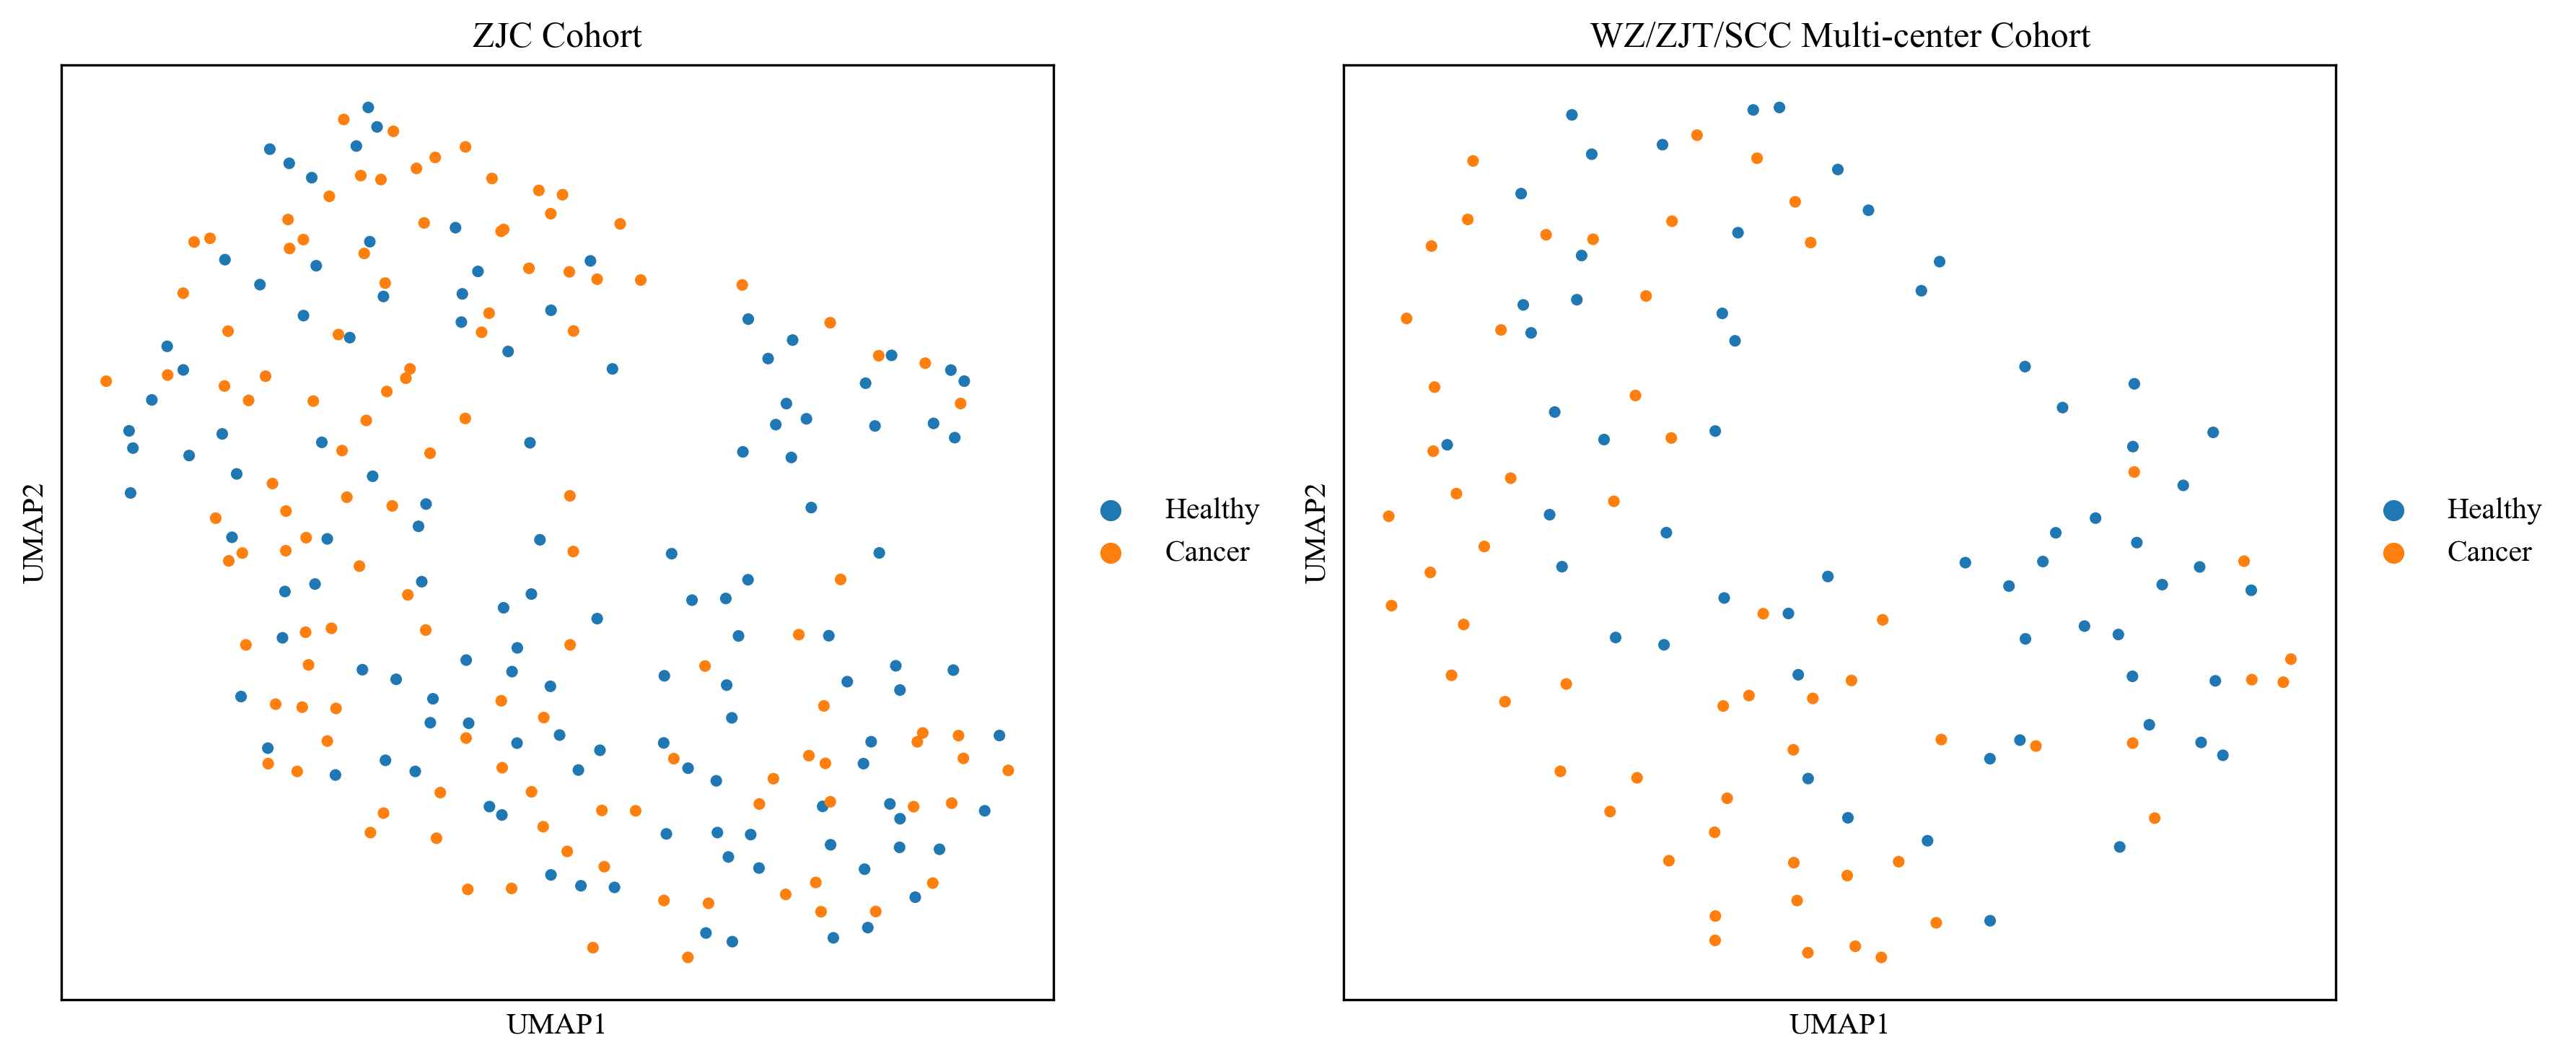

In [11]:
# adata_zjc_normalized, adata_wz_zjt_scc_normalized

def plot_before_imputation(adata_train, adata_test, point_size=60):
    adata_train_ = adata_train.copy()
    adata_test_ = adata_test.copy()

    # ----------------------------
    # Prepare UMAP (from raw counts)
    # ----------------------------
    def run_umap_on_raw(adata):
        adata_raw = adata.copy()
        sc.pp.neighbors(adata_raw, use_rep="X")
        sc.tl.umap(adata_raw)
        return adata_raw

    adata_train_umap = run_umap_on_raw(adata_train_)
    adata_test_umap = run_umap_on_raw(adata_test_)

    # ----------------------------
    # Helper function for plotting
    # ----------------------------
    def make_plot(frameon, save_name):
        fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=300)

        # Train – UMAP
        sc.pl.umap(
            adata_train_umap,
            color="label",
            ax=axes[0],
            show=False,
            title="ZJC Cohort",
            size=point_size,
            frameon=frameon,
        )

        # Test – UMAP
        sc.pl.umap(
            adata_test_umap,
            color="label",
            ax=axes[1],
            show=False,
            title="WZ/ZJT/SCC Multi-center Cohort",
            size=point_size,
            frameon=frameon,
        )

        plt.tight_layout()

        plt.savefig(
            join(figures_path, save_name),
            dpi=1500,
            bbox_inches="tight"
        )

        plt.show()
        plt.close(fig)

    # ----------------------------
    # Save frameless version
    # ----------------------------
    make_plot(
        frameon=False,
        save_name="plot1_before_imputation_frameless.png"
    )

    print()

    # ----------------------------
    # Save framed version
    # ----------------------------
    make_plot(
        frameon=True,
        save_name="plot1_before_imputation_framed.png"
    )

plot_before_imputation(adata_zjc_normalized, adata_wz_zjt_scc_normalized)

## Imputation

In [12]:
!pip install pimms-learn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 18.7 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.2/89.2 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 204.4/204.4 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 86.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.9/85.9 kB 7.0 MB/s eta 0:00:00
  Created wheel for njab: filename=njab-0.1.2-py3-none-any.whl size=20324 sha256=0f728b75584cb84ab8e85a61f451cd95a570caf498af7cca20299cf6a49e1918
  Stored in directory: /root/.cache/pip/wheels/d0/04/58/fbe78ed774d98d623bdb95acefd27704f2f116fb90384a7c07
Successfully built njab
  Attempting uninstall: fastprogress
    Found existing installation: fastprogress 1.1.5
    Uninstalling fastprogress-1.1.5:
      Successfully uninstalled fastprogress-1.1.5


In [13]:
import pimmslearn

In [14]:
import numpy as np
import pandas as pd
from anndata import AnnData
from pimmslearn.sklearn.ae_transformer import AETransformer


# # <Reset matplotlib to default settings>
# import matplotlib as mpl
# mpl.rcParams.update(mpl.rcParamsDefault)

# import matplotlib.font_manager as fm
# import matplotlib.pyplot as plt
# fm.fontManager.addfont(font_path)
# plt.rcParams['font.family'] = 'Times New Roman'
# print([f.name for f in fm.fontManager.ttflist if "Times" in f.name])
# # </Reset matplotlib to default settings>


class PimmsVAEImputer:
    """
    Impute missing proteomics values using PIMMS-VAE.
    Zeros are treated as missing (NaN) before fitting.
    The class imputes exactly one AnnData per call.
    """

    def __init__(self,
                 hidden_layers=None,
                 latent_dim=50,
                 batch_size=32,
                 epochs_max=20,
                 cuda=False):

        self.hidden_layers = hidden_layers or [512]
        self.latent_dim = latent_dim
        self.batch_size = batch_size
        self.epochs_max = epochs_max
        self.cuda = cuda
        self.model = None


    def fit_transform(self, adata: AnnData):
        """Impute one AnnData object and return a new AnnData with imputed values."""

        # --- Copy to preserve metadata ---
        adata_out = adata.copy()

        # --- Extract matrix and convert to float ---
        X = np.array(adata_out.X, dtype=float)

        # --- Convert zeros to NaN (correct for metaproteomics + PIMMS) ---
        zero_count = np.sum(X == 0)
        X[X == 0] = np.nan
        print(f"Converted {zero_count:,} zeros → NaN for imputation")

        # --- Convert to pandas DataFrame (required by PIMMS) ---
        df = pd.DataFrame(X, index=adata_out.obs_names, columns=adata_out.var_names)

        # --- Build PIMMS-VAE model ---
        model = AETransformer(
            model="VAE",
            hidden_layers=self.hidden_layers,
            latent_dim=self.latent_dim,
            batch_size=self.batch_size,
        )

        # --- Fit the model ---
        print("Training PIMMS-VAE model...")
        model.fit(df, cuda=self.cuda, epochs_max=self.epochs_max)

        # --- Impute ---
        print("Performing imputation...")
        df_imp = model.transform(df)

        # --- Store imputed matrix ---
        imputed_values = df_imp.values
        adata_out.layers["imputed"] = imputed_values.copy()
        adata_out.X = imputed_values.copy()   # replace X with imputed values

        # Keep the trained model
        self.model = model

        # --- Summary ---
        print(f"Original mean (ignoring NaN): {np.nanmean(X):.4f}")
        print(f"Imputed mean:                 {np.mean(imputed_values):.4f}")
        print("Imputation completed.")

        return adata_out

Converted 441,718 zeros → NaN for imputation
Training PIMMS-VAE model...


/usr/local/lib/python3.12/dist-packages/fastprogress/fastprogress.py:74: UserWarning: Your generator is empty.
  warn("Your generator is empty.")


epoch,train_loss,valid_loss,time
0,4477.491699,None,00:02
1,4476.763672,None,00:03
2,4464.294922,None,00:04
3,4461.890137,None,00:02
4,4456.179199,None,00:02
5,4449.098633,None,00:01
6,4438.835938,None,00:01
7,4431.174805,None,00:01
8,4422.173340,None,00:02
9,4415.853027,None,00:02


Performing imputation...


Original mean (ignoring NaN): 22.3095
Imputed mean:                 21.6769
Imputation completed.
Converted 240,247 zeros → NaN for imputation
Training PIMMS-VAE model...


/usr/local/lib/python3.12/dist-packages/fastprogress/fastprogress.py:74: UserWarning: Your generator is empty.
  warn("Your generator is empty.")


epoch,train_loss,valid_loss,time
0,4242.060547,None,00:00
1,4237.389160,None,00:00
2,4225.513672,None,00:00
3,4225.795410,None,00:00
4,4220.516602,None,00:00
5,4213.828125,None,00:00
6,4211.091309,None,00:00
7,4207.724121,None,00:00
8,4200.719238,None,00:00
9,4195.163086,None,00:00


Performing imputation...


Original mean (ignoring NaN): 22.1237
Imputed mean:                 21.4496
Imputation completed.
=== Adata ZJC Imputed ===
Shape: (240, 4722)
Mean: 21.6769
Min:  14.9954
Max:  34.1833
Non-zero fraction: 1.0000
AnnData object with n_obs × n_vars = 240 × 4722
    obs: 'label', 'batch'
    var: 'taxid', 'root', 'domain', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'species', 'strain'
    layers: 'raw_counts', 'raw', 'imputed'

=== Adata WZ/ZJT/SCC Imputed ===
Shape: (120, 4725)
Mean: 21.4496
Min:  14.2204
Max:  34.6058
Non-zero fraction: 1.0000
AnnData object with n_obs × n_vars = 120 × 4725
    obs: 'label', 'batch'
    var: 'taxid', 'root', 'domain', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'species', 'strain'
    layers: 'raw_counts', 'raw', 'imputed'



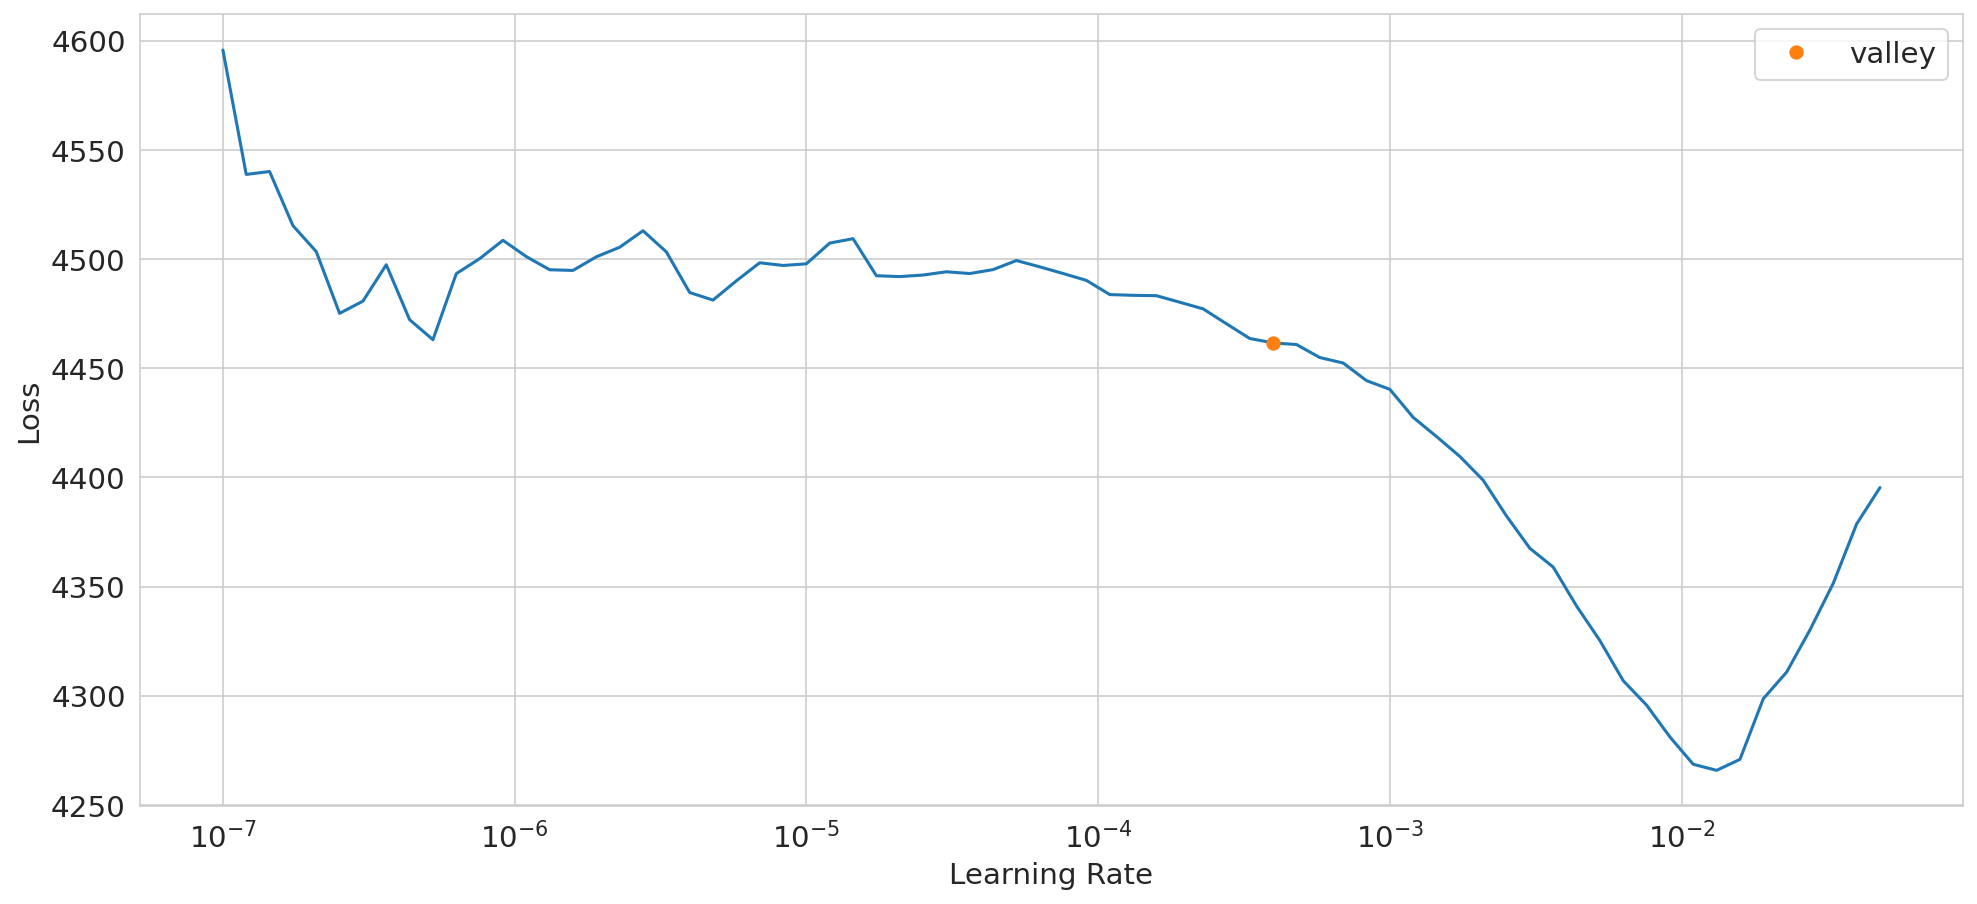

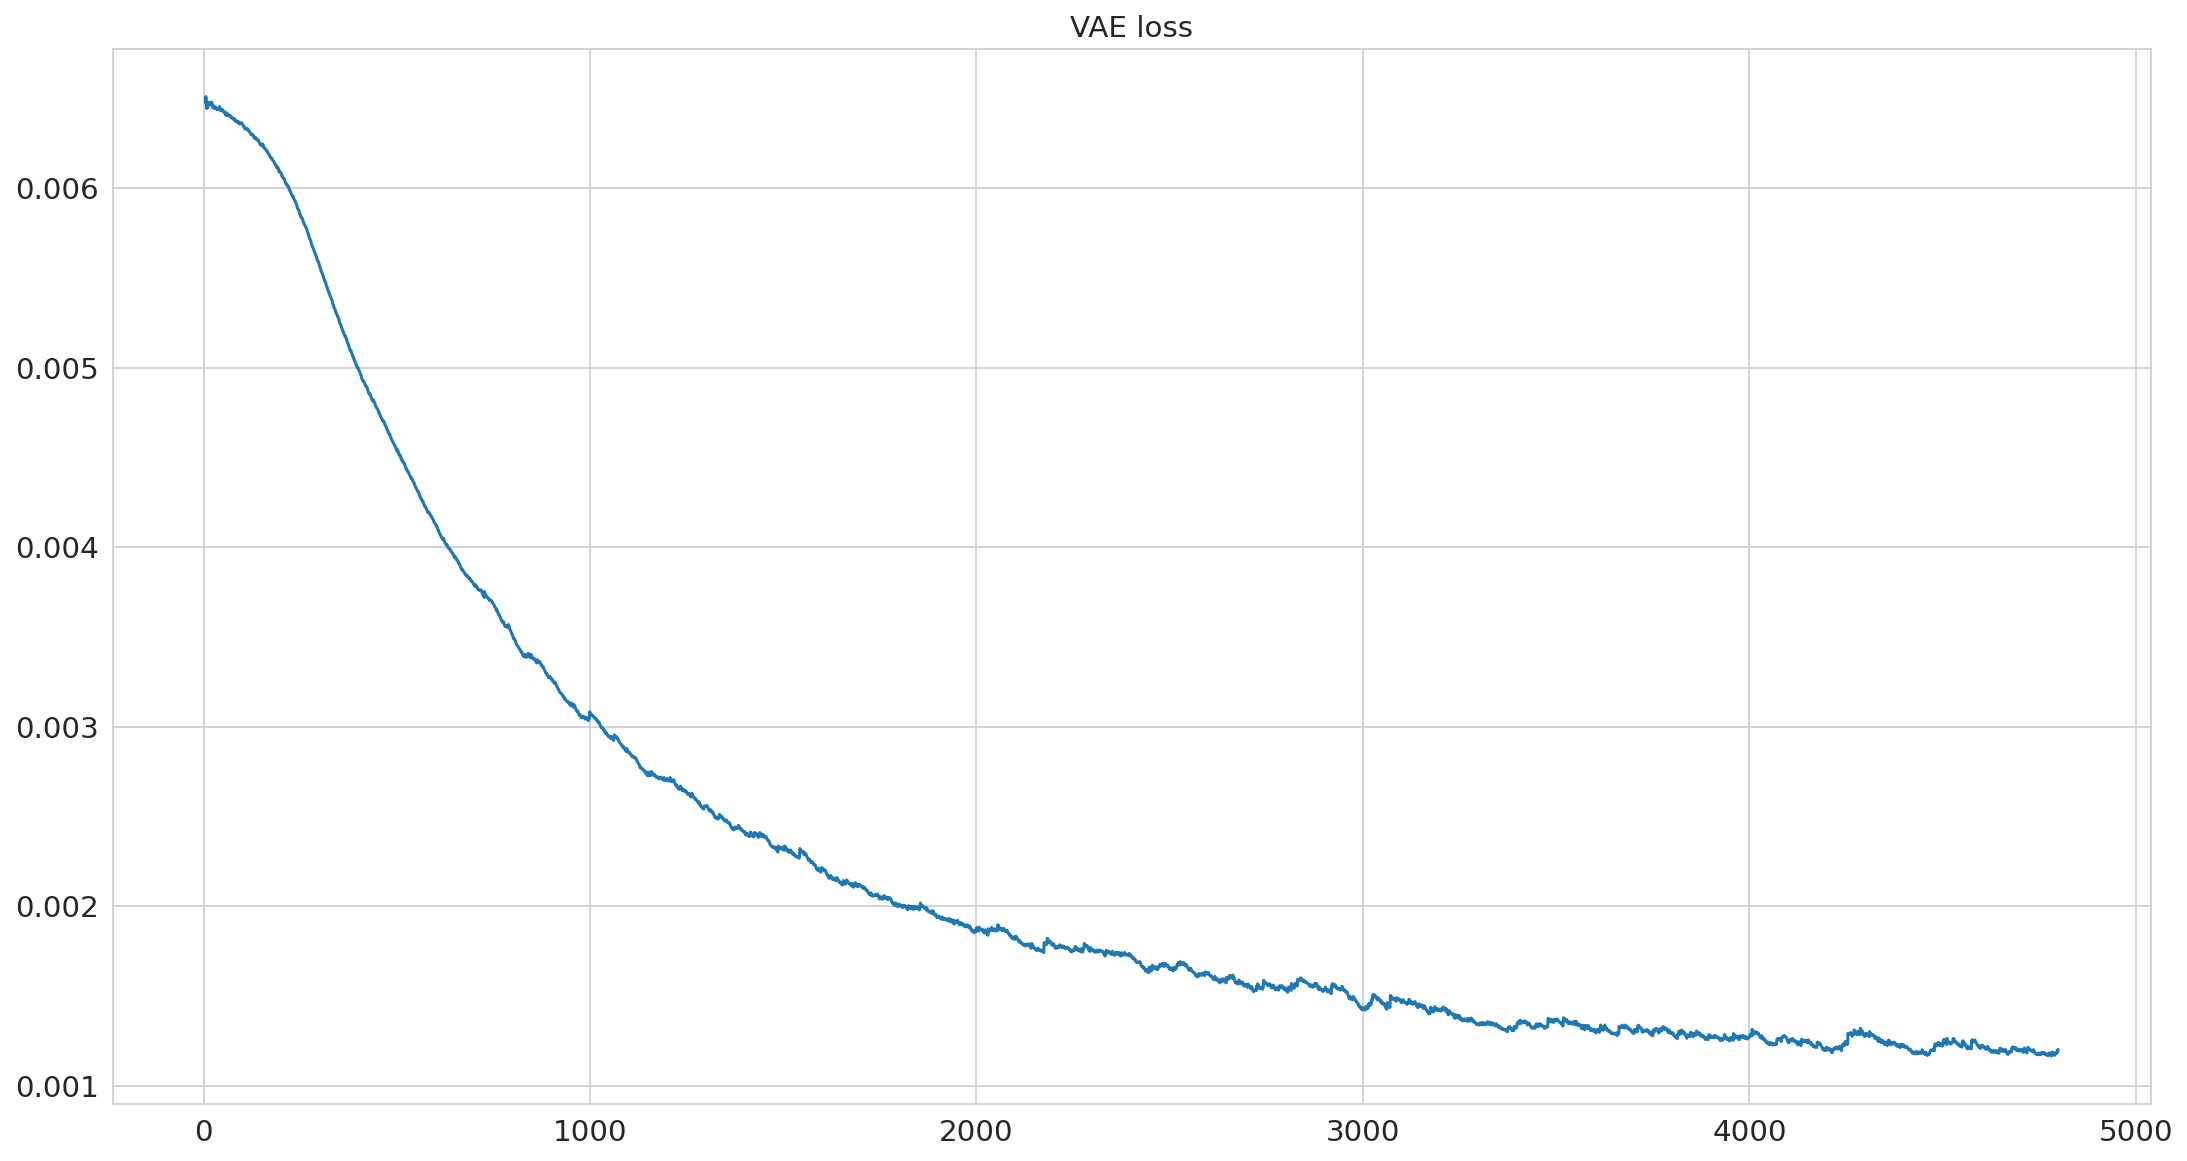

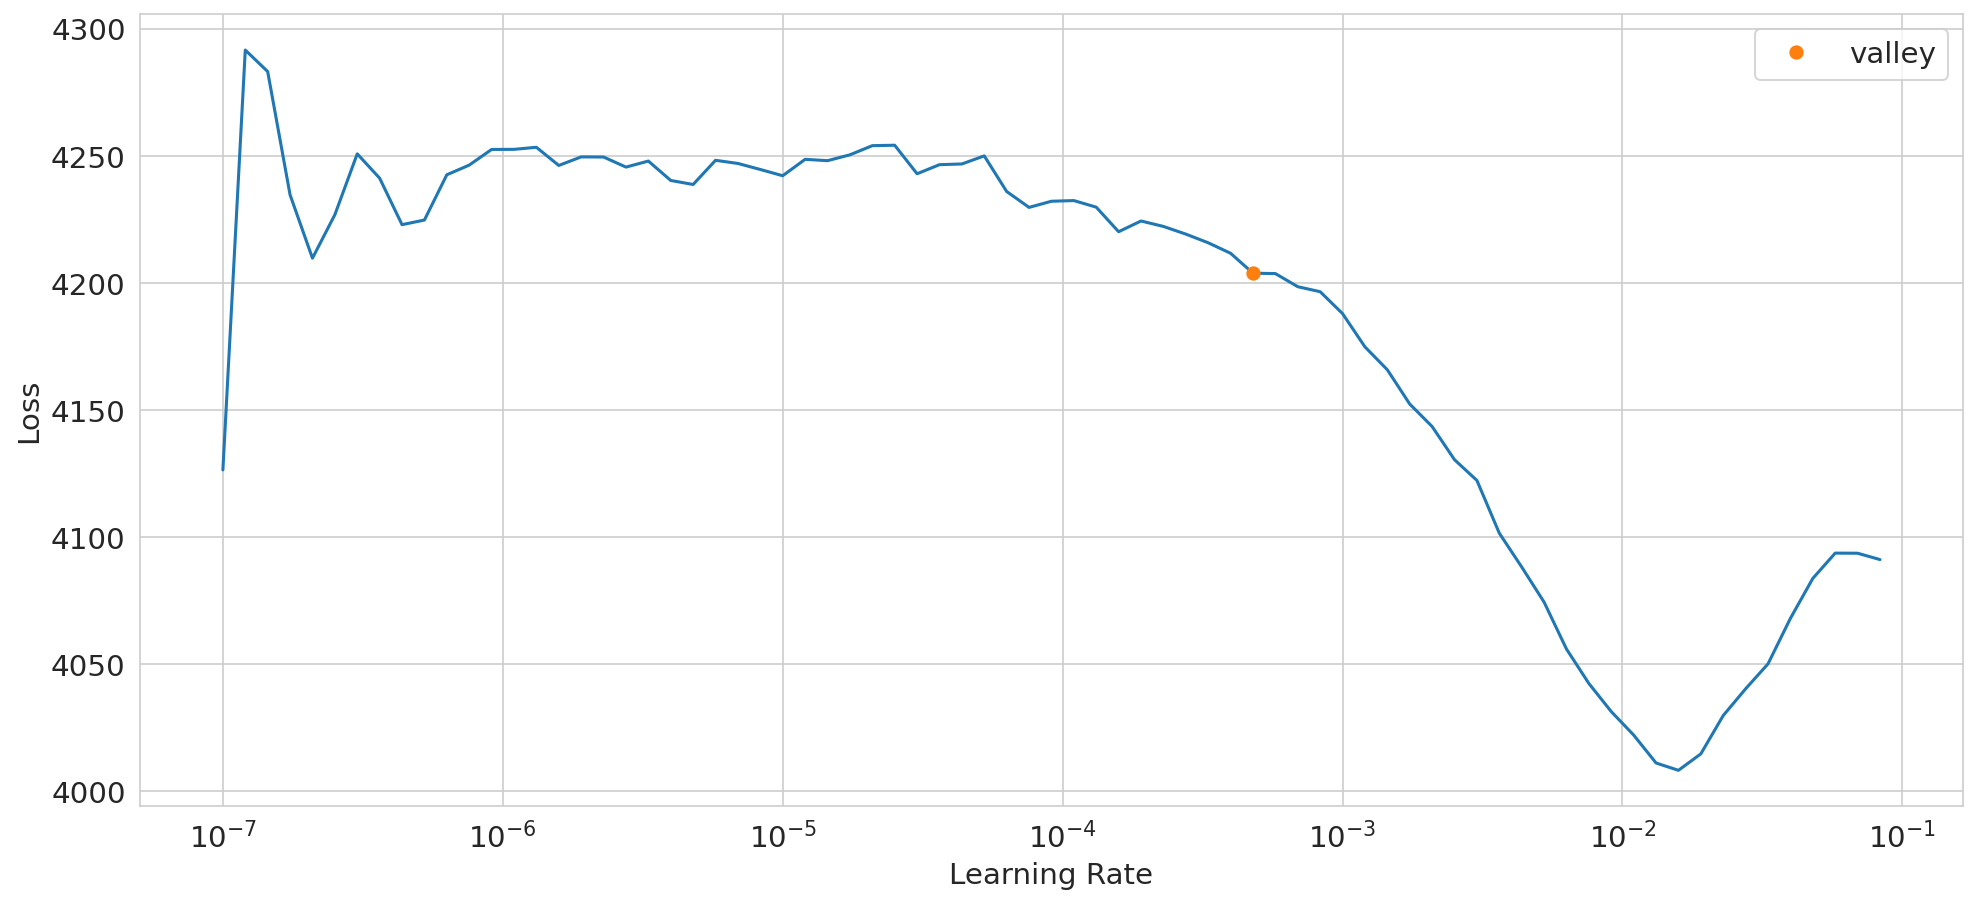

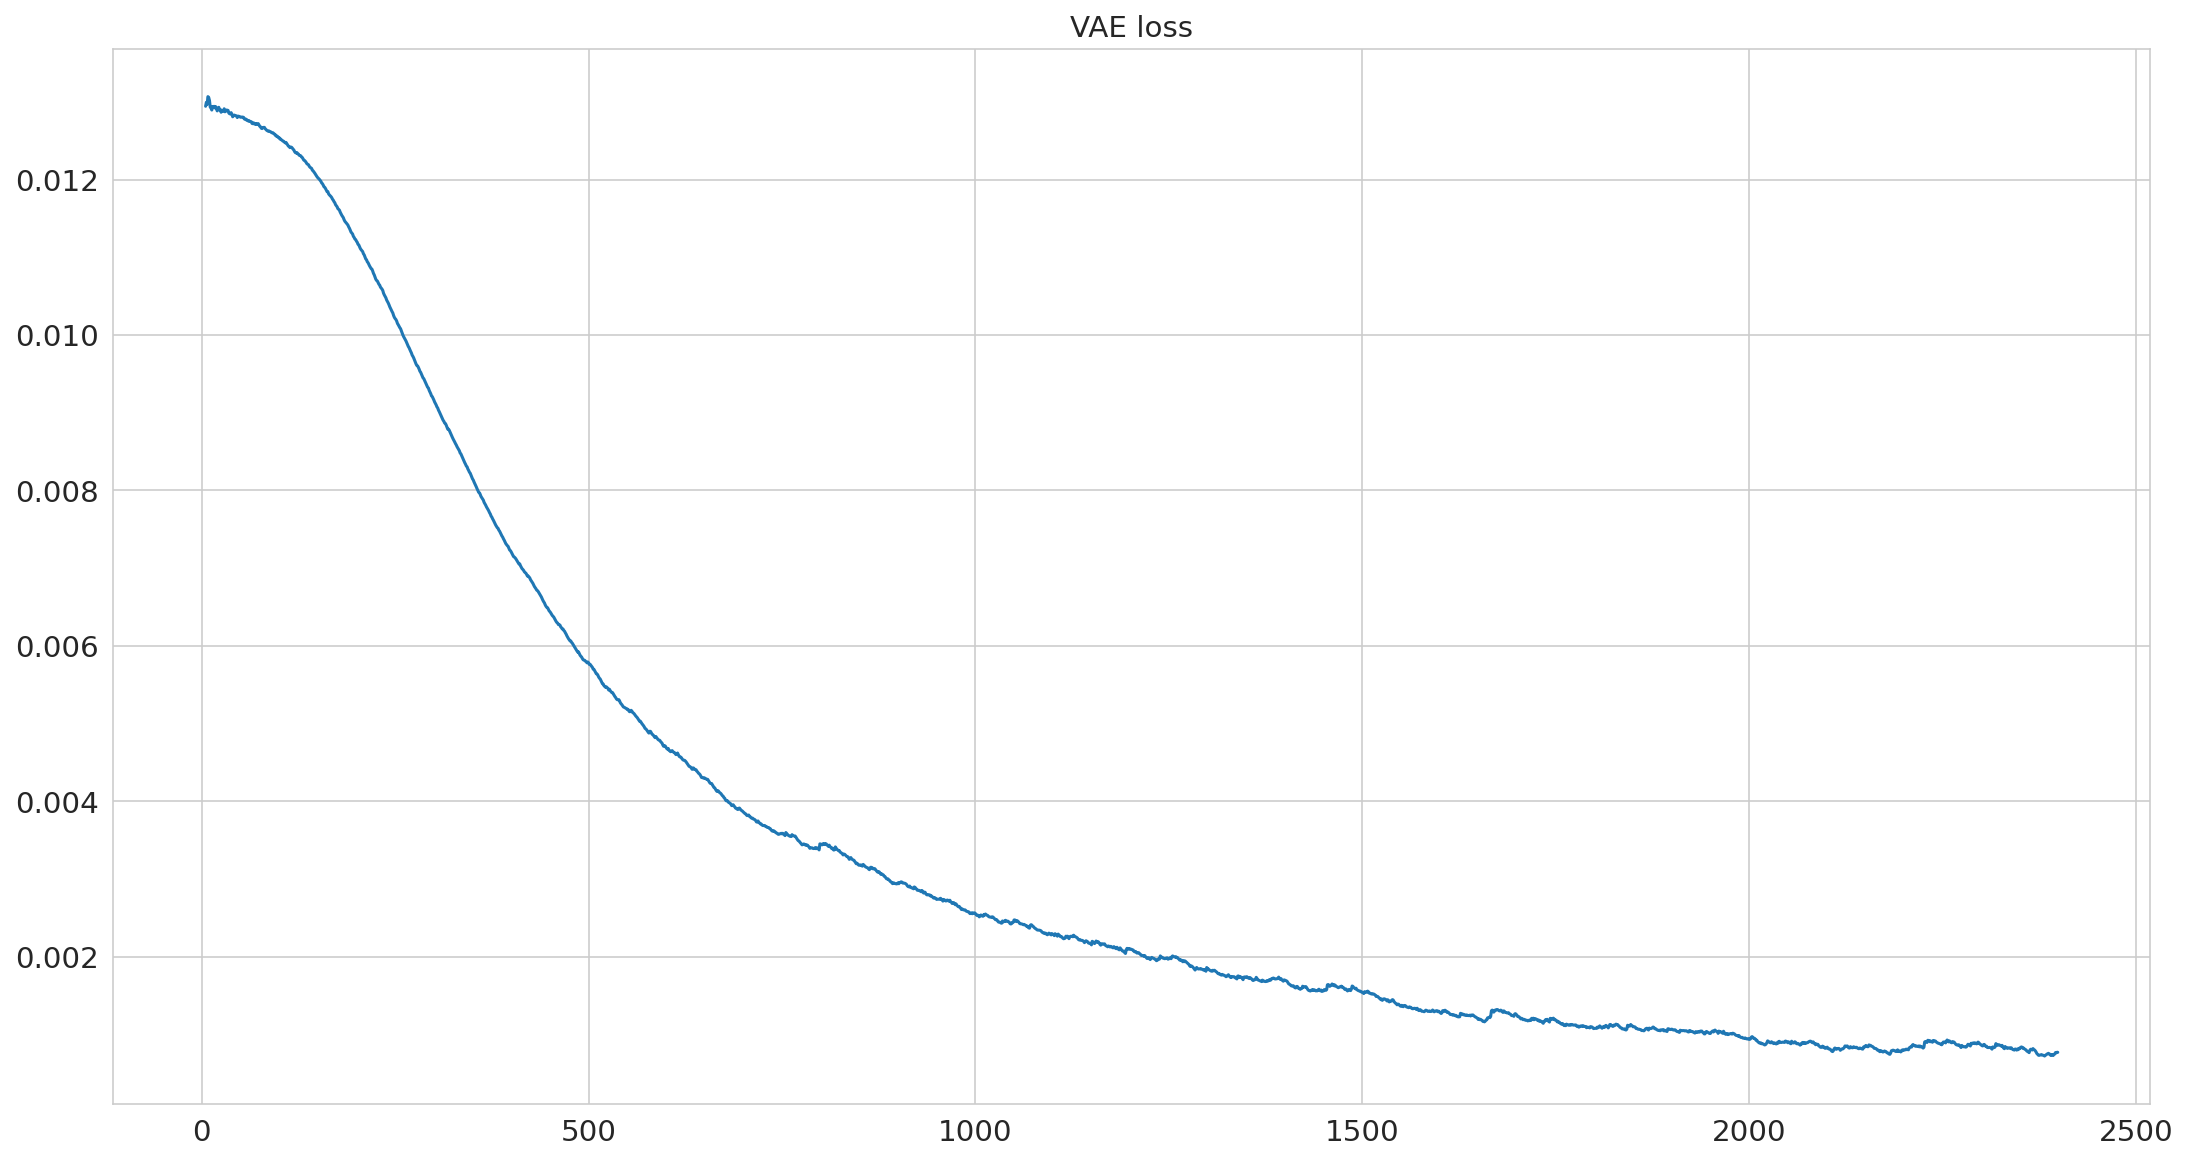

In [15]:
# adata_zjc_normalized, adata_wz_zjt_scc_normalized

imputer = PimmsVAEImputer(latent_dim=64, epochs_max=600)

adata_zjc_imputed = imputer.fit_transform(adata_zjc_normalized)
adata_wz_zjt_scc_imputed  = imputer.fit_transform(adata_wz_zjt_scc_normalized)

print("="*100)
adata_head(adata_zjc_imputed, name="Adata ZJC Imputed")
print("="*100)
adata_head(adata_wz_zjt_scc_imputed, name="Adata WZ/ZJT/SCC Imputed")


In [16]:
# Save imputed adatas to Temp folder
sc.write(join(temp_adata_path, "adata_zjc_imputed.h5ad"), adata_zjc_imputed)
sc.write(join(temp_adata_path, "adata_wz_zjt_scc_imputed.h5ad"), adata_wz_zjt_scc_imputed)
print("Done Saving Temp")

Done Saving Temp


## Plot 2 - After Imputation

In [17]:
# Reset matplotlib to default settings
import matplotlib as mpl
mpl.rcParams.update(mpl.rcParamsDefault)

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Times New Roman'

print([f.name for f in fm.fontManager.ttflist if "Times" in f.name])

['Times New Roman', 'Times New Roman']


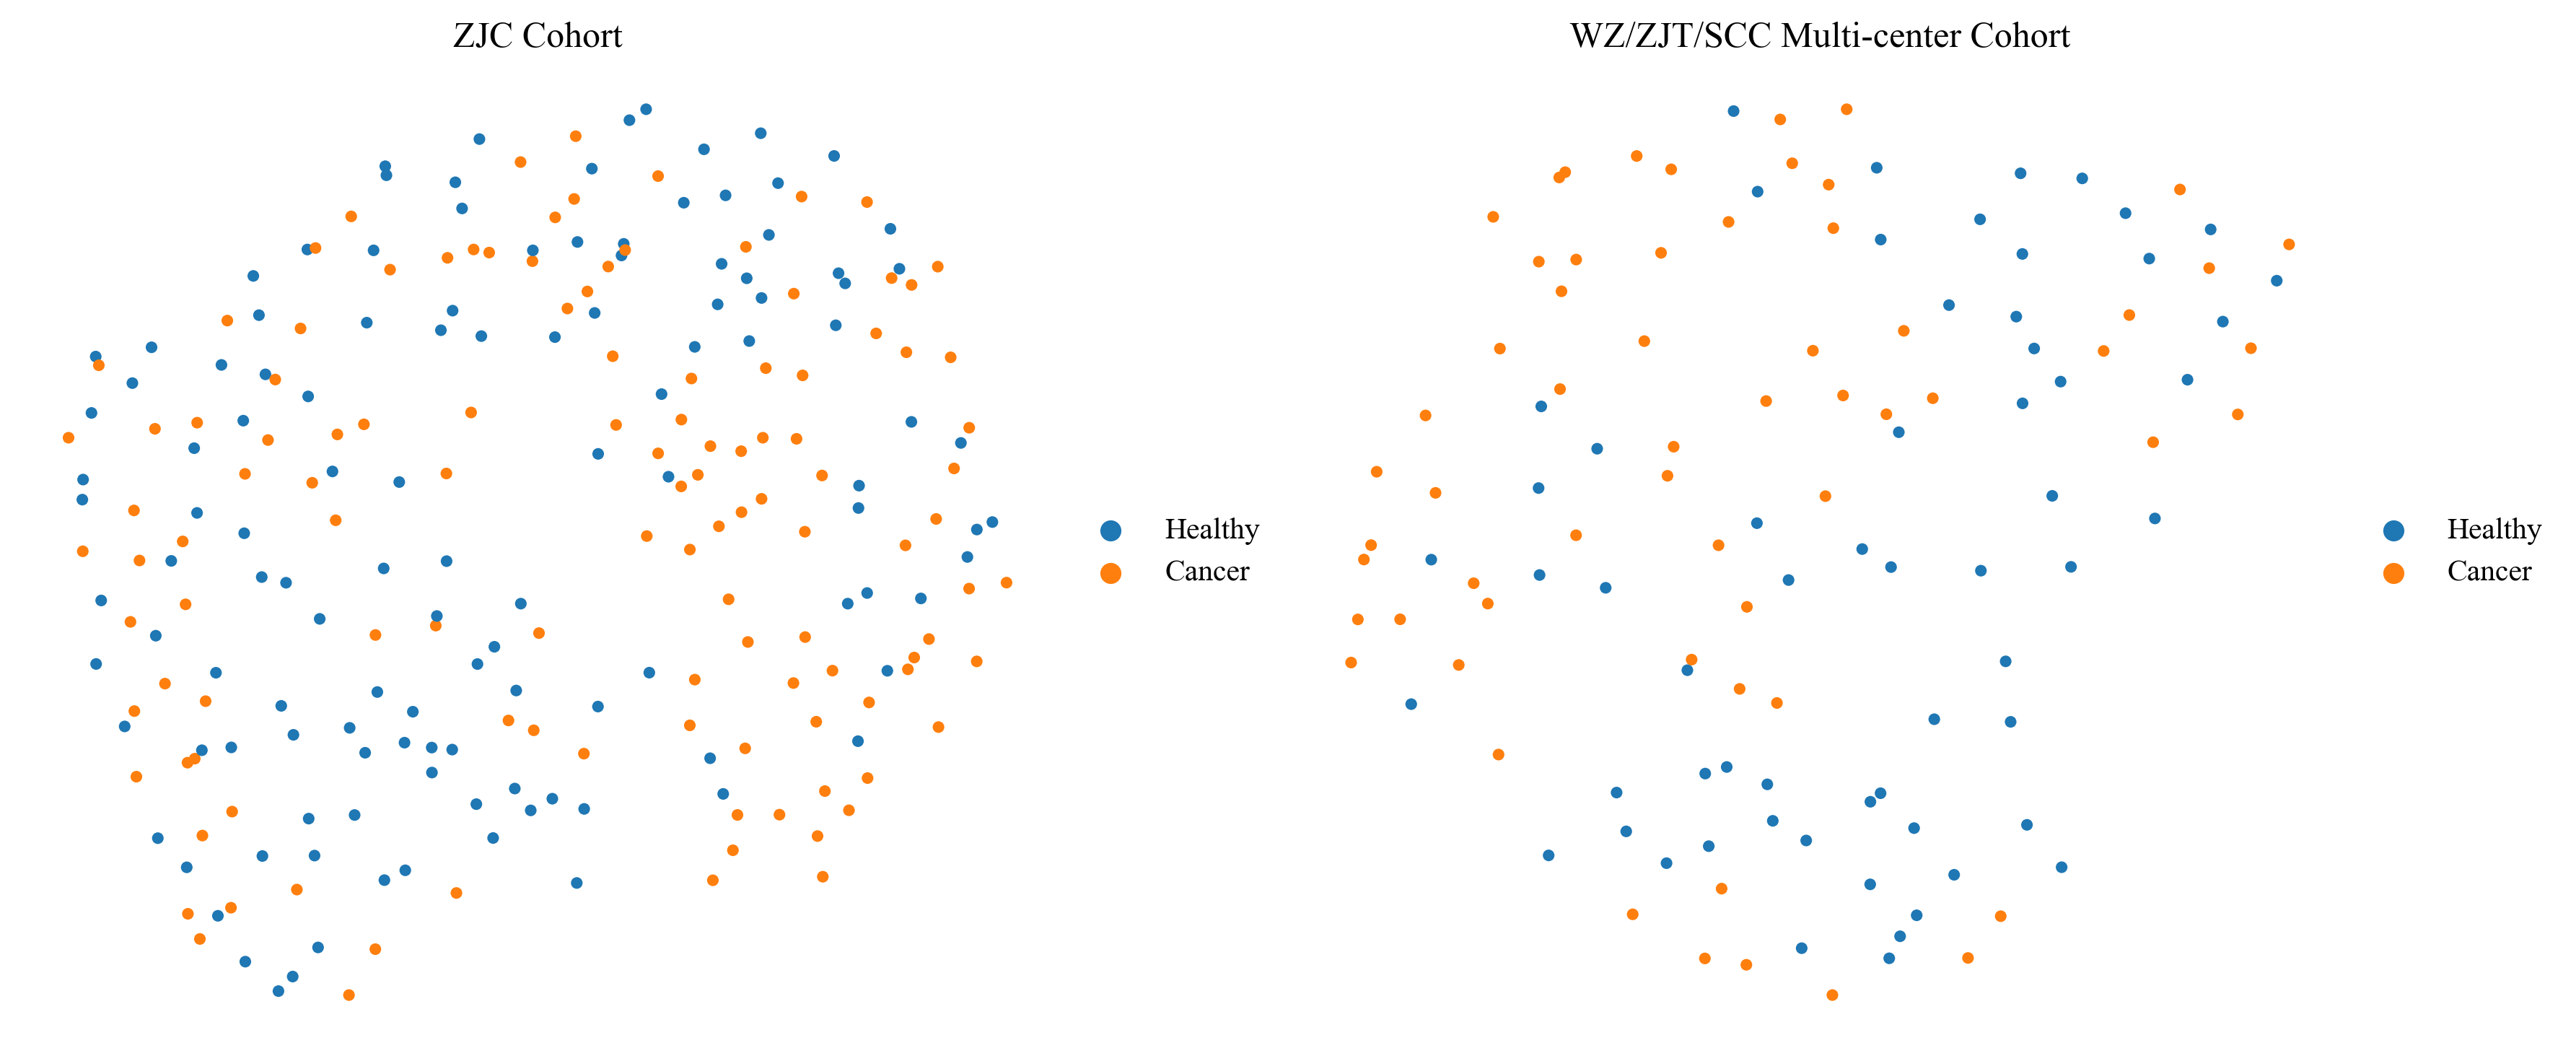

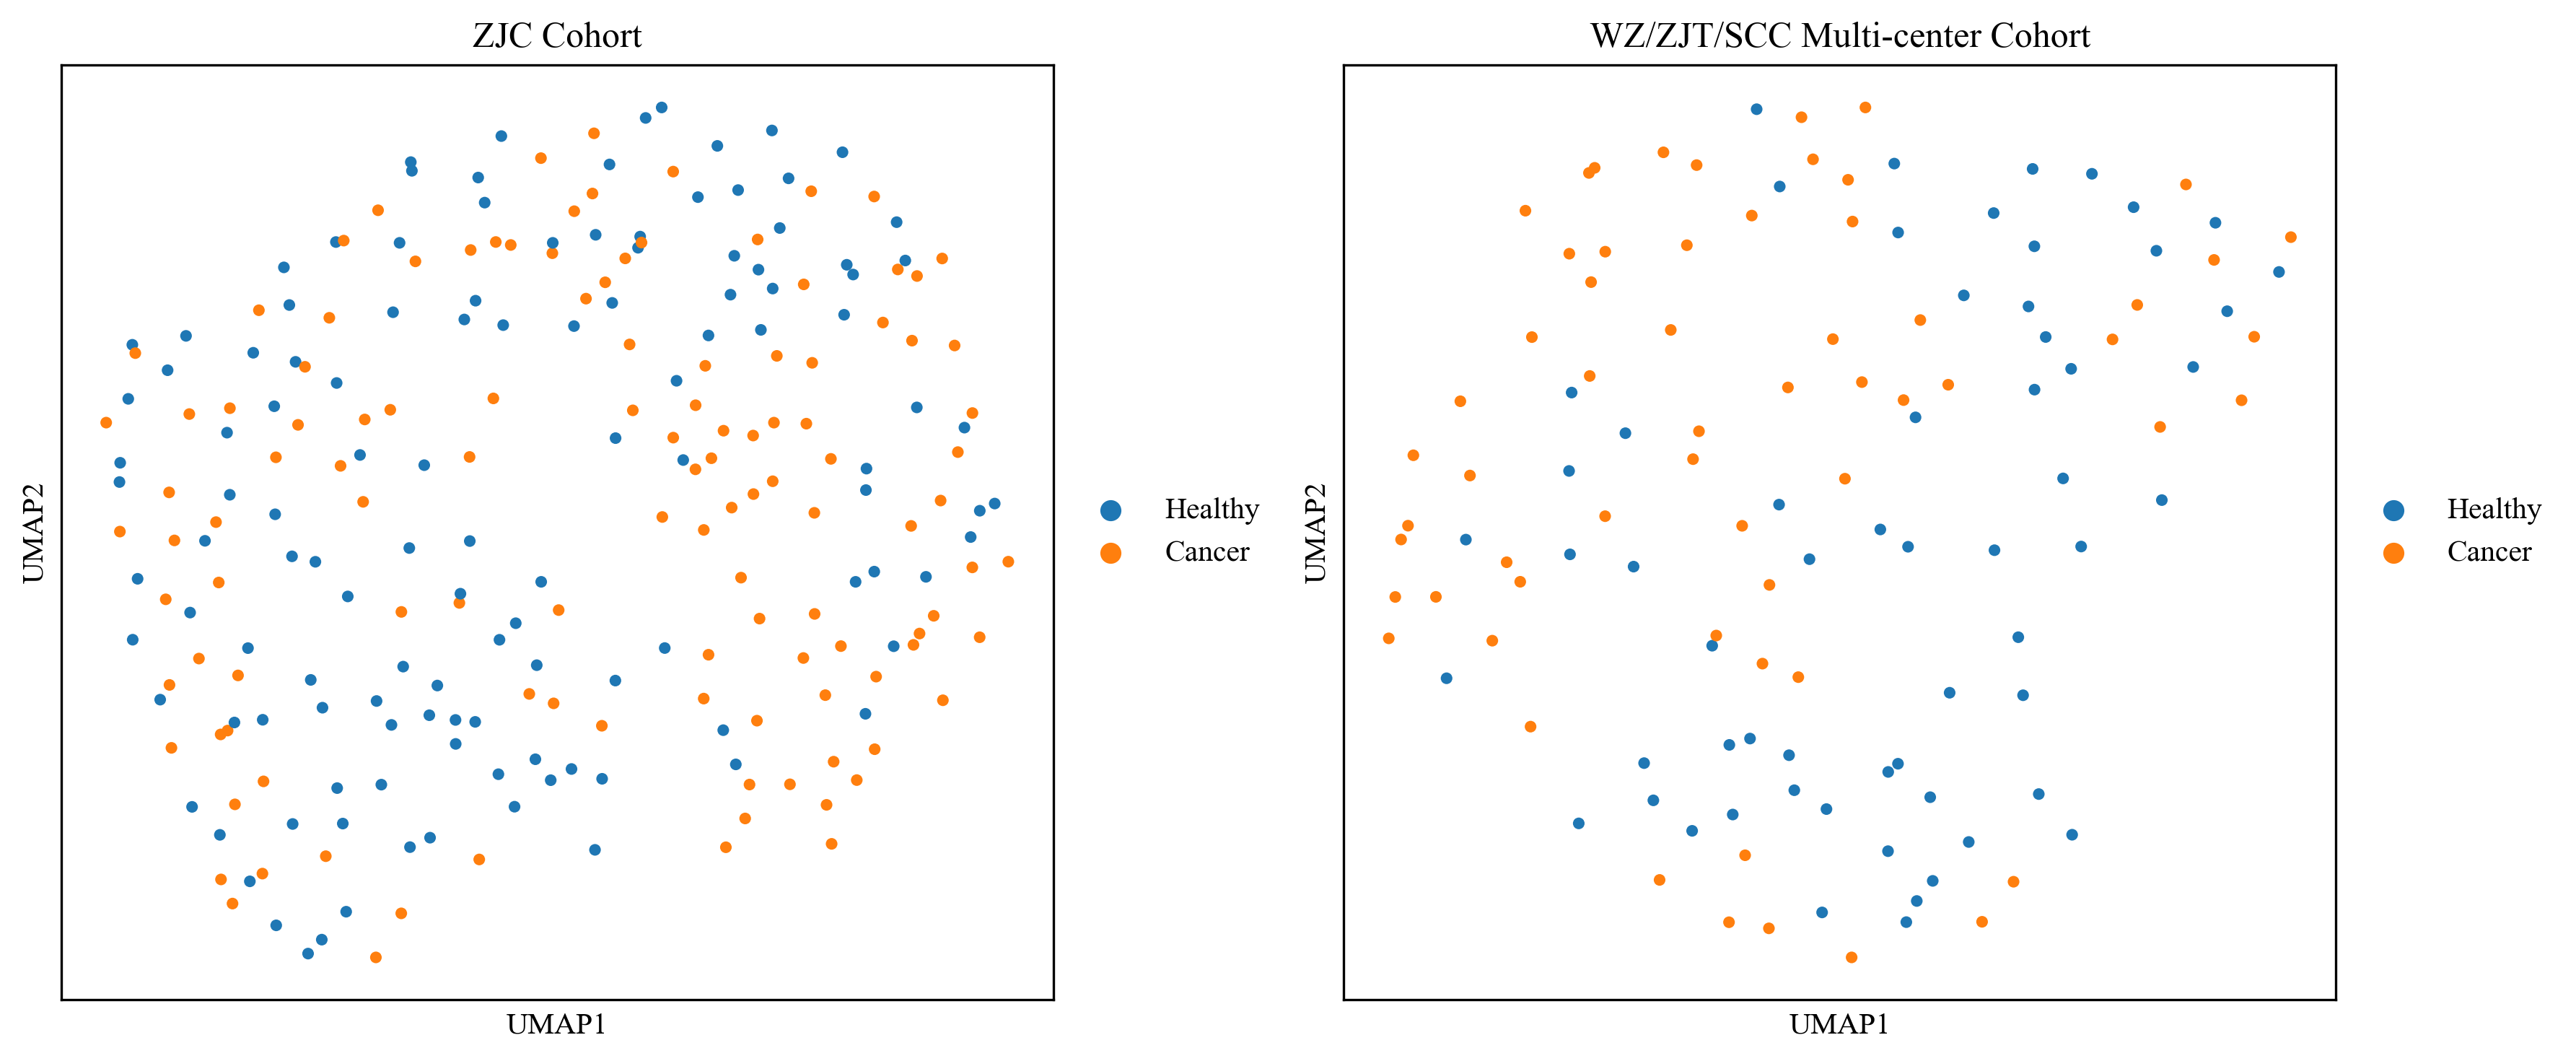

In [18]:
# adata_zjc_imputed, adata_wz_zjt_scc_imputed

def plot_after_imputation(adata_train, adata_test, point_size=60):
    adata_train_ = adata_train.copy()
    adata_test_ = adata_test.copy()

    # ----------------------------
    # Prepare UMAP (from raw counts)
    # ----------------------------
    def run_umap_on_raw(adata):
        adata_raw = adata.copy()
        sc.pp.neighbors(adata_raw, use_rep="X")
        sc.tl.umap(adata_raw)
        return adata_raw

    adata_train_umap = run_umap_on_raw(adata_train_)
    adata_test_umap = run_umap_on_raw(adata_test_)

    # ----------------------------
    # Helper function for plotting
    # ----------------------------
    def make_plot(frameon, save_name):
        fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=300)

        # Train – UMAP
        sc.pl.umap(
            adata_train_umap,
            color="label",
            ax=axes[0],
            show=False,
            title="ZJC Cohort",
            size=point_size,
            frameon=frameon,
        )

        # Test – UMAP
        sc.pl.umap(
            adata_test_umap,
            color="label",
            ax=axes[1],
            show=False,
            title="WZ/ZJT/SCC Multi-center Cohort",
            size=point_size,
            frameon=frameon,
        )

        plt.tight_layout()

        plt.savefig(
            join(figures_path, save_name),
            dpi=1200,
            bbox_inches="tight"
        )

        plt.show()
        plt.close(fig)

    # ----------------------------
    # Save frameless version
    # ----------------------------
    make_plot(
        frameon=False,
        save_name="plot2_after_imputation_frameless.png"
    )

    print()

    # ----------------------------
    # Save framed version
    # ----------------------------
    make_plot(
        frameon=True,
        save_name="plot2_after_imputation_framed.png"
    )

plot_after_imputation(adata_zjc_imputed, adata_wz_zjt_scc_imputed)

## Integration

In [19]:
def merge_adatas(adata_train, adata_test):
    train = adata_train.copy()
    test = adata_test.copy()

    # Find shared features
    shared_vars = train.var_names.intersection(test.var_names)
    print(f"Number of shared variables: {len(shared_vars)}")

    # Subset to shared features
    train = train[:, shared_vars].copy()
    test  = test[:, shared_vars].copy()
    print(train.X)

    # Assign batch and make categorical
    train.obs["cohort"] = 1
    test.obs["cohort"]  = 2
    train.obs["cohort"] = train.obs["cohort"].astype("category")
    test.obs["cohort"]  = test.obs["cohort"].astype("category")

    # Concatenate using Scanpy's default method
    adata_merged = train.concatenate(
        test,
        join="inner",           # keep only shared features
        batch_key="batch_temp", # temporary batch key
        index_unique=None       # keep original obs names
    )

    # Overwrite batch column with proper numeric batch
    adata_merged.obs["cohort"] = adata_merged.obs["cohort"].astype(int)
    adata_merged.obs["cohort"] = adata_merged.obs["cohort"].astype("category")

    # Optional: preserve uns from train
    adata_merged.uns.update(train.uns)

    print("=== Merged ===")
    print("Unique cohorts:", adata_merged.obs["cohort"].unique())

    return adata_merged

# adata_zjc_imputed, adata_wz_zjt_scc_imputed

adata_integrated = merge_adatas(adata_zjc_imputed, adata_wz_zjt_scc_imputed)
print(adata_integrated)
adata_head(adata_integrated, name="Adata Integrated")
print(adata_integrated.X)

Number of shared variables: 4535
[[26.56057167 21.00059891 25.88206482 ... 22.29430008 20.96862984
  18.75120544]
 [26.0641346  21.41470146 26.0339489  ... 20.12679482 21.17835045
  20.9295578 ]
 [26.69626236 22.24834061 26.62336731 ... 22.90658188 21.51615715
  18.38969421]
 ...
 [27.24320984 22.1327095  25.93797684 ... 18.88204384 22.06041527
  20.04874229]
 [25.51523018 20.80653572 24.35043907 ... 20.45470619 22.22592926
  21.26617813]
 [25.81891632 20.48779678 23.94161797 ... 19.59622192 21.22309875
  19.63302994]]


/tmp/ipykernel_19593/469131581.py:21: FutureWarning: The method concatenate is deprecated and will be removed in the future. Use anndata.concat instead of AnnData.concatenate. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata_merged = train.concatenate(


=== Merged ===
Unique cohorts: [1, 2]
Categories (2, int64): [1, 2]
AnnData object with n_obs × n_vars = 360 × 4535
    obs: 'label', 'batch', 'cohort', 'batch_temp'
    var: 'taxid', 'root', 'domain', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'species', 'strain'
    layers: 'raw_counts', 'raw', 'imputed'
=== Adata Integrated ===
Shape: (360, 4535)
Mean: 21.6352
Min:  14.2204
Max:  34.6058
Non-zero fraction: 1.0000
AnnData object with n_obs × n_vars = 360 × 4535
    obs: 'label', 'batch', 'cohort', 'batch_temp'
    var: 'taxid', 'root', 'domain', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'species', 'strain'
    layers: 'raw_counts', 'raw', 'imputed'

[[26.56057167 21.00059891 25.88206482 ... 22.29430008 20.96862984
  18.75120544]
 [26.0641346  21.41470146 26.0339489  ... 20.12679482 21.17835045
  20.9295578 ]
 [26.69626236 22.24834061 26.62336731 ... 22.90658188 21.51615715
  18.38969421]
 ...
 [25.60694504 21.83420563 24.45759964 ... 20.03987503 21.5248

In [20]:
# Save integrated adatas to Temp folder
sc.write(join(temp_adata_path, "adata_integrated.h5ad"), adata_integrated)
print("Done Saving Temp")

Done Saving Temp


## Plot 3 - After Integration

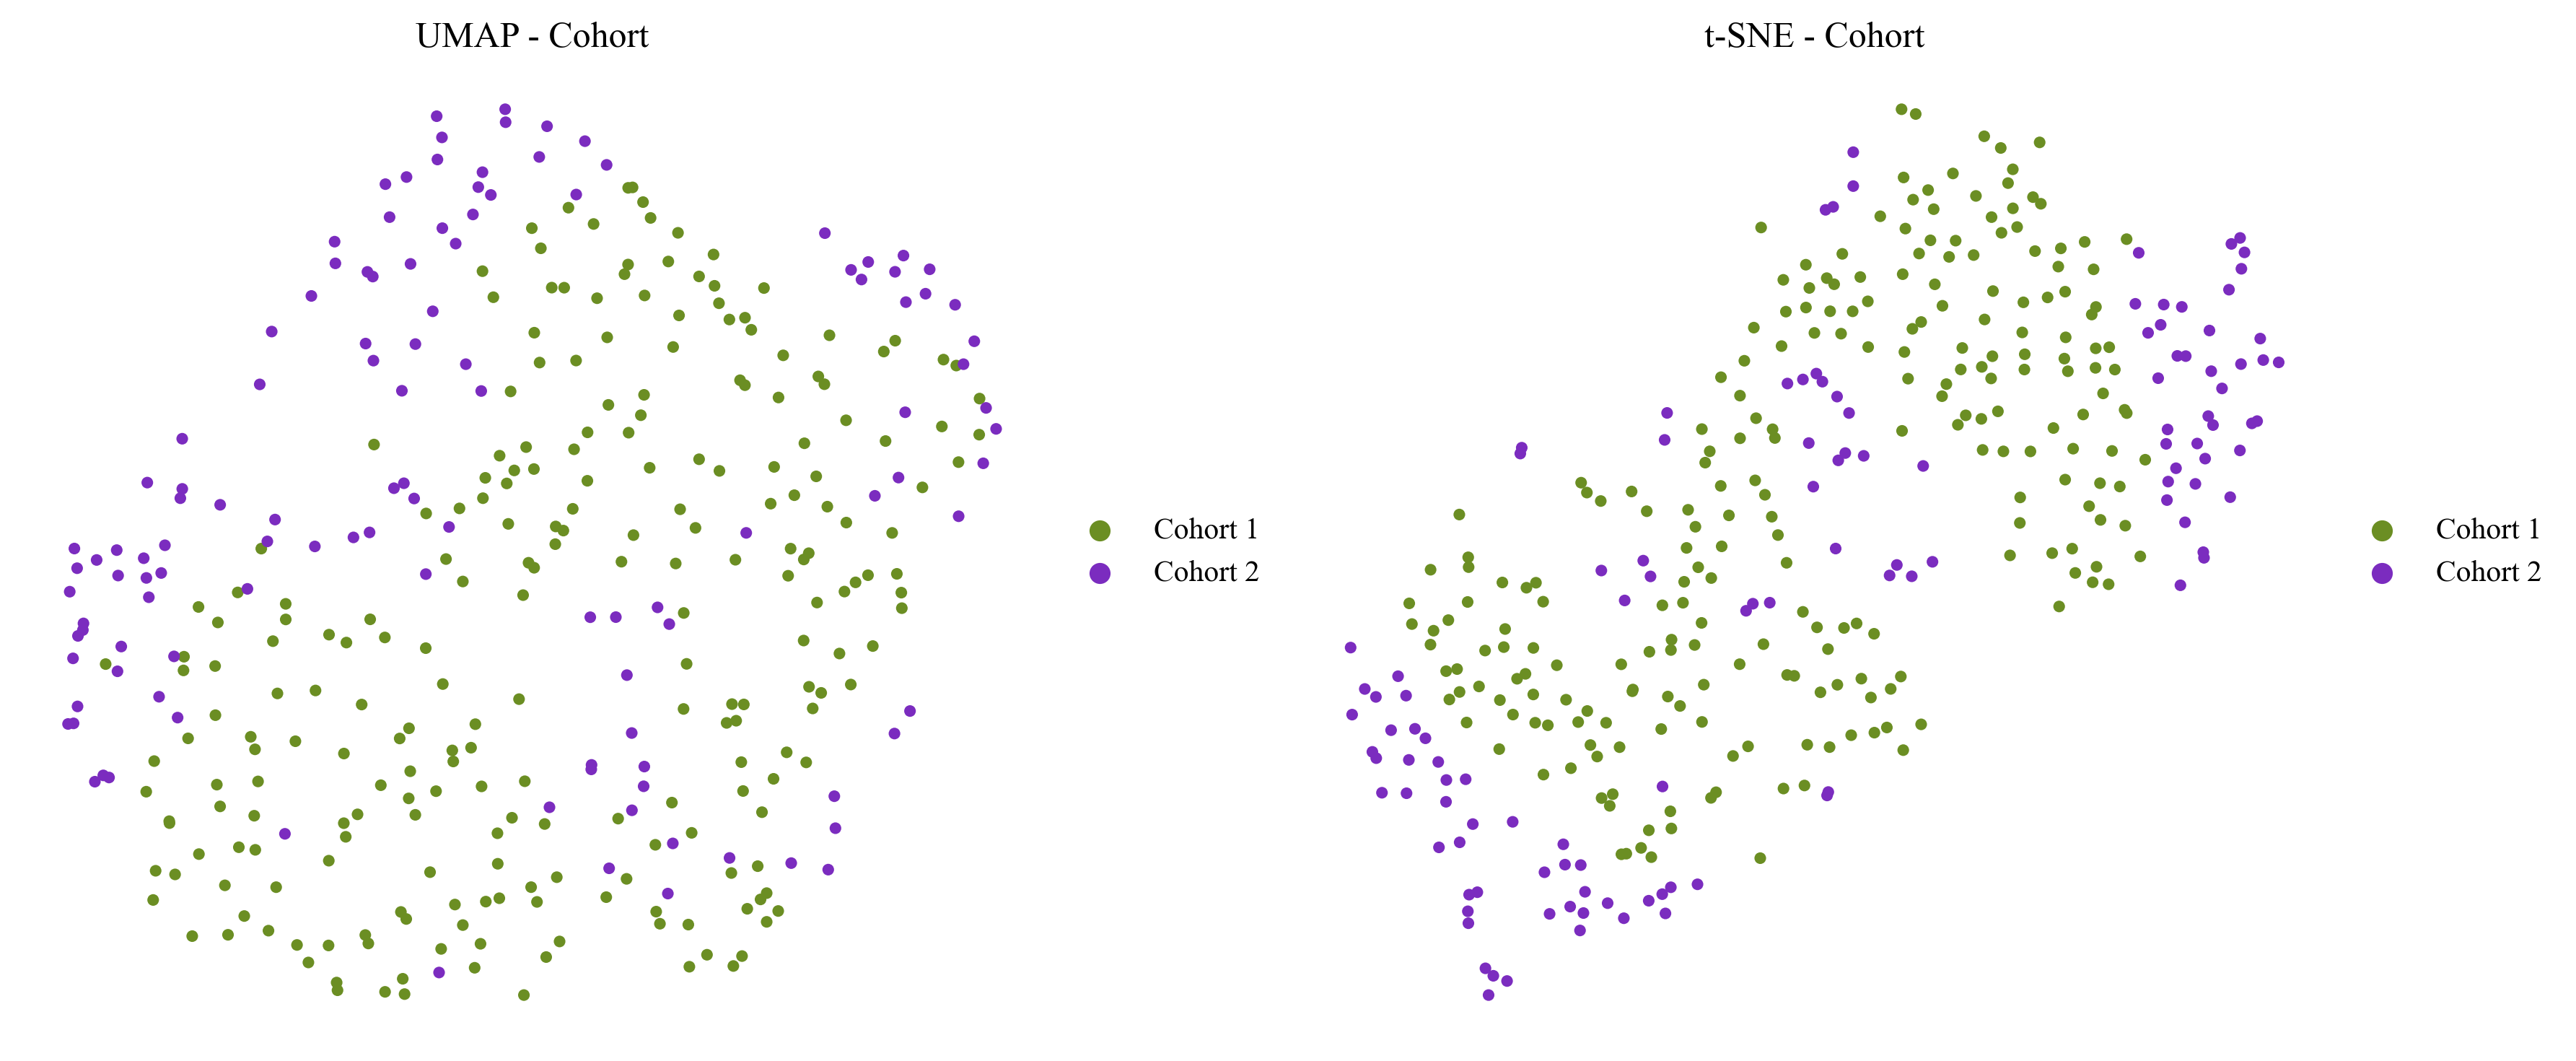

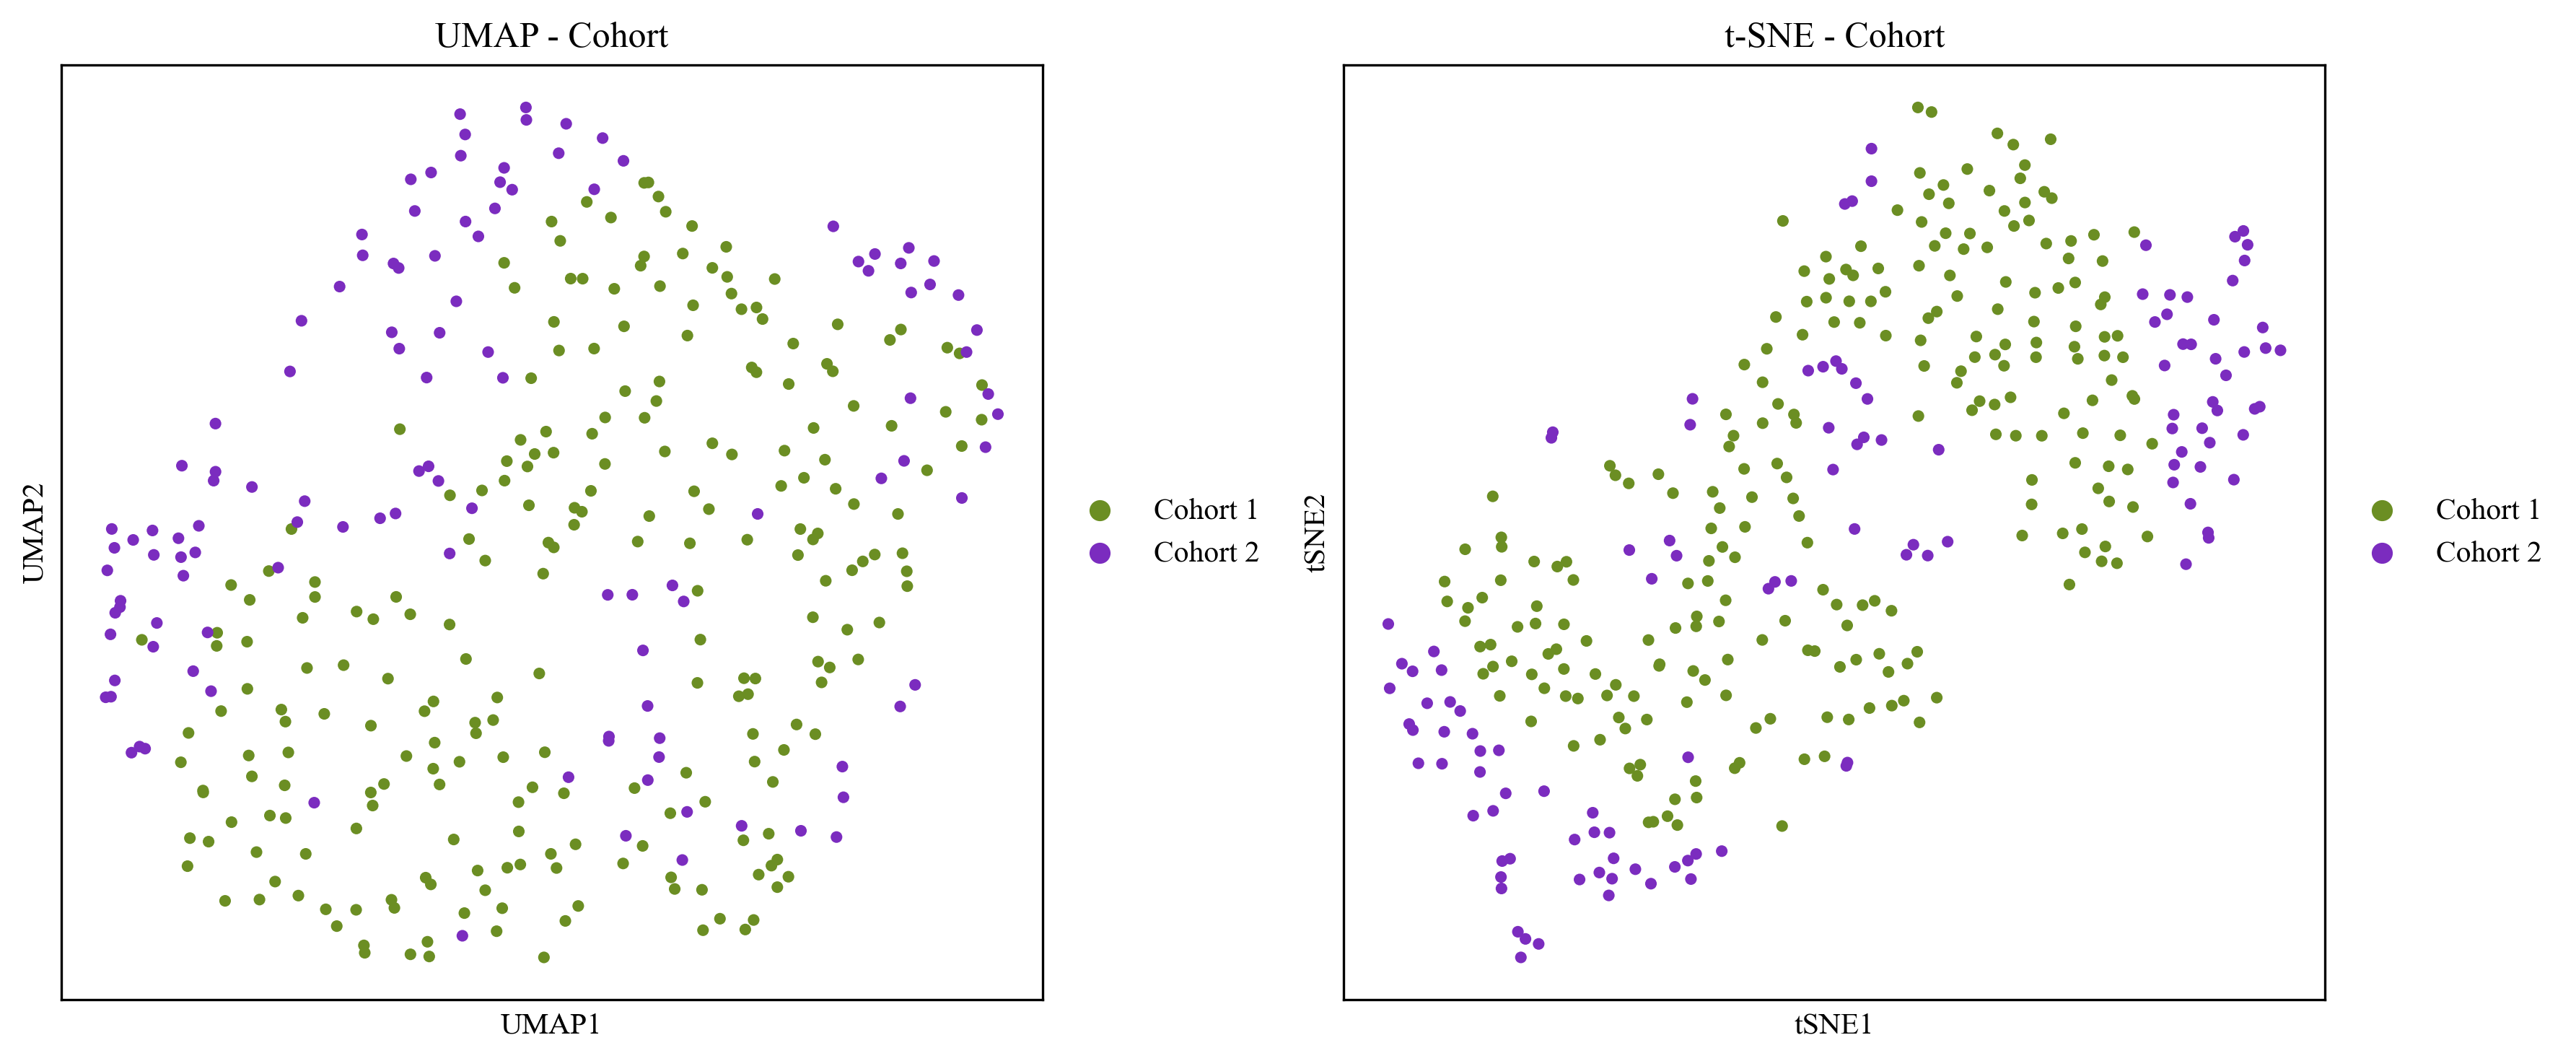

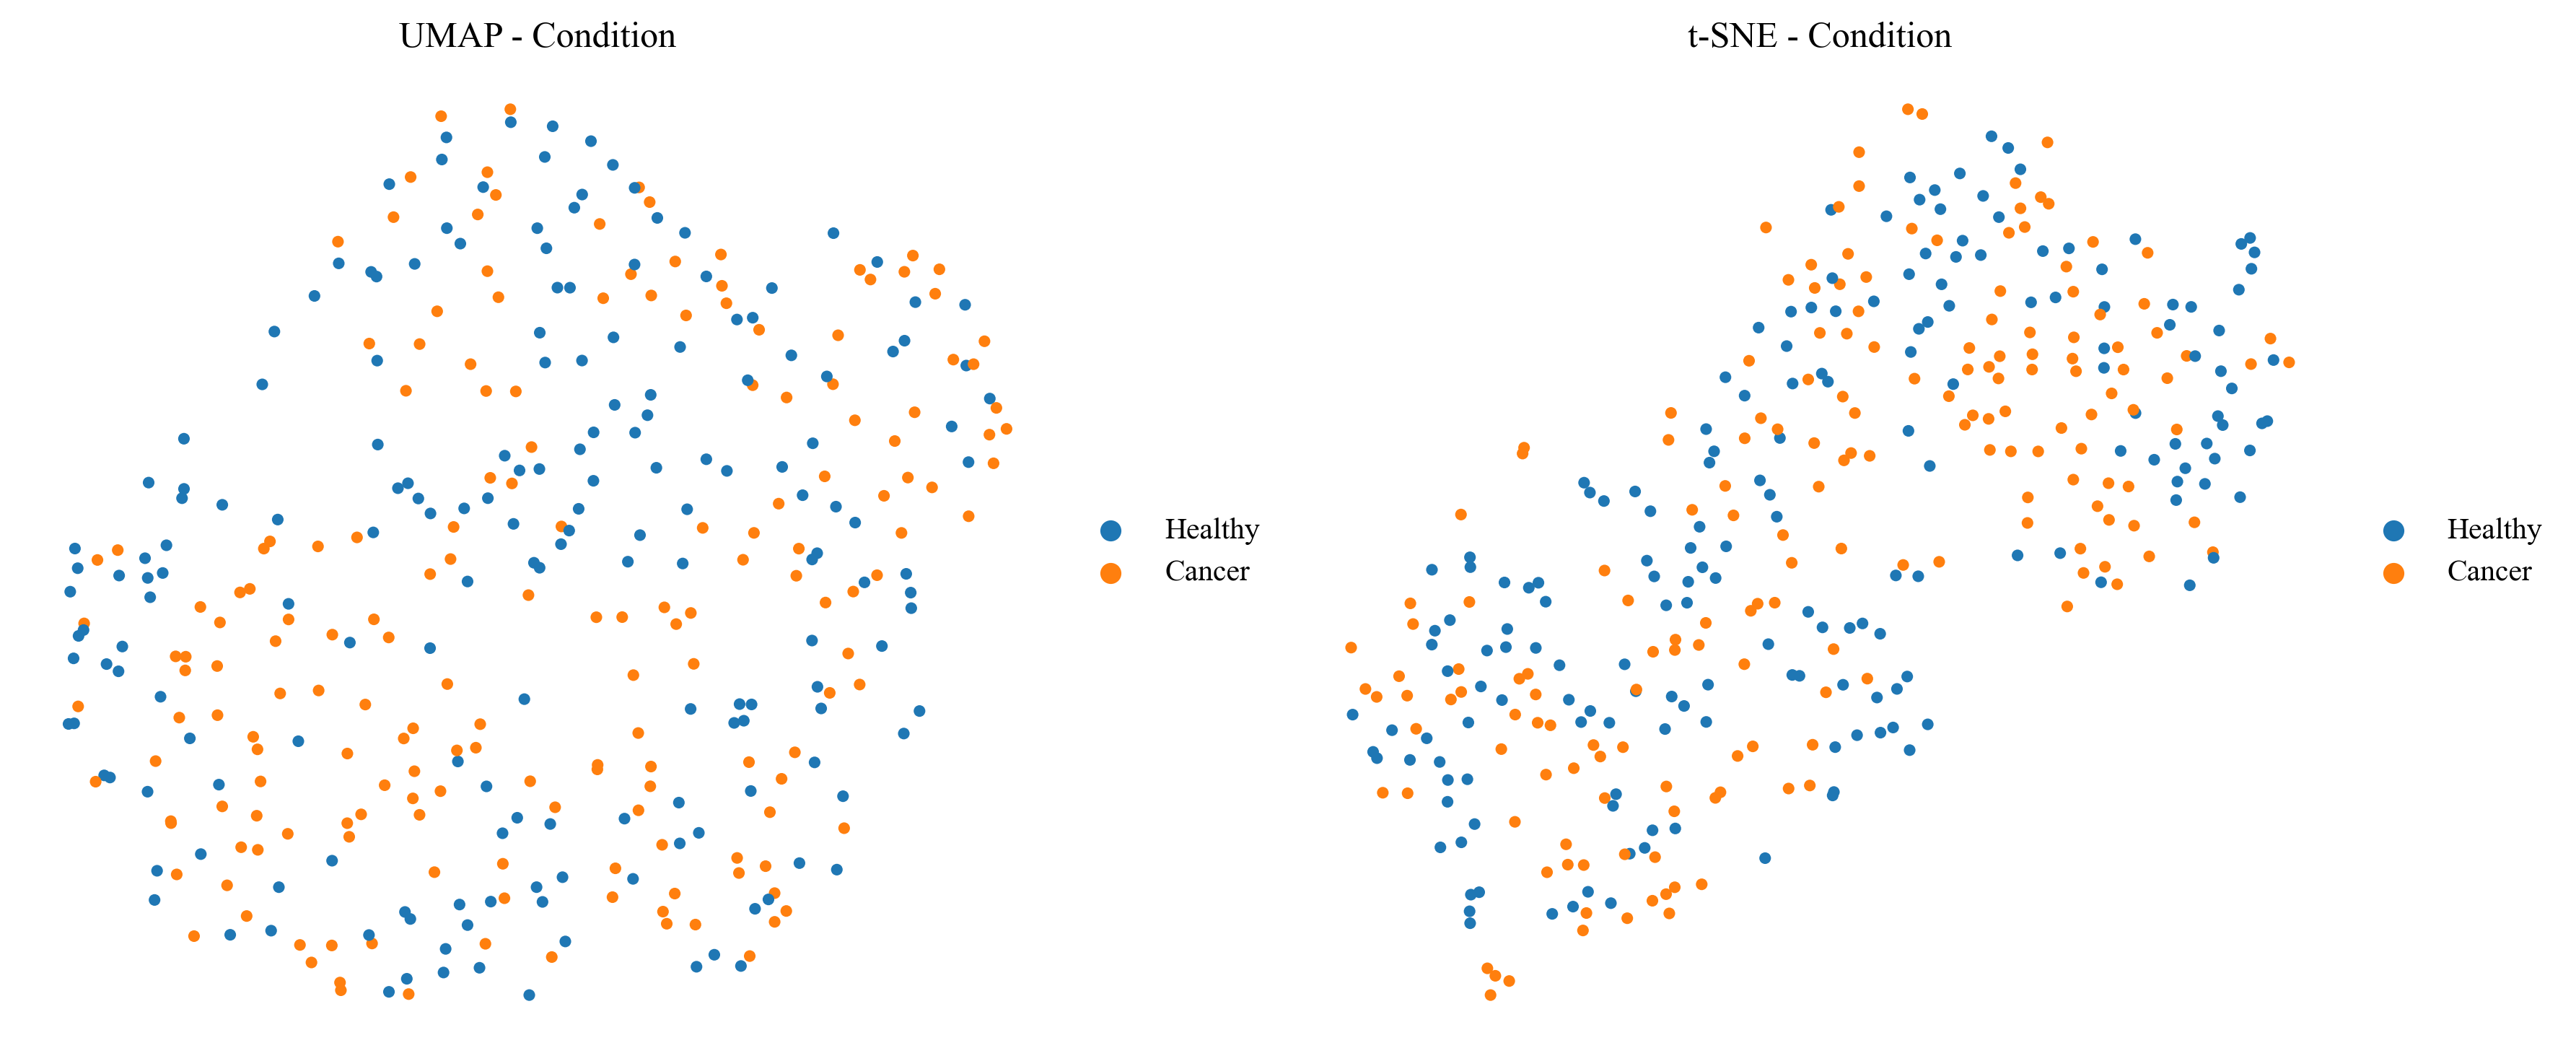

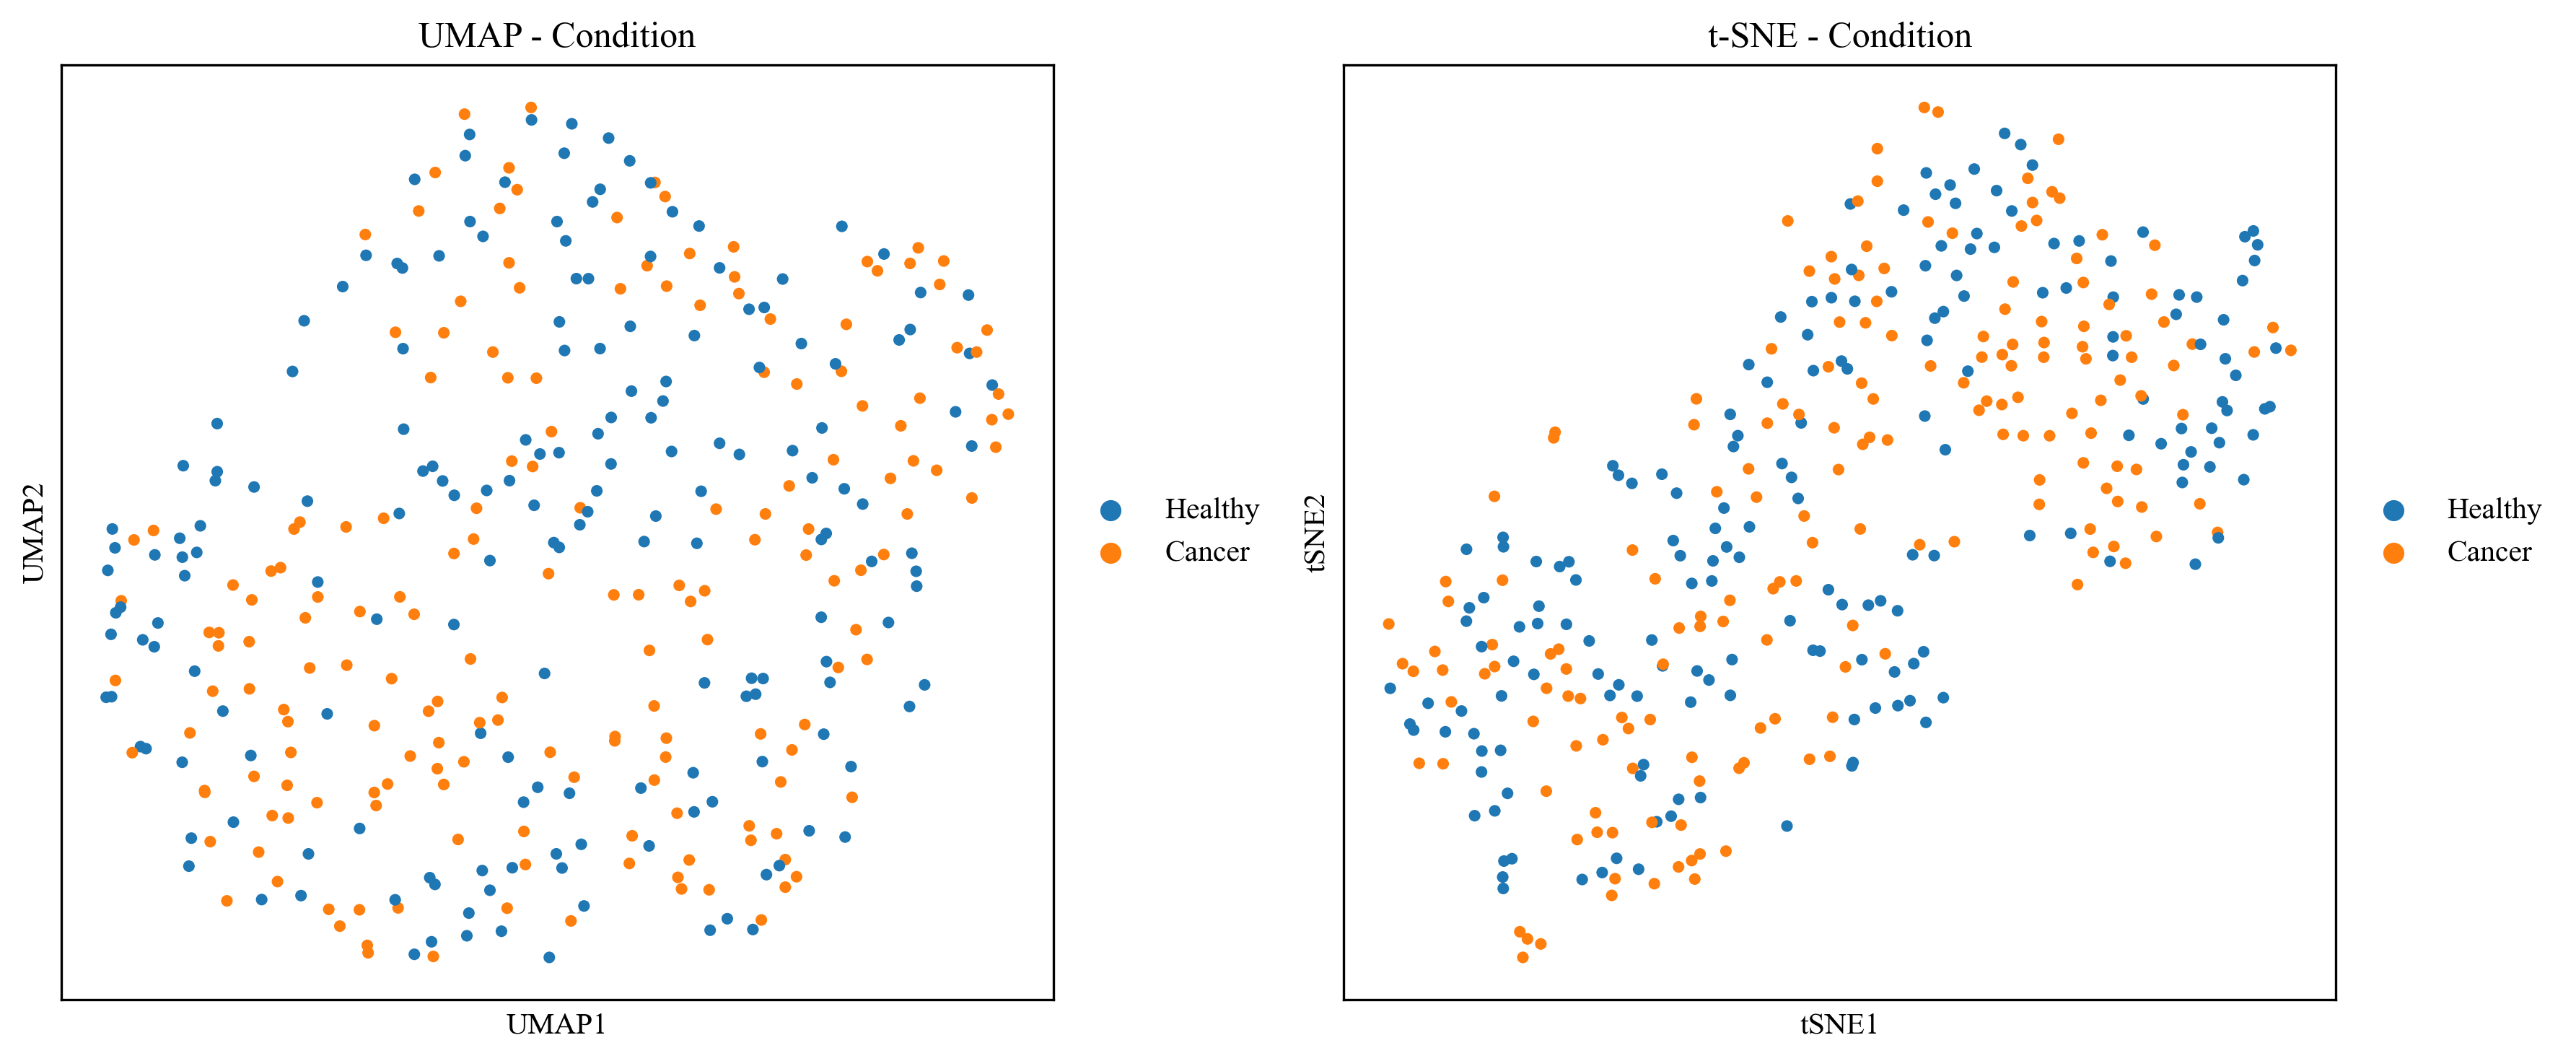

In [25]:
def plot_after_integration(adata_integrated, point_size=60):

    adata_integrated_ = adata_integrated.copy()
    # WZ/ZJT/SCC
    # -------------------------------------------------
    # Rename cohort labels for nicer legends
    # -------------------------------------------------
    # cohort_mapping = {
    #     "1": "ZJC Cohort",
    #     "2": "Multi-center Cohort"
    # }

    cohort_mapping = {
        "1": "Cohort 1",
        "2": "Cohort 2"
    }

    adata_integrated_.obs["cohort"] = (
        adata_integrated_.obs["cohort"]
        .astype(str)
        .map(cohort_mapping)
    )

    # ----------------------------
    # UMAP
    # ----------------------------
    def run_umap_on_raw(adata):
        adata_raw = adata.copy()
        sc.pp.neighbors(adata_raw, use_rep="X", random_state=0)
        sc.tl.umap(adata_raw, random_state=0)
        return adata_raw

    # ----------------------------
    # t-SNE
    # ----------------------------
    def run_tsne_on_raw(adata):
        adata_tsne = adata.copy()
        sc.tl.tsne(adata_tsne, use_rep="X", random_state=0)
        return adata_tsne

    adata_umap = run_umap_on_raw(adata_integrated_)
    adata_tsne = run_tsne_on_raw(adata_integrated_)

    # -------------------------------------------------
    # Generic plotting function
    # -------------------------------------------------
    def make_plot(
        color_by,
        frameon,
        save_name,
        dpi_save=1200,
        dpi_display=300
    ):

        fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=dpi_display)

        # -------------------------------------------------
        # Cohort plots with custom palette
        # -------------------------------------------------
        if color_by == "cohort":

            palette = ["#6B8E23", "#7B2CBF"] # darker purple/green
            # palette = ["#2596be", "#aa00ba"]


            # UMAP
            sc.pl.umap(
                adata_umap,
                color="cohort",
                palette=palette,
                ax=axes[0],
                show=False,
                title="UMAP - Cohort",
                size=point_size,
                frameon=frameon
            )

            # t-SNE
            sc.pl.tsne(
                adata_tsne,
                color="cohort",
                palette=palette,
                ax=axes[1],
                show=False,
                title="t-SNE - Cohort",
                size=point_size,
                frameon=frameon
            )

        # -------------------------------------------------
        # Label plots with Scanpy default colors
        # -------------------------------------------------
        elif color_by == "label":

            # UMAP
            sc.pl.umap(
                adata_umap,
                color="label",
                ax=axes[0],
                show=False,
                title="UMAP - Condition",
                size=point_size,
                frameon=frameon
            )

            # t-SNE
            sc.pl.tsne(
                adata_tsne,
                color="label",
                ax=axes[1],
                show=False,
                title="t-SNE - Condition",
                size=point_size,
                frameon=frameon
            )

        plt.tight_layout()

        plt.savefig(
            join(figures_path, save_name),
            dpi=dpi_save,
            bbox_inches="tight"
        )

        plt.show()
        plt.close(fig)

    # -------------------------------------------------
    # 1. Cohort frameless
    # -------------------------------------------------
    make_plot(
        color_by="cohort",
        frameon=False,
        save_name="plot3_after_integration_by_cohort_frameless2.png"
    )

    # -------------------------------------------------
    # 2. Cohort framed
    # -------------------------------------------------
    make_plot(
        color_by="cohort",
        frameon=True,
        save_name="plot3_after_integration_by_cohort_framed2.png"
    )

    # -------------------------------------------------
    # 3. Label frameless
    # -------------------------------------------------
    make_plot(
        color_by="label",
        frameon=False,
        save_name="plot3_after_integration_by_label_frameless2.png"
    )

    # -------------------------------------------------
    # 4. Label framed
    # -------------------------------------------------
    make_plot(
        color_by="label",
        frameon=True,
        save_name="plot3_after_integration_by_label_framed2.png"
    )


plot_after_integration(adata_integrated)

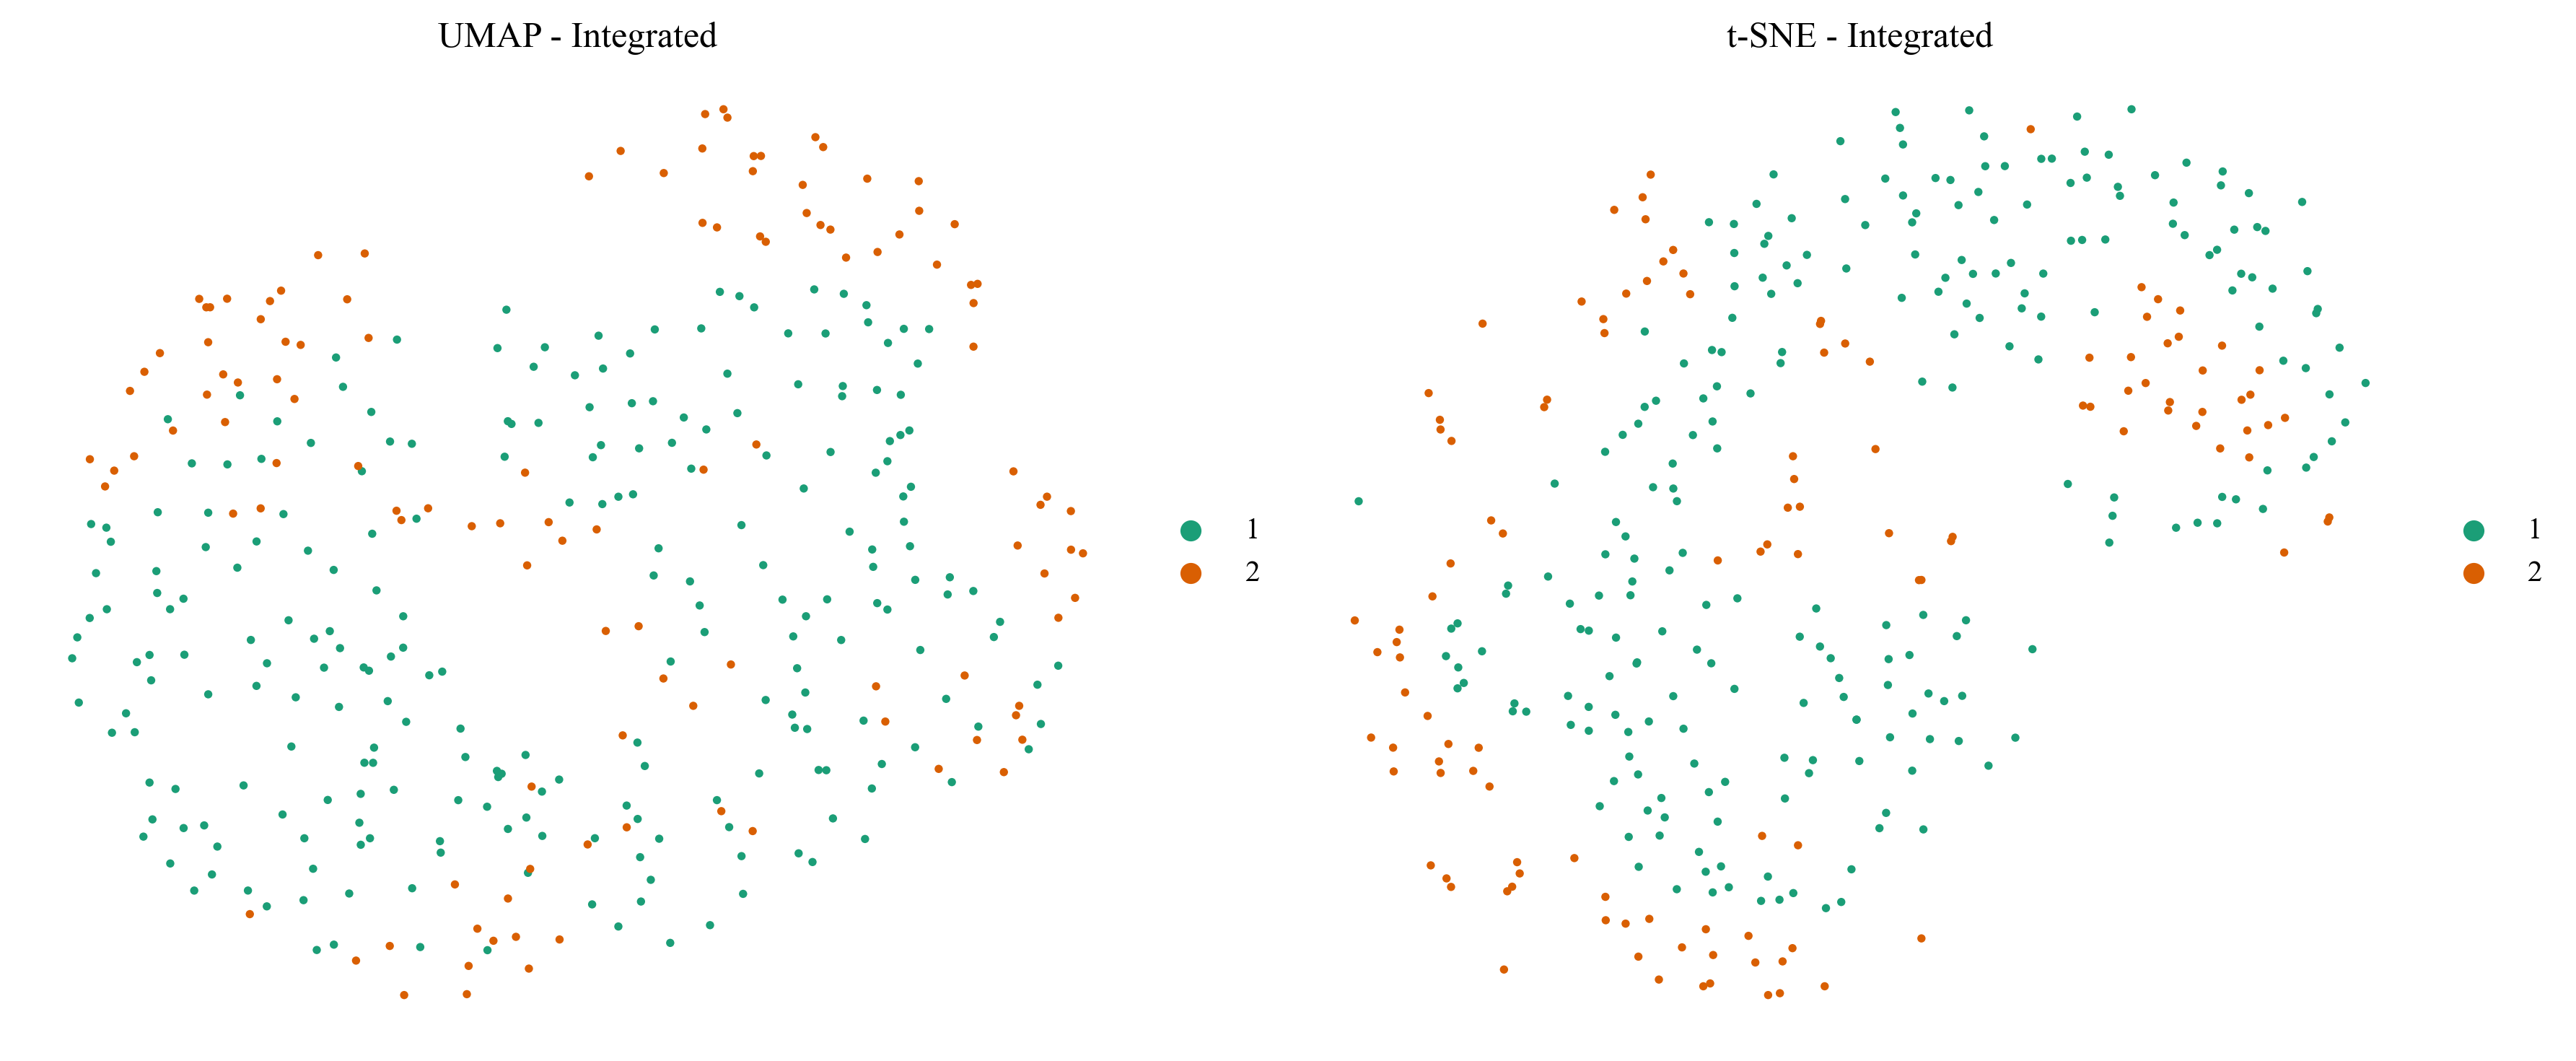

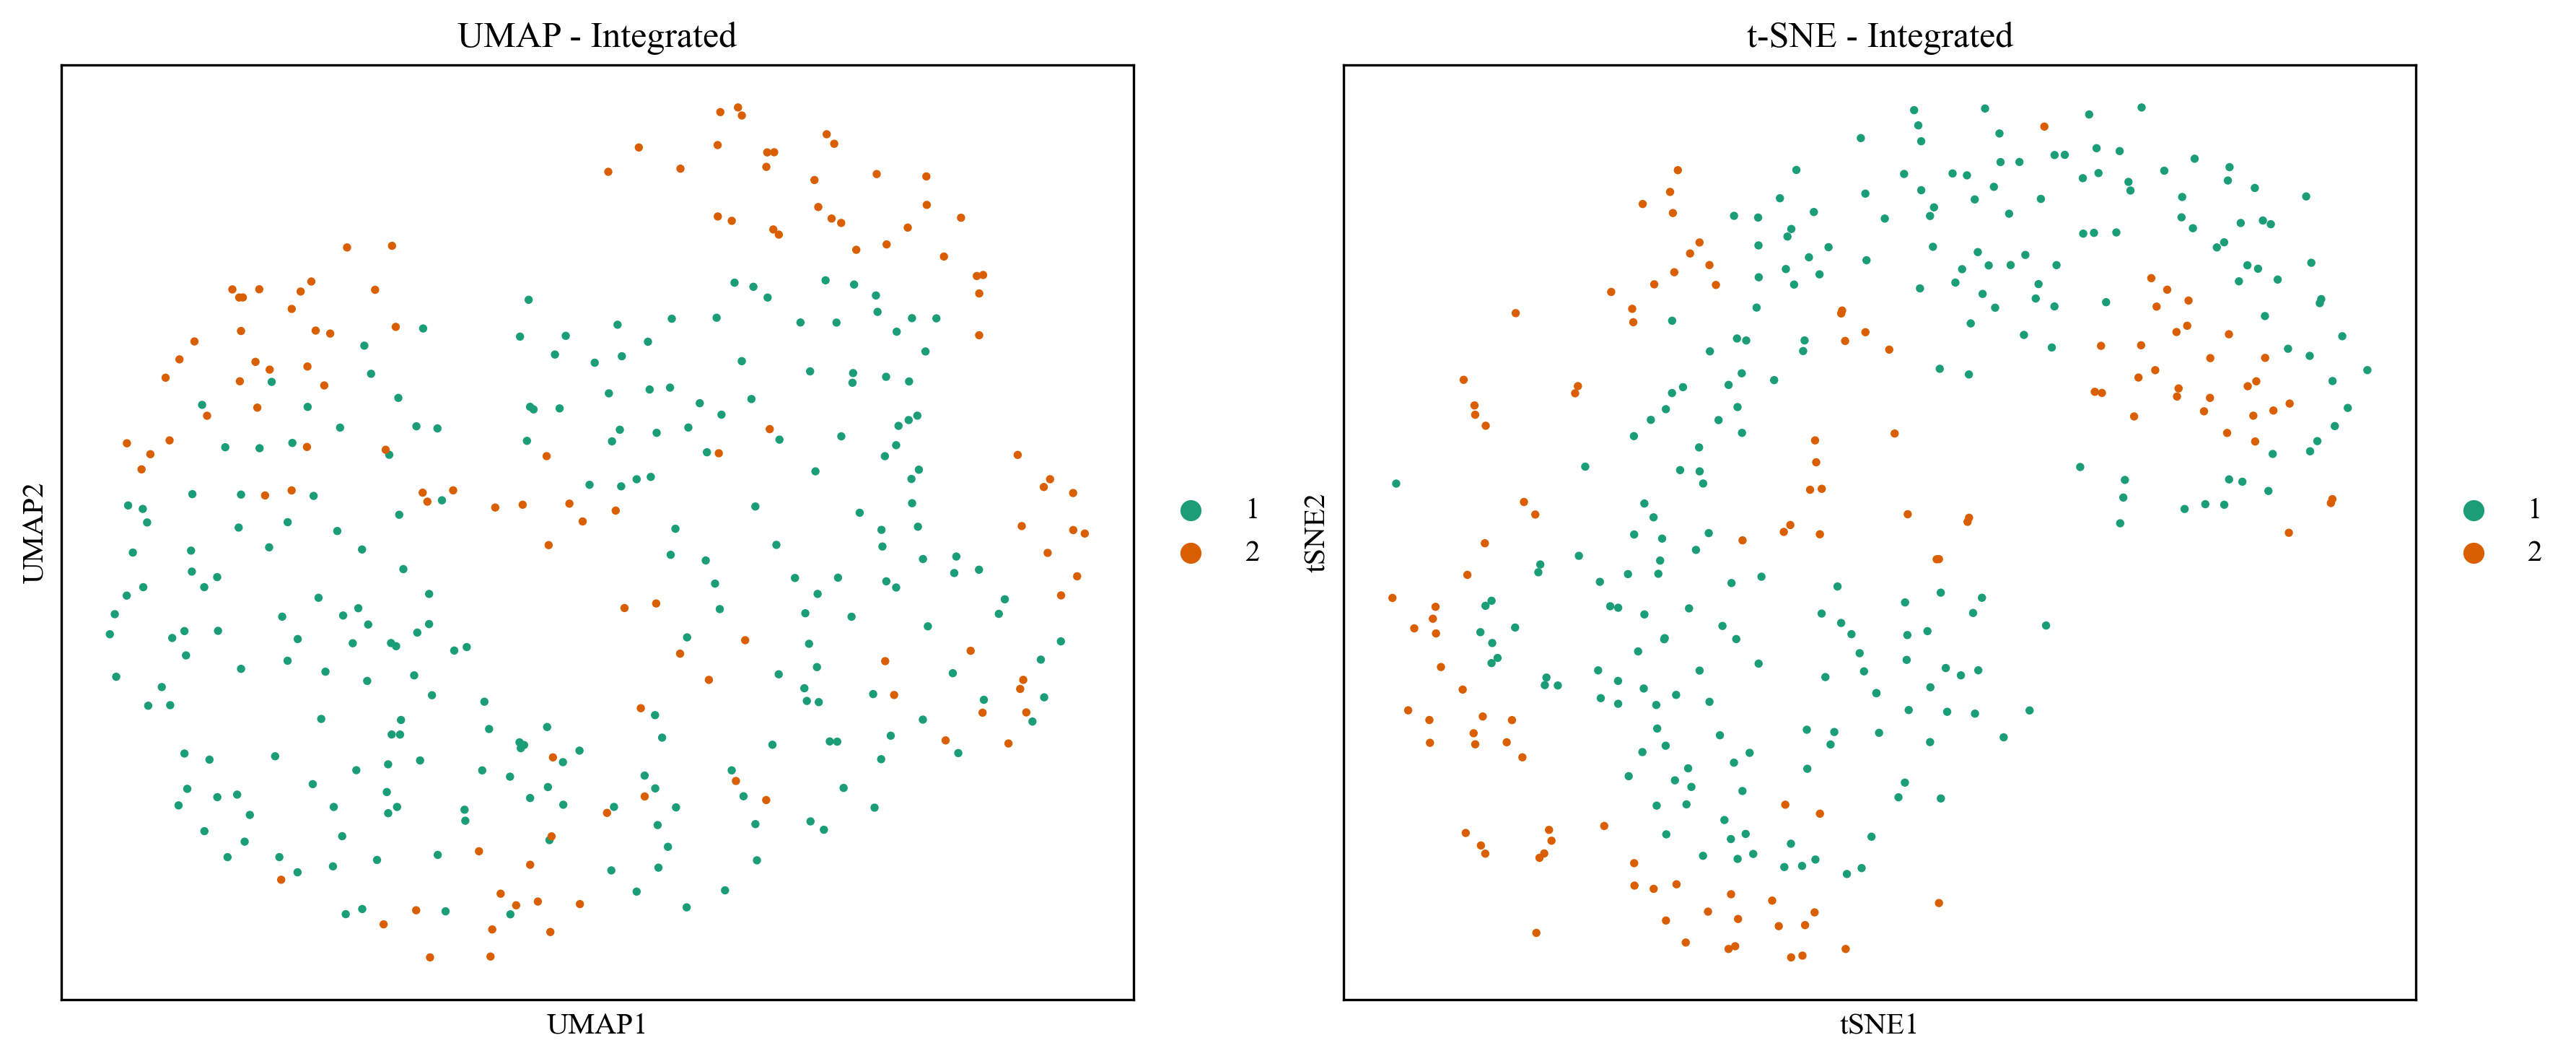

In [ ]:
# def plot_after_integration(adata_integrated, point_size=60):

#     adata_integrated_ = adata_integrated.copy()

#     # ----------------------------
#     # UMAP
#     # ----------------------------
#     def run_umap_on_raw(adata):
#         adata_raw = adata.copy()
#         sc.pp.neighbors(adata_raw, use_rep="X", random_state=0)
#         sc.tl.umap(adata_raw, random_state=0)
#         return adata_raw

#     # ----------------------------
#     # t-SNE
#     # ----------------------------
#     def run_tsne_on_raw(adata):
#         adata_tsne = adata.copy()
#         sc.tl.tsne(adata_tsne, use_rep="X", random_state=0)
#         return adata_tsne

#     adata_umap = run_umap_on_raw(adata_integrated_)
#     adata_tsne = run_tsne_on_raw(adata_integrated_)

#     # ----------------------------
#     # Plot function (reusable)
#     # ----------------------------
#     def make_plot(frameon, dpi_save, suffix, dpi_display=300,):

#         fig, axes = plt.subplots(1, 2, figsize=(12, 5), dpi=dpi_display)

#         # UMAP
#         sc.pl.umap(
#             adata_umap,
#             palette=["#6B8E23", "#7B2CBF"],
#             color="cohort",
#             ax=axes[0],
#             show=False,
#             title="UMAP - Integrated",
#             size=point_size,
#             frameon=frameon
#         )

#         # t-SNE
#         sc.pl.tsne(
#             adata_tsne,
#             palette=["#6B8E23", "#7B2CBF"],
#             color="cohort",
#             ax=axes[1],
#             show=False,
#             title="t-SNE - Integrated",
#             size=point_size,
#             frameon=frameon
#         )

#         plt.tight_layout()

#         plt.savefig(
#             join(figures_path, f"plot3_after_integration_{suffix}.png"),
#             dpi=dpi_save,
#             bbox_inches="tight"
#         )

#         plt.show()
#         plt.close(fig)

#     # ----------------------------
#     # Frameless version
#     # ----------------------------
#     make_plot(
#         frameon=False,
#         dpi_save=1200,
#         suffix="frameless"
#     )

#     # ----------------------------
#     # Framed version
#     # ----------------------------
#     make_plot(
#         frameon=True,
#         dpi_save=1200,
#         suffix="framed"
#     )

# plot_after_integration(adata_integrated)

## Plot 4 - Multiple After Integration

    SGD-MDS may not have converged: stress changed by 6.0% in final iterations. Consider increasing n_iter or adjusting learning_rate.


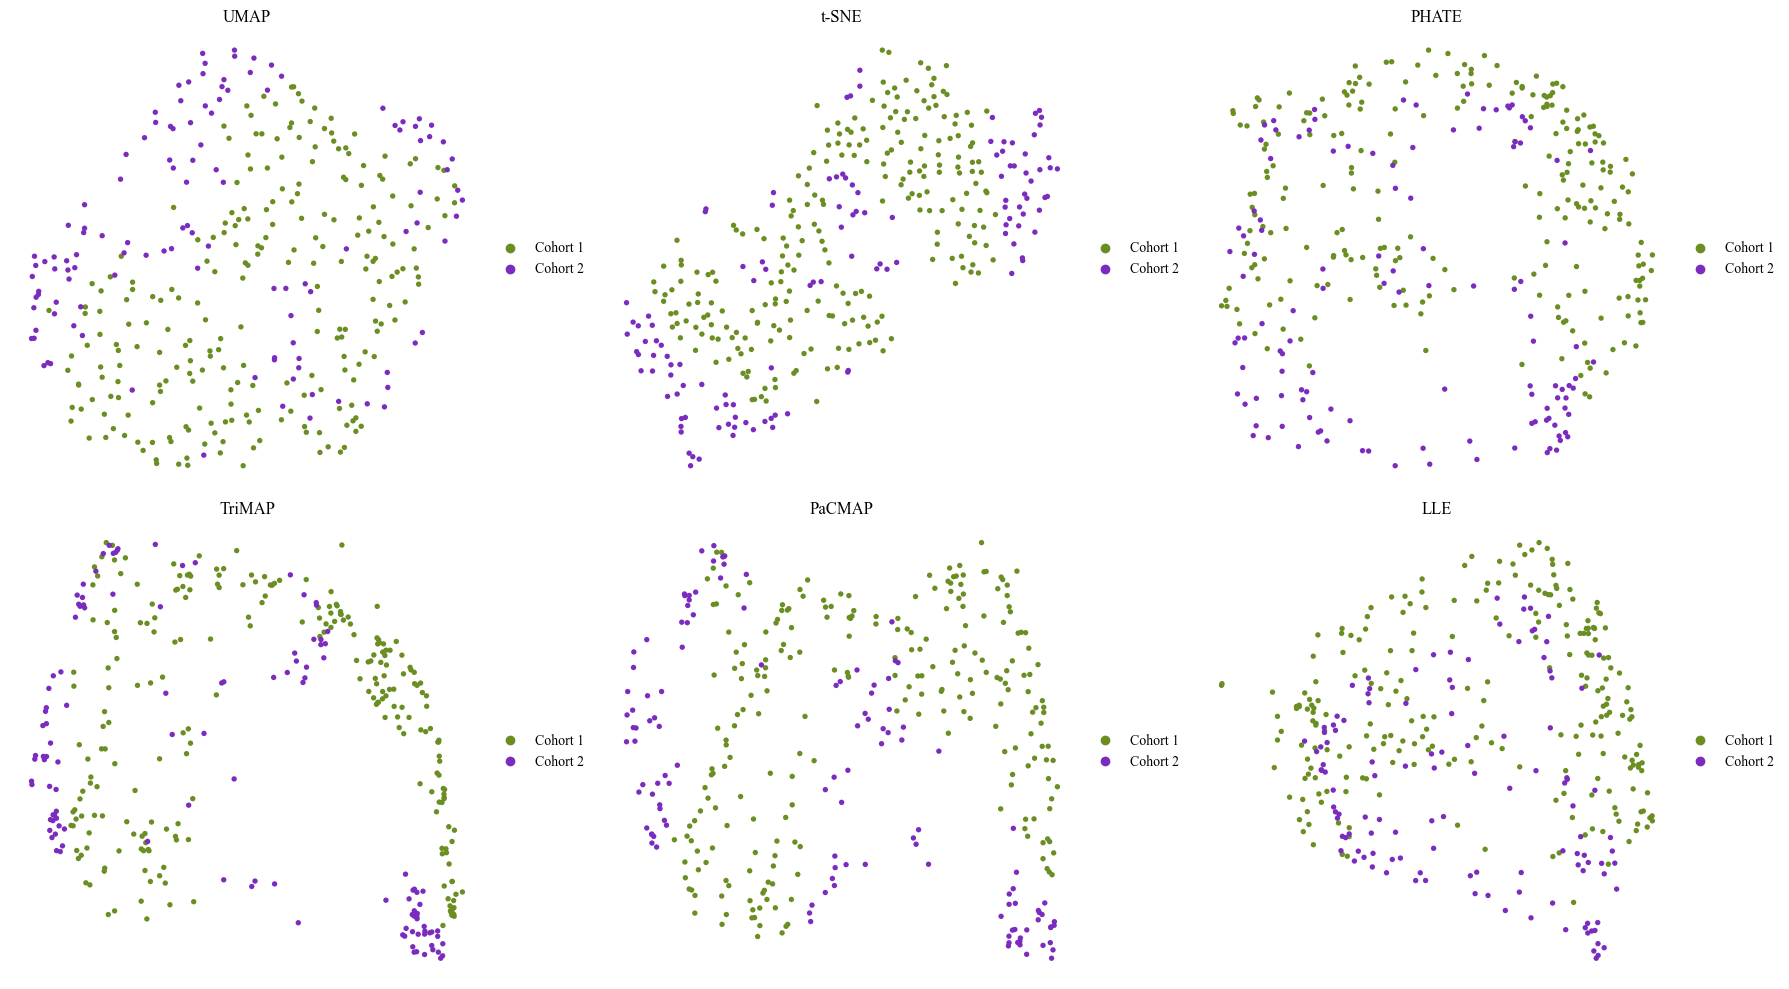

In [46]:
def plot_multiple_after_integration(adata, point_size=60, random_state=0):

    adata_ = adata.copy()

    # ---------------------------------------------------
    # Cohort relabeling
    # ---------------------------------------------------
    cohort_mapping = {
        "1": "Cohort 1",
        "2": "Cohort 2"
    }

    adata_.obs["cohort"] = adata_.obs["cohort"].astype(str).map(cohort_mapping)

    # -------------------------------
    # UMAP
    # -------------------------------
    adata_umap = adata_.copy()
    sc.pp.neighbors(adata_umap, use_rep="X")
    sc.tl.umap(adata_umap, random_state=random_state)

    # -------------------------------
    # t-SNE
    # -------------------------------
    adata_tsne = adata_.copy()
    sc.tl.tsne(adata_tsne, use_rep="X", random_state=random_state)

    # -------------------------------
    # PHATE
    # -------------------------------
    adata_phate = adata_.copy()
    phate_op = phate.PHATE(n_components=2, n_jobs=-1, random_state=random_state, verbose=False)
    adata_phate.obsm["X_phate"] = phate_op.fit_transform(adata_phate.X)

    # -------------------------------
    # TriMAP
    # -------------------------------
    adata_trimap = adata_.copy()
    trimap_op = trimap.TRIMAP(n_dims=2)
    adata_trimap.obsm["X_trimap"] = trimap_op.fit_transform(adata_trimap.X)

    # -------------------------------
    # PaCMAP
    # -------------------------------
    adata_pacmap = adata_.copy()
    pacmap_op = pacmap.PaCMAP(n_components=2, random_state=random_state, verbose=False)
    adata_pacmap.obsm["X_pacmap"] = pacmap_op.fit_transform(adata_pacmap.X)

    # -------------------------------
    # LLE
    # -------------------------------
    adata_lle = adata_.copy()
    lle_op = LocallyLinearEmbedding(n_components=2, random_state=random_state)
    adata_lle.obsm["X_lle"] = lle_op.fit_transform(adata_lle.X)

    embeddings = [
        ("UMAP", adata_umap, "X_umap"),
        ("t-SNE", adata_tsne, "X_tsne"),
        ("PHATE", adata_phate, "X_phate"),
        ("TriMAP", adata_trimap, "X_trimap"),
        ("PaCMAP", adata_pacmap, "X_pacmap"),
        ("LLE", adata_lle, "X_lle"),
    ]

    # ---------------------------------------------------
    # plotting helper
    # ---------------------------------------------------
    def make_grid(color_by, frameon, save_name):

        fig, axes = plt.subplots(2, 3, figsize=(18, 10))
        axes = axes.flatten()

        # Cohort-specific palette (ONLY here)
        cohort_palette = ["#6B8E23", "#7B2CBF"]

        for i, (name, ad, key) in enumerate(embeddings):

            sc.pl.embedding(
                ad,
                basis=key,
                color=color_by,
                ax=axes[i],
                show=False,
                title=name,
                size=point_size,
                frameon=frameon,
                palette=cohort_palette if color_by == "cohort" else None
            )

        plt.tight_layout()

        plt.savefig(
            join(figures_path, save_name),
            dpi=1200,
            bbox_inches="tight"
        )

        plt.show()
        plt.close(fig)

    # ---------------------------------------------------
    # 1 Cohort frameless
    # ---------------------------------------------------
    make_grid("cohort", False, "plot4_multiple_after_integration_by_cohort_framelessa.png")

    # 2 Cohort framed
    make_grid("cohort", True, "plot4_multiple_after_integration_by_cohort_framed.png")

    # 3 Label frameless
    make_grid("label", False, "plot4_multiple_after_integration_by_label_frameless.png")

    # 4 Label framed
    make_grid("label", True, "plot4_multiple_after_integration_by_label_framed.png")


plot_multiple_after_integration(adata_integrated)

    SGD-MDS may not have converged: stress changed by 6.9% in final iterations. Consider increasing n_iter or adjusting learning_rate.


True


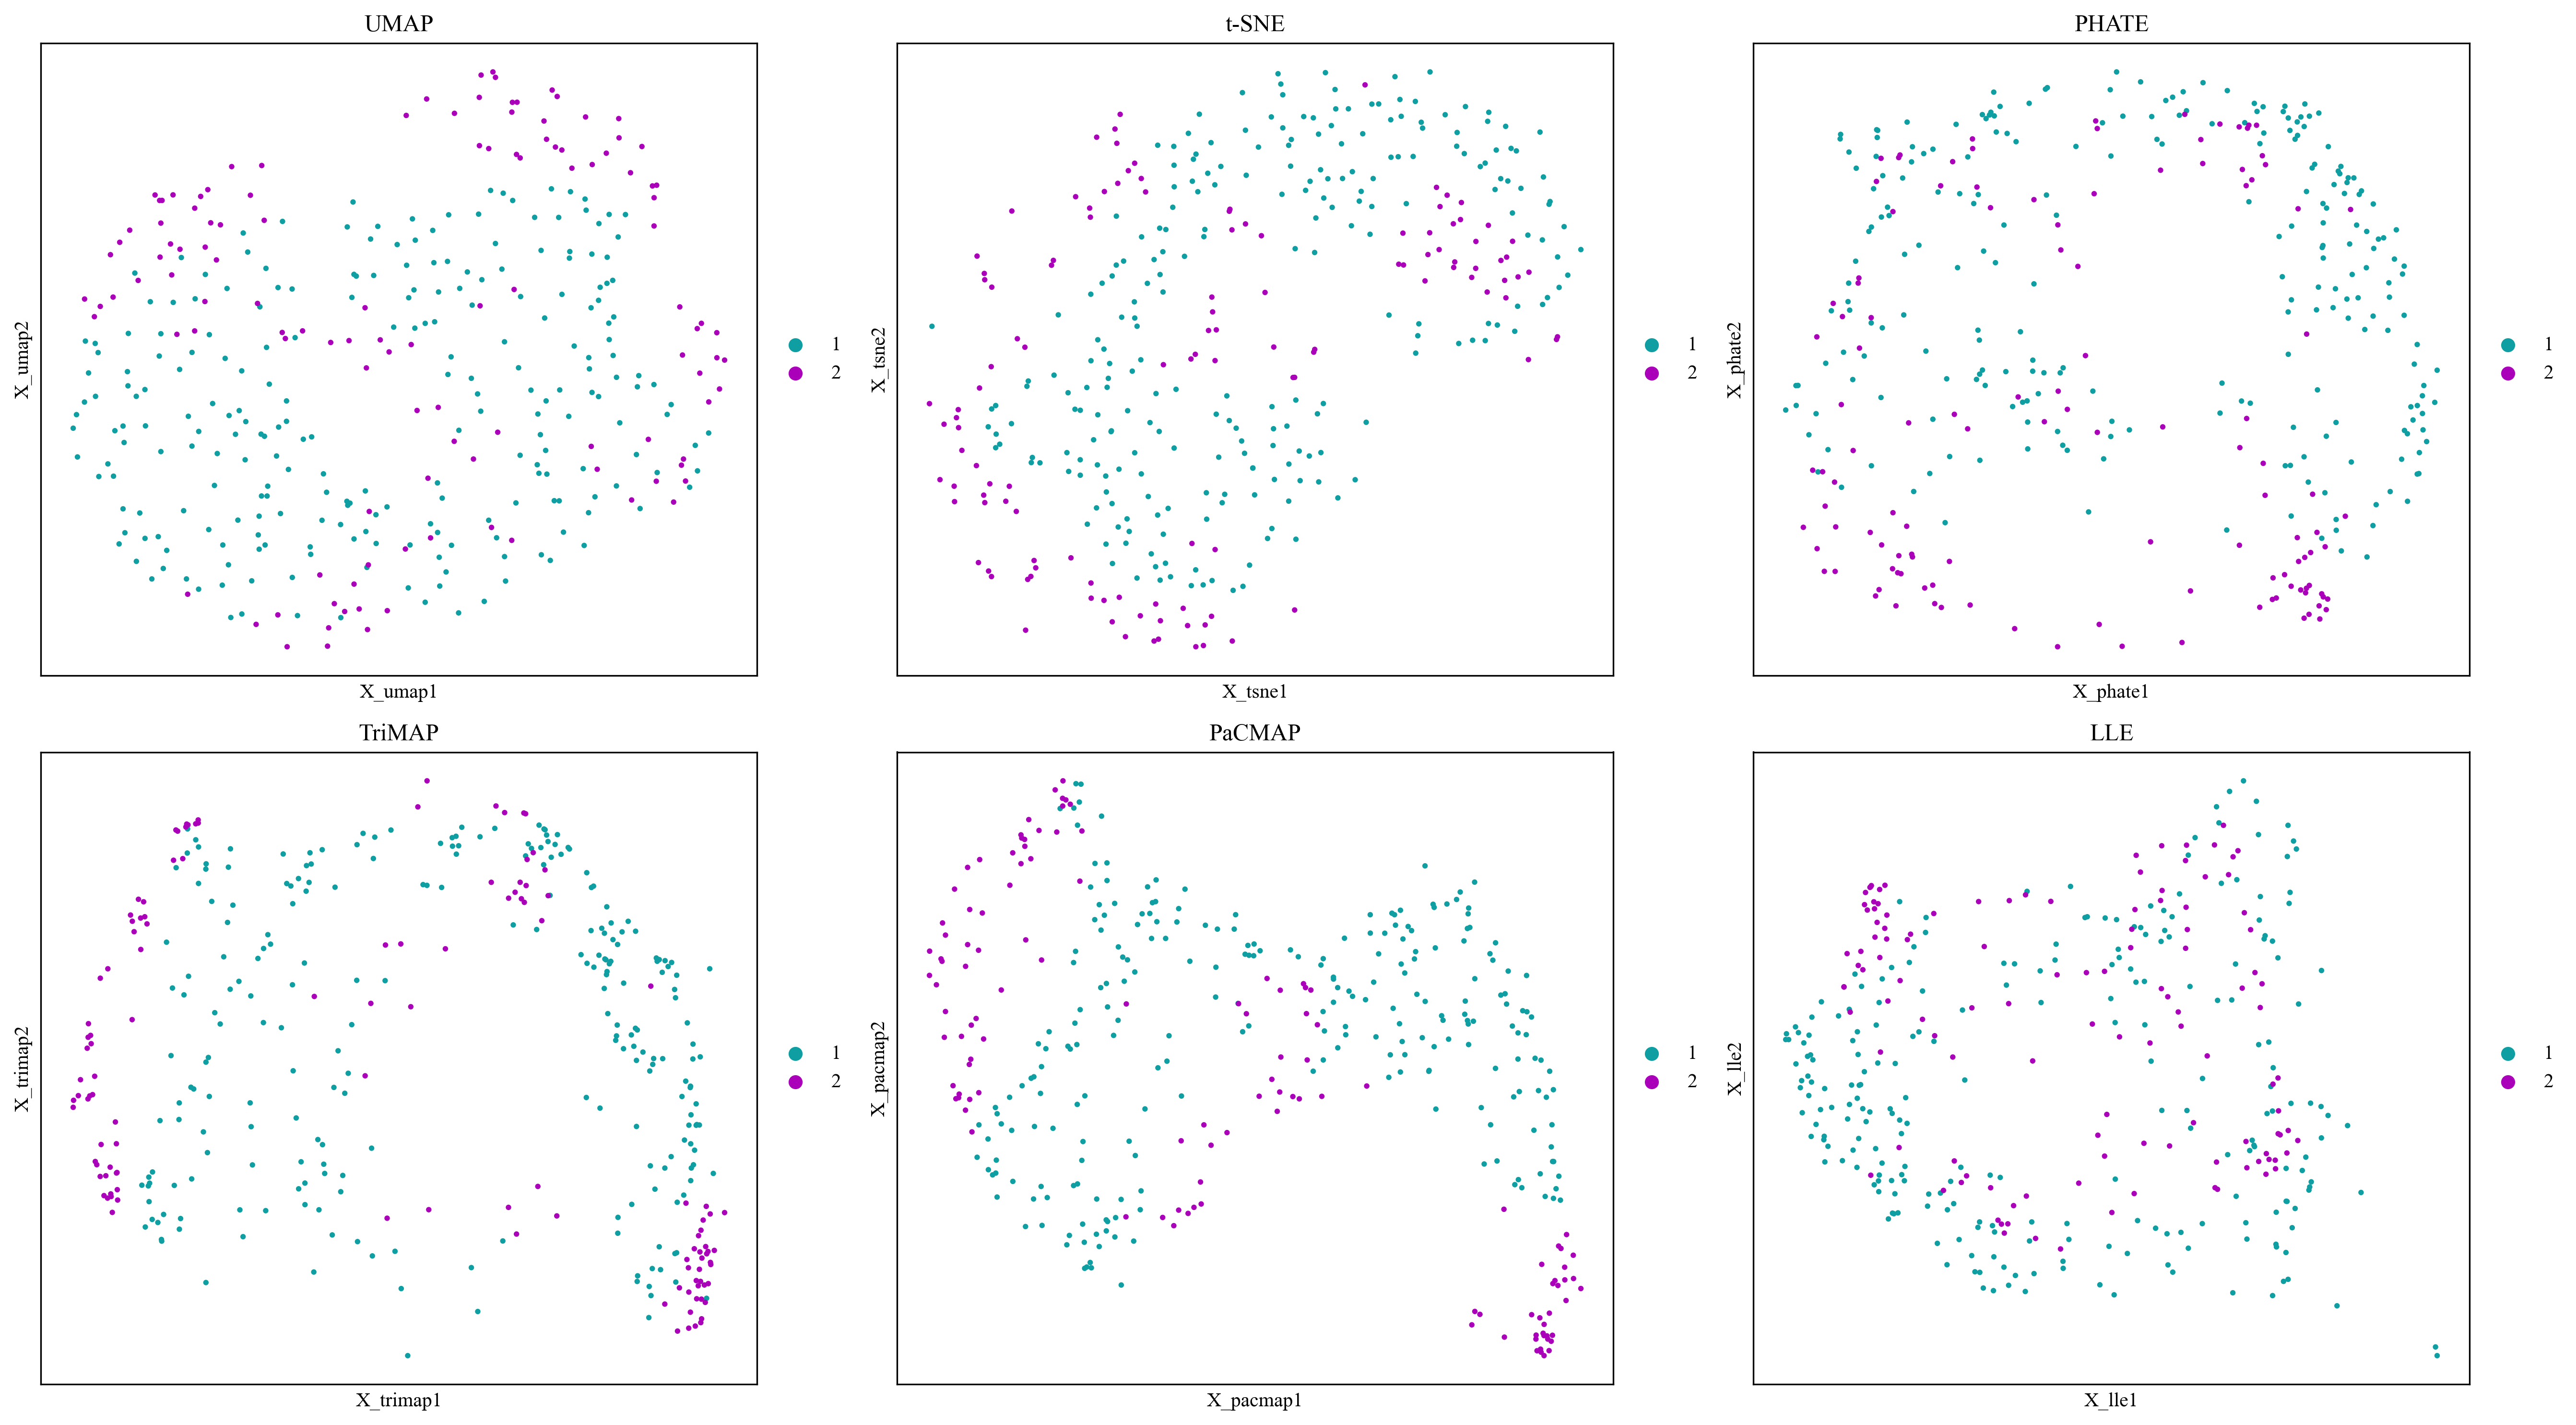

In [ ]:
# def plot_multiple_by_cohort_after_integration(adata, point_size=40, random_state=0, color="batch"):
#     """
#     Plot embeddings: UMAP, t-SNE, PHATE, TriMAP, PaCMAP, and LLE
#     in a 2x3 grid layout using normalized/log1p/scaled preprocessing.
#     """
#     adata_ = adata.copy()

#     # -------------------------------
#     # UMAP
#     # -------------------------------
#     adata_umap = adata_.copy()
#     sc.pp.neighbors(adata_umap, use_rep="X")
#     sc.tl.umap(adata_umap, random_state=random_state)

#     # -------------------------------
#     # t-SNE
#     # -------------------------------
#     adata_tsne = adata_.copy()
#     sc.tl.tsne(adata_tsne, use_rep="X", random_state=random_state)

#     # -------------------------------
#     # PHATE
#     # -------------------------------
#     adata_phate = adata_.copy()
#     phate_op = phate.PHATE(n_components=2, n_jobs=-1, random_state=random_state, verbose=False)
#     adata_phate.obsm["X_phate"] = phate_op.fit_transform(adata_phate.X)

#     # -------------------------------
#     # TriMAP
#     # -------------------------------
#     adata_trimap = adata_.copy()
#     trimap_op = trimap.TRIMAP(n_dims=2)
#     adata_trimap.obsm["X_trimap"] = trimap_op.fit_transform(adata_trimap.X)

#     # -------------------------------
#     # PaCMAP
#     # -------------------------------
#     adata_pacmap = adata_.copy()
#     pacmap_op = pacmap.PaCMAP(n_components=2, random_state=random_state, verbose=False)
#     adata_pacmap.obsm["X_pacmap"] = pacmap_op.fit_transform(adata_pacmap.X)

#     # -------------------------------
#     # LLE
#     # -------------------------------
#     adata_lle = adata_.copy()
#     lle_op = LocallyLinearEmbedding(n_components=2, random_state=random_state)
#     adata_lle.obsm["X_lle"] = lle_op.fit_transform(adata_lle.X)

#     # -------------------------------
#     # Plot embeddings in 2x3 grid
#     # -------------------------------
#     embeddings = [
#         ("UMAP", adata_umap, "X_umap"),
#         ("t-SNE", adata_tsne, "X_tsne"),
#         ("PHATE", adata_phate, "X_phate"),
#         ("TriMAP", adata_trimap, "X_trimap"),
#         ("PaCMAP", adata_pacmap, "X_pacmap"),
#         ("LLE", adata_lle, "X_lle"),
#     ]

#     fig, axes = plt.subplots(2, 3, figsize=(18, 10))
#     axes = axes.flatten()

#     for i, (name, ad, key) in enumerate(embeddings):
#         sc.pl.embedding(
#             ad,
#             basis=key,
#             color=color,
#             ax=axes[i],
#             show=False,
#             title=name,
#             size=point_size
#         )

#     plt.tight_layout()
#     plt.show()


# plot_multiple_by_cohort_after_integration(adata_integrated, color="cohort")
# adata_head(adata_integrated, name="Merged Adata")

## Benchmark Batch Correction Methods

In [34]:
pandas2ri.activate()

# ============================================================
#  FIXED R-LIMMA INSTALLATION (NON-INTERACTIVE)
# ============================================================

def ensure_limma_installed_noninteractive():
    """
    Ensures limma is installed in a fully non-interactive way.
    Avoids chooseCRANmirror() and any user prompts.
    """
    try:
        # Set CRAN mirror explicitly
        ro.r('options(repos = c(CRAN = "https://cloud.r-project.org"))')

        utils = importr('utils')
        installed = list(ro.r("rownames(installed.packages())"))

        # Install BiocManager if missing
        if "BiocManager" not in installed:
            utils.install_packages("BiocManager")

        biocmanager = importr("BiocManager")

        # Install limma (non-interactive)
        if "limma" not in installed:
            print("Installing limma...")
            biocmanager.install("limma", ask=False)

        limma = importr("limma")
        print("✔ limma successfully loaded")
        return True, limma

    except Exception as e:
        print("✘ Could not install/load limma:", e)
        return False, e


HAS_LIMMA, LIMMA_OBJ = ensure_limma_installed_noninteractive()


# ============================================================
#  LIMMA BATCH-CORRECTION WRAPPER
# ============================================================

def run_limma_batch_removal(adata, batch_key="batch"):
    """
    Apply limma::removeBatchEffect via rpy2.
    Only batch removal logic is included, nothing else changed.
    """
    if not HAS_LIMMA:
        raise RuntimeError("limma not available. Cannot run limma correction.")

    X = np.asarray(adata.X)
    X_t = X.T  # limma expects features × samples

    df = pd.DataFrame(X_t, index=adata.var_names, columns=adata.obs_names)
    r_df = pandas2ri.py2rpy(df)

    batch_vals = adata.obs[batch_key].astype(str).values
    r_batch = ro.FactorVector(batch_vals)

    limma = LIMMA_OBJ
    corrected_r = limma.removeBatchEffect(r_df, batch=r_batch)

    corrected_np = np.array(corrected_r).T
    return corrected_np


# ============================================================
#  BENCHMARK BATCH CORRECTION (YOUR ORIGINAL PIPELINE)
# ============================================================

def benchmark_batch_correction_methods(
    adata,
    batch_key="batch",
    label_key="label",
    n_jobs=-1,
    show_plot=True,
    random_state=0,
):
    """
    Benchmark corrections: Untouched, ComBat, Limma, MNN.
    EXACTLY your logic — ComBat and MNN are NOT modified.
    """

    adata_bench = adata.copy()

    # ------------------------------------------------
    # Untouched
    # ------------------------------------------------
    adata_bench.obsm["Untouched"] = np.asarray(adata_bench.X).copy()

    # ------------------------------------------------
    # ComBat (unchanged)
    # ------------------------------------------------
    adata_combat = adata_bench.copy()
    sc.pp.combat(adata_combat, key=batch_key)
    adata_bench.obsm["ComBat"] = np.asarray(adata_combat.X).copy()

    # ------------------------------------------------
    # Limma (only backend fixed)
    # ------------------------------------------------
    limma_corrected = run_limma_batch_removal(adata_bench, batch_key=batch_key)
    adata_bench.obsm["Limma"] = limma_corrected

    # ------------------------------------------------
    # MNN (unchanged)
    # ------------------------------------------------
    batch_categories = adata_bench.obs[batch_key].astype("category").cat.categories
    samples = [adata_bench[adata_bench.obs[batch_key] == b].copy() for b in batch_categories]

    mnn_res = mnnpy.mnn_correct(*samples)
    corrected_list = mnn_res[0] if isinstance(mnn_res, tuple) else mnn_res

    adata_mnn = (
        anndata.concat(corrected_list, axis=0, join="inner")
        if isinstance(corrected_list, list)
        else corrected_list
    )

    adata_mnn.obs[batch_key] = adata_mnn.obs[batch_key].astype("category")
    adata_bench.obsm["MNN"] = np.asarray(adata_mnn.X).copy()

    # ------------------------------------------------
    # Metrics (unchanged)
    # ------------------------------------------------

    bio = BioConservation(
        # Preserve biology: clustering-based agreements and label silhouette
        nmi_ari_cluster_labels_kmeans=False,   # optional for bulk; keep False to reduce computation
        nmi_ari_cluster_labels_leiden=True,    # compare clustering before/after -> useful
        silhouette_label=True,                 # sample-level silhouette by biological label
        isolated_labels=False,
        clisi_knn=False
    )

    batch = BatchCorrection(
        bras=True,                # include BRAS (silhouette-based batch removal metric)
        kbet_per_label=False,     # disable kBET (neighborhood-based)
        graph_connectivity=False, # disable graph connectivity (kNN-based)
        pcr_comparison=True       # include PCR / pcr_comparison
    )

    embedding_keys = ["Untouched", "ComBat", "Limma", "MNN"]

    bm = Benchmarker(
        adata_bench,
        batch_key=batch_key,
        label_key=label_key,
        embedding_obsm_keys=embedding_keys,
        bio_conservation_metrics=bio,
        batch_correction_metrics=batch,
        n_jobs=n_jobs,
    )

    bm.prepare()
    bm.benchmark()

    results_df = bm.get_results(min_max_scale=False, clean_names=True)
    results_df = results_df.loc[[k for k in embedding_keys if k in results_df.index]]

    if show_plot:
        # fig = bm.plot_results_table(min_max_scale=False, show=True, dpi=300)
        # fig.savefig(join(figures_path, "BatchEffectCorrectionBenchmark.png"), dpi=1200, bbox_inches="tight")
        bm.plot_results_table(min_max_scale=False, show=True)

    return results_df, bm

✔ limma successfully loaded


In [35]:
import matplotlib as mpl

mpl.rcParams.update(mpl.rcParamsDefault)

Performing cosine normalization...


/usr/lib/python3.12/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()


Starting MNN correct iteration. Reference batch: 0
Step 1 of 1: processing batch 1
  Looking for MNNs...
  Computing correction vectors...
  Adjusting variance...
  Applying correction...
MNN correction complete. Gathering output...
Packing AnnData object...
Done.


/content/mnnpy/mnnpy/mnn.py:129: FutureWarning: The method concatenate is deprecated and will be removed in the future. Use anndata.concat instead of AnnData.concatenate. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata = AnnData.concatenate(*datas, batch_key=batch_key,
/usr/local/lib/python3.12/dist-packages/scib_metrics/benchmark/_core.py:193: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  sc.tl.pca(self._adata, svd_solver=self._solver, use_highly_variable=False)
Embeddings:  25%|██▌       | 1/4 [00:10<00:30, 10.14s/it]
                                                                                         
Embeddings:  50%|█████     | 2/4 [00:23<00:24, 12.12s/it]
                                                                                      

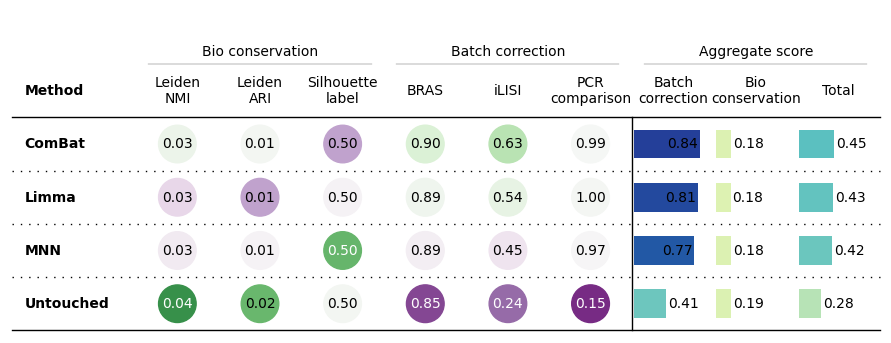

          Leiden NMI Leiden ARI Silhouette label  BRAS iLISI PCR comparison  \
Embedding                                                                     
Untouched      0.043      0.016            0.503 0.846 0.240          0.152   
ComBat         0.032      0.010            0.503 0.901 0.627          0.995   
Limma          0.028      0.005            0.503 0.893 0.536          1.000   
MNN            0.030      0.010            0.503 0.887 0.450          0.972   

          Batch correction Bio conservation Total  
Embedding                                          
Untouched            0.412            0.187 0.277  
ComBat               0.841            0.182 0.445  
Limma                0.810            0.179 0.431  
MNN                  0.769            0.181 0.416  


In [36]:
results_df, bm = benchmark_batch_correction_methods(
    adata_integrated,
    batch_key="cohort",
    label_key="label",
)

print(results_df)

## MNN Batch Correction

In [37]:
adata_head(adata_integrated, name="Merged Adata")

=== Merged Adata ===
Shape: (360, 4535)
Mean: 21.6352
Min:  14.2204
Max:  34.6058
Non-zero fraction: 1.0000
AnnData object with n_obs × n_vars = 360 × 4535
    obs: 'label', 'batch', 'cohort', 'batch_temp'
    var: 'taxid', 'root', 'domain', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'species', 'strain'
    layers: 'raw_counts', 'raw', 'imputed'



In [ ]:
# on batch not cohort - on 23

def apply_mnn_batch_correction(adata, batch_key="batch"):
    adata_corrected = adata.copy()
    batch_categories = adata_corrected.obs[batch_key].astype("category").cat.categories

    # Split into per-batch AnnData objects
    batch_samples = [
        adata_corrected[adata_corrected.obs[batch_key] == b].copy()
        for b in batch_categories
    ]

    # Choose safe parameters (validated from mnnpy docs & issue tracker)
    safe_k = 10                  # k must be < size of smallest batch
    safe_svd = 20                # also must be < batch size

    mnn_result = mnnpy.mnn_correct(
        *batch_samples,
        k=safe_k,
        svd_dim=safe_svd,
        cos_norm_in=True,
        cos_norm_out=True,
        var_adj=True,
        do_concatenate=True,
        n_jobs=1                 # avoids fork/JAX deadlock
    )

    adata_mnn = mnn_result[0]

    # Restore categorical batch
    adata_mnn.obs[batch_key] = adata_mnn.obs[batch_key].astype("category")

    adata_corrected.X = np.asarray(adata_mnn.X)
    return adata_corrected

adata_batch_corrected = apply_mnn_batch_correction(adata_integrated, batch_key="cohort")
adata_head(adata_batch_corrected, name="MNN Corrected")

Performing cosine normalization...


/usr/lib/python3.12/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()


Starting MNN correct iteration. Reference batch: 0
Step 1 of 25: processing batch 1
  Looking for MNNs...
  Computing correction vectors...
  Removing components...
  Adjusting variance...
  Applying correction...
Step 2 of 25: processing batch 2
  Looking for MNNs...
  Computing correction vectors...
  Removing components...
  Adjusting variance...
  Applying correction...
Step 3 of 25: processing batch 3
  Looking for MNNs...
  Computing correction vectors...
  Removing components...
  Adjusting variance...
  Applying correction...
Step 4 of 25: processing batch 4
  Looking for MNNs...
  Computing correction vectors...
  Removing components...
  Adjusting variance...
  Applying correction...
Step 5 of 25: processing batch 5
  Looking for MNNs...
  Computing correction vectors...
  Removing components...
  Adjusting variance...
  Applying correction...
Step 6 of 25: processing batch 6
  Looking for MNNs...
  Computing correction vectors...
  Removing components...
  Adjusting variance

/content/mnnpy/mnnpy/mnn.py:129: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata = AnnData.concatenate(*datas, batch_key=batch_key,


Done.
=== MNN Corrected ===
Shape: (360, 4535)
Mean: 0.0148
Min:  0.0094
Max:  0.0238
Non-zero fraction: 1.0000
AnnData object with n_obs × n_vars = 360 × 4535
    obs: 'label', 'batch', 'cohort', 'batch_temp'
    var: 'taxid', 'root', 'domain', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'species', 'strain'
    layers: 'raw_counts', 'raw', 'imputed'



In [41]:
def apply_mnn_batch_correction(adata, batch_key="cohort"):
    adata_corrected = adata.copy()
    batch_categories = adata_corrected.obs[batch_key].cat.categories

    # Split into per-batch AnnData objects
    batch_samples = [adata_corrected[adata_corrected.obs[batch_key] == b].copy() for b in batch_categories]

    # Run MNN correction
    mnn_result = mnnpy.mnn_correct(*batch_samples)
    adata_mnn = mnn_result[0]

    # Restore batch column
    adata_mnn.obs[batch_key] = adata_mnn.obs[batch_key].astype("category")

    # Store corrected values in adata.X
    adata_corrected.X = np.asarray(adata_mnn.X)
    return adata_corrected

adata_batch_corrected = apply_mnn_batch_correction(adata_integrated, batch_key="cohort")
adata_head(adata_batch_corrected, name="MNN Corrected")

Performing cosine normalization...


/usr/lib/python3.12/multiprocessing/popen_fork.py:66: RuntimeWarning: os.fork() was called. os.fork() is incompatible with multithreaded code, and JAX is multithreaded, so this will likely lead to a deadlock.
  self.pid = os.fork()


Starting MNN correct iteration. Reference batch: 0
Step 1 of 1: processing batch 1
  Looking for MNNs...
  Computing correction vectors...
  Adjusting variance...
  Applying correction...
MNN correction complete. Gathering output...
Packing AnnData object...
Done.
=== MNN Corrected ===
Shape: (360, 4535)
Mean: 0.0148
Min:  0.0105
Max:  0.0243
Non-zero fraction: 1.0000
AnnData object with n_obs × n_vars = 360 × 4535
    obs: 'label', 'batch', 'cohort', 'batch_temp'
    var: 'taxid', 'root', 'domain', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'species', 'strain'
    layers: 'raw_counts', 'raw', 'imputed'



/content/mnnpy/mnnpy/mnn.py:129: FutureWarning: The method concatenate is deprecated and will be removed in the future. Use anndata.concat instead of AnnData.concatenate. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata = AnnData.concatenate(*datas, batch_key=batch_key,


In [42]:
# Save batch corrected adata to Temp folder
sc.write(join(temp_adata_path, "adata_batch_corrected.h5ad"), adata_batch_corrected)
print("Done Saving Temp")

Done Saving Temp


## Plot 5 - After MNN Batch Correction

In [43]:
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt

fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Times New Roman'

print([f.name for f in fm.fontManager.ttflist if "Times" in f.name])
print(plt.rcParams['font.size'])

['Times New Roman', 'Times New Roman', 'Times New Roman']
10.0


    SGD-MDS may not have converged: stress changed by 6.7% in final iterations. Consider increasing n_iter or adjusting learning_rate.


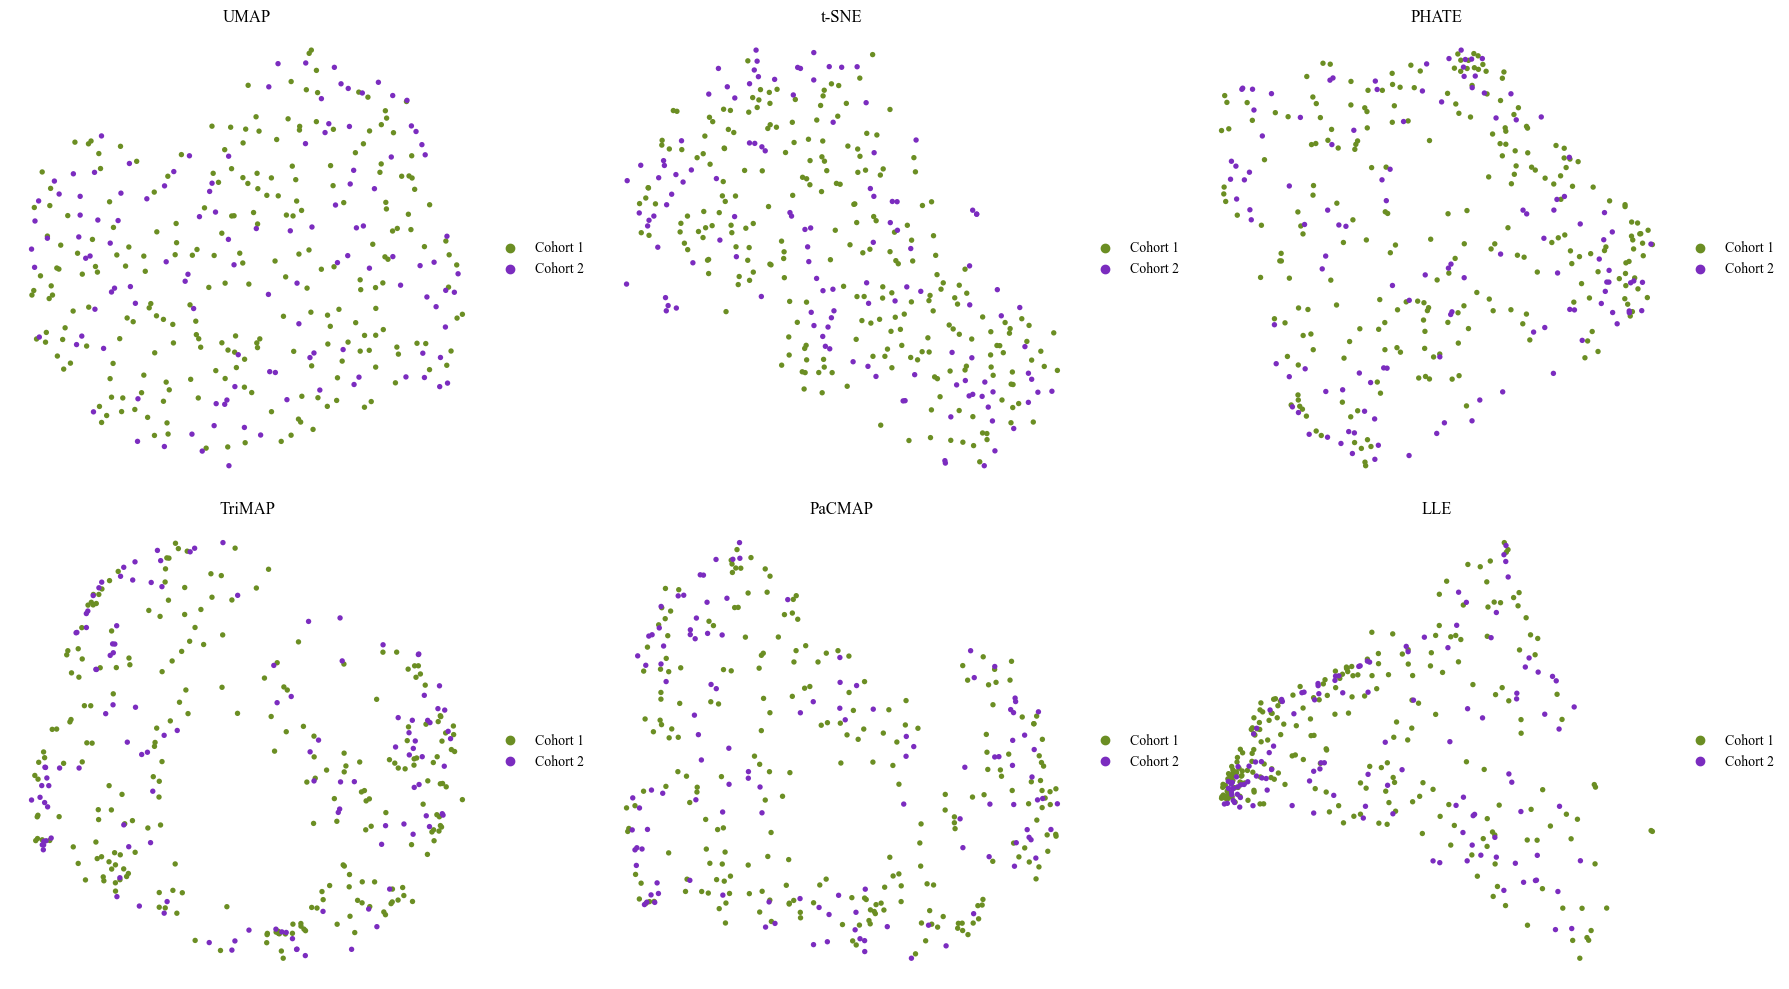

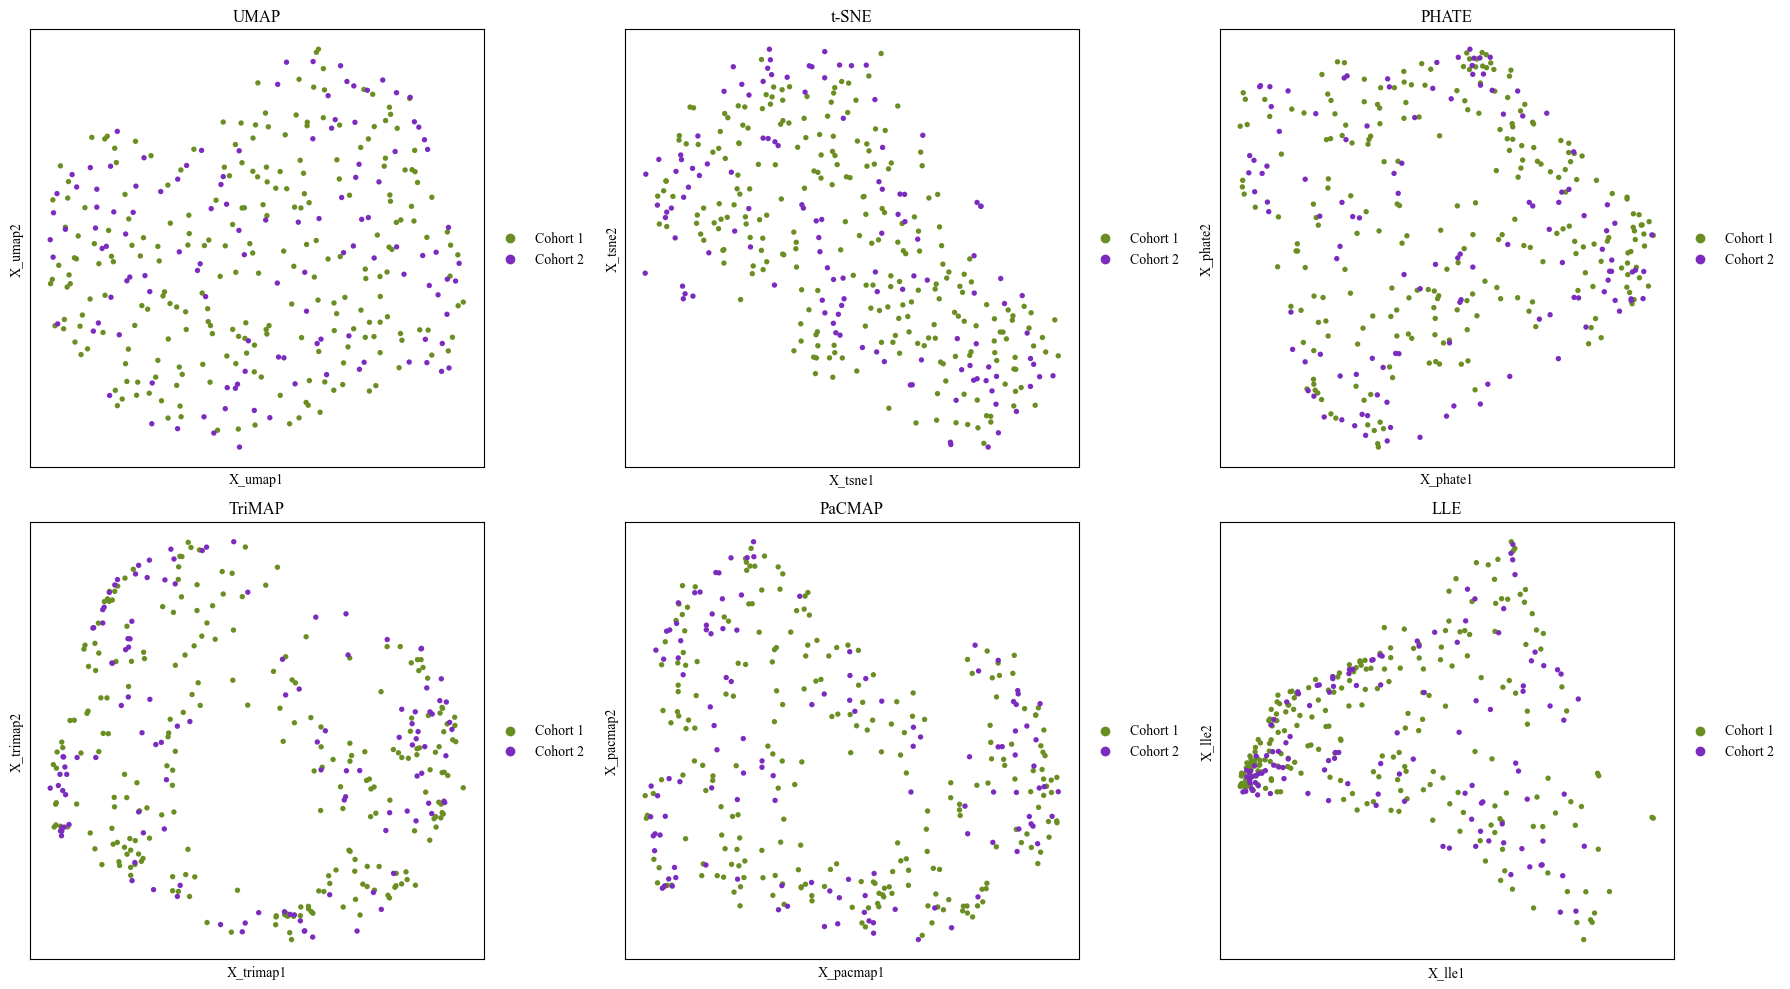

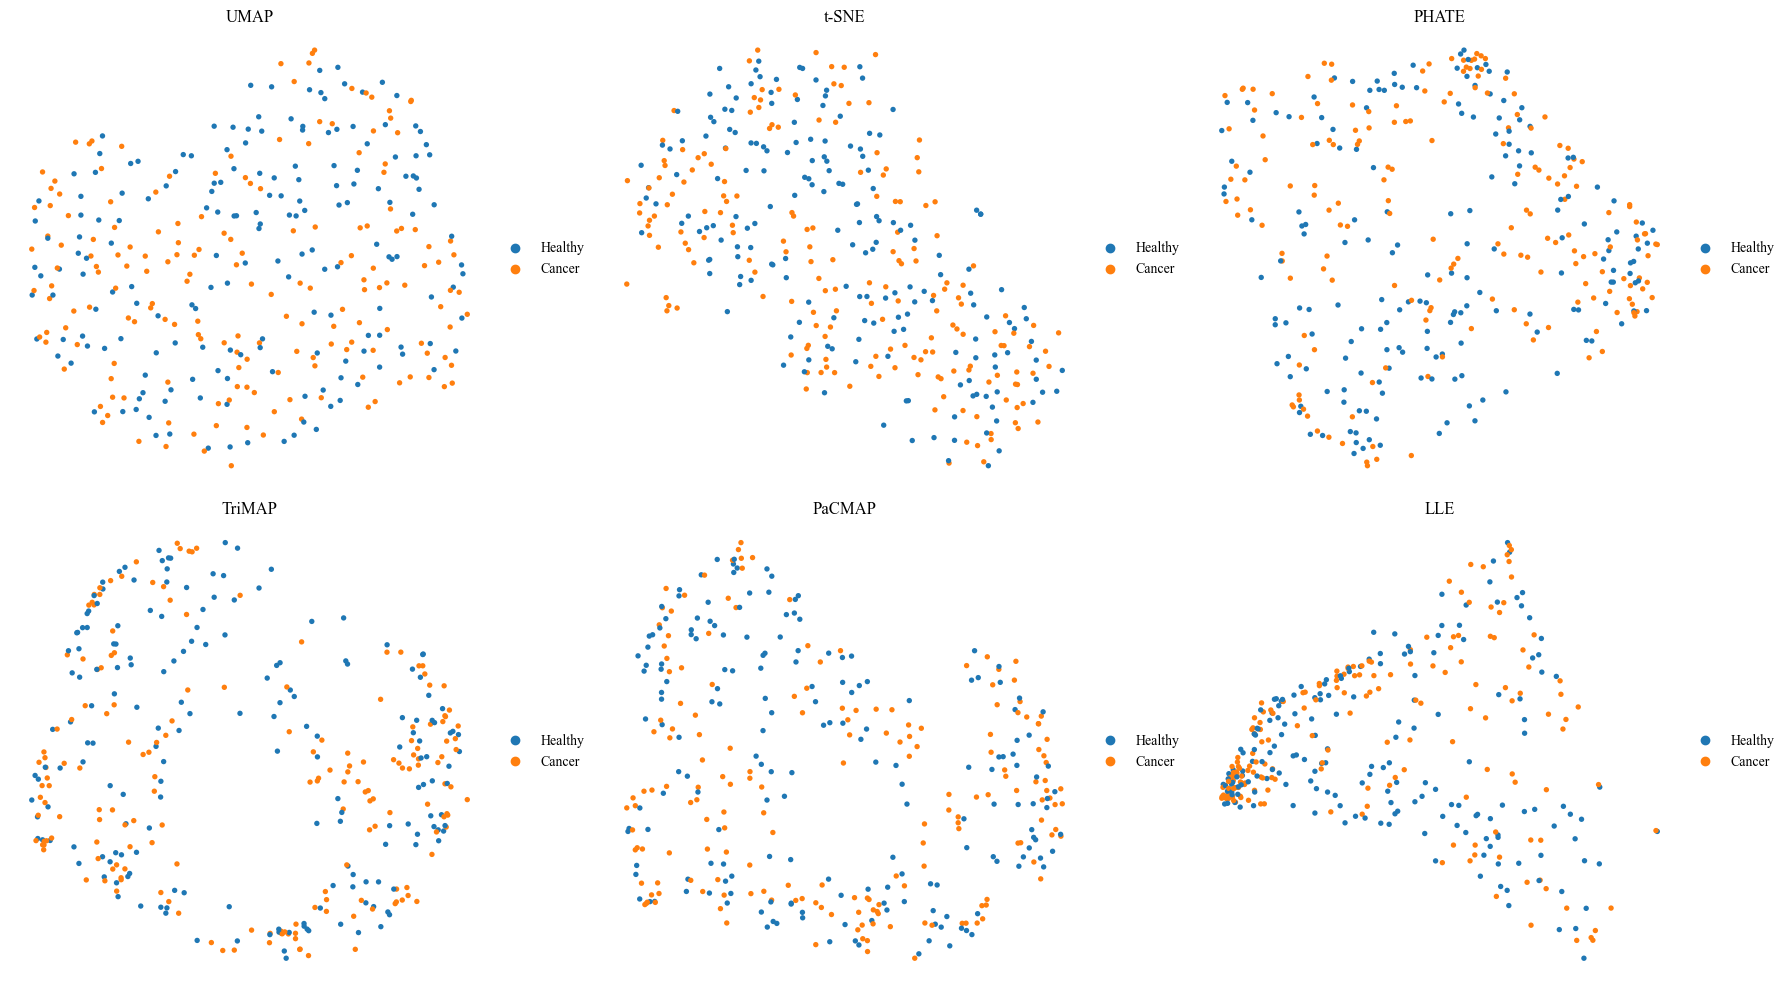

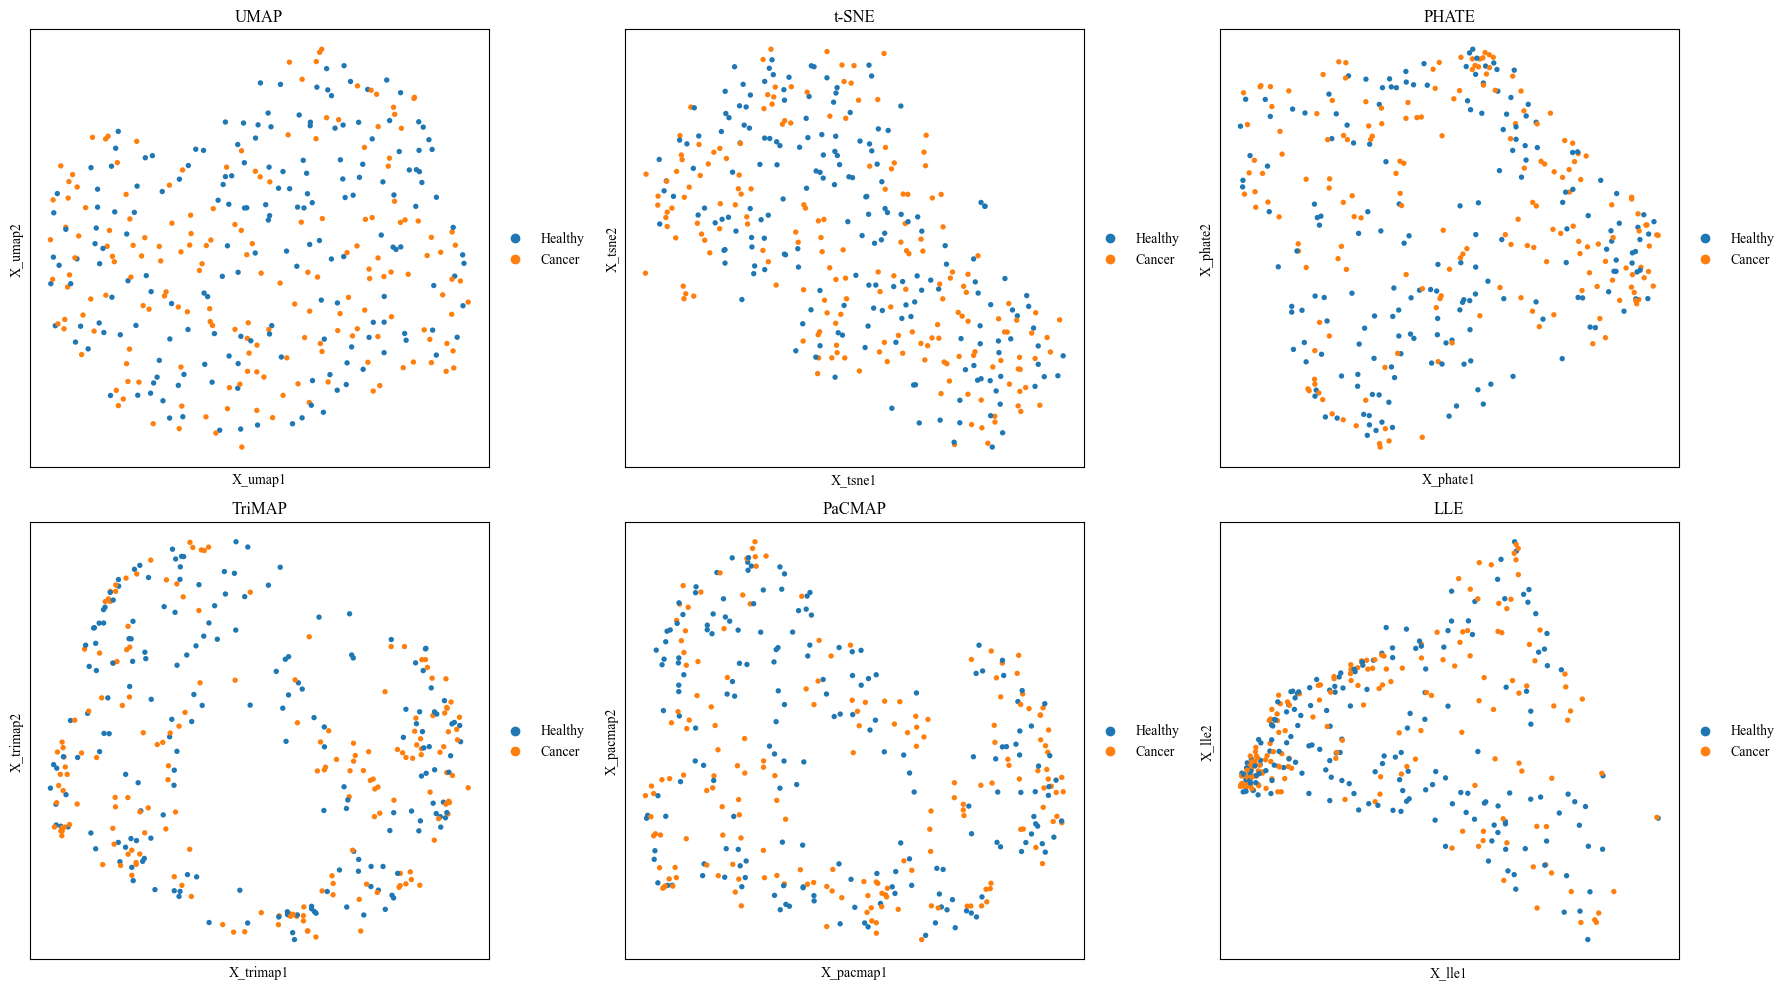

In [47]:
def plot_multiple_after_batch_correction(adata, point_size=60, random_state=0):

    adata_ = adata.copy()

    # ---------------------------------------------------
    # Cohort relabeling
    # ---------------------------------------------------
    cohort_mapping = {
        "1": "Cohort 1",
        "2": "Cohort 2"
    }

    adata_.obs["cohort"] = adata_.obs["cohort"].astype(str).map(cohort_mapping)

    # -------------------------------
    # UMAP
    # -------------------------------
    adata_umap = adata_.copy()
    sc.pp.neighbors(adata_umap, use_rep="X")
    sc.tl.umap(adata_umap, random_state=random_state)

    # -------------------------------
    # t-SNE
    # -------------------------------
    adata_tsne = adata_.copy()
    sc.tl.tsne(adata_tsne, use_rep="X", random_state=random_state)

    # -------------------------------
    # PHATE
    # -------------------------------
    adata_phate = adata_.copy()
    phate_op = phate.PHATE(n_components=2, n_jobs=-1, random_state=random_state, verbose=False)
    adata_phate.obsm["X_phate"] = phate_op.fit_transform(adata_phate.X)

    # -------------------------------
    # TriMAP
    # -------------------------------
    adata_trimap = adata_.copy()
    trimap_op = trimap.TRIMAP(n_dims=2)
    adata_trimap.obsm["X_trimap"] = trimap_op.fit_transform(adata_trimap.X)

    # -------------------------------
    # PaCMAP
    # -------------------------------
    adata_pacmap = adata_.copy()
    pacmap_op = pacmap.PaCMAP(n_components=2, random_state=random_state, verbose=False)
    adata_pacmap.obsm["X_pacmap"] = pacmap_op.fit_transform(adata_pacmap.X)

    # -------------------------------
    # LLE
    # -------------------------------
    adata_lle = adata_.copy()
    lle_op = LocallyLinearEmbedding(n_components=2, random_state=random_state)
    adata_lle.obsm["X_lle"] = lle_op.fit_transform(adata_lle.X)

    embeddings = [
        ("UMAP", adata_umap, "X_umap"),
        ("t-SNE", adata_tsne, "X_tsne"),
        ("PHATE", adata_phate, "X_phate"),
        ("TriMAP", adata_trimap, "X_trimap"),
        ("PaCMAP", adata_pacmap, "X_pacmap"),
        ("LLE", adata_lle, "X_lle"),
    ]

    # ---------------------------------------------------
    # plotting helper
    # ---------------------------------------------------
    def make_grid(color_by, frameon, save_name):

        fig, axes = plt.subplots(2, 3, figsize=(18, 10))
        axes = axes.flatten()

        # Cohort-specific palette (ONLY here)
        cohort_palette = ["#6B8E23", "#7B2CBF"]

        for i, (name, ad, key) in enumerate(embeddings):

            sc.pl.embedding(
                ad,
                basis=key,
                color=color_by,
                ax=axes[i],
                show=False,
                title=name,
                size=point_size,
                frameon=frameon,
                palette=cohort_palette if color_by == "cohort" else None
            )

        plt.tight_layout()

        plt.savefig(
            join(figures_path, save_name),
            dpi=1200,
            bbox_inches="tight"
        )

        plt.show()
        plt.close(fig)

    # ---------------------------------------------------
    # 1 Cohort frameless
    # ---------------------------------------------------
    make_grid("cohort", False, "plot5_multiple_after_batch_correction_by_cohort_frameless.png")

    # 2 Cohort framed
    make_grid("cohort", True, "plot5_multiple_after_batch_correction_by_cohort_framed.png")

    # 3 Label frameless
    make_grid("label", False, "plot5_multiple_after_batch_correction_by_label_frameless.png")

    # 4 Label framed
    make_grid("label", True, "plot5_multiple_after_batch_correction_by_label_framed.png")


plot_multiple_after_batch_correction(adata_batch_corrected)

    SGD-MDS may not have converged: stress changed by 10.7% in final iterations. Consider increasing n_iter or adjusting learning_rate.


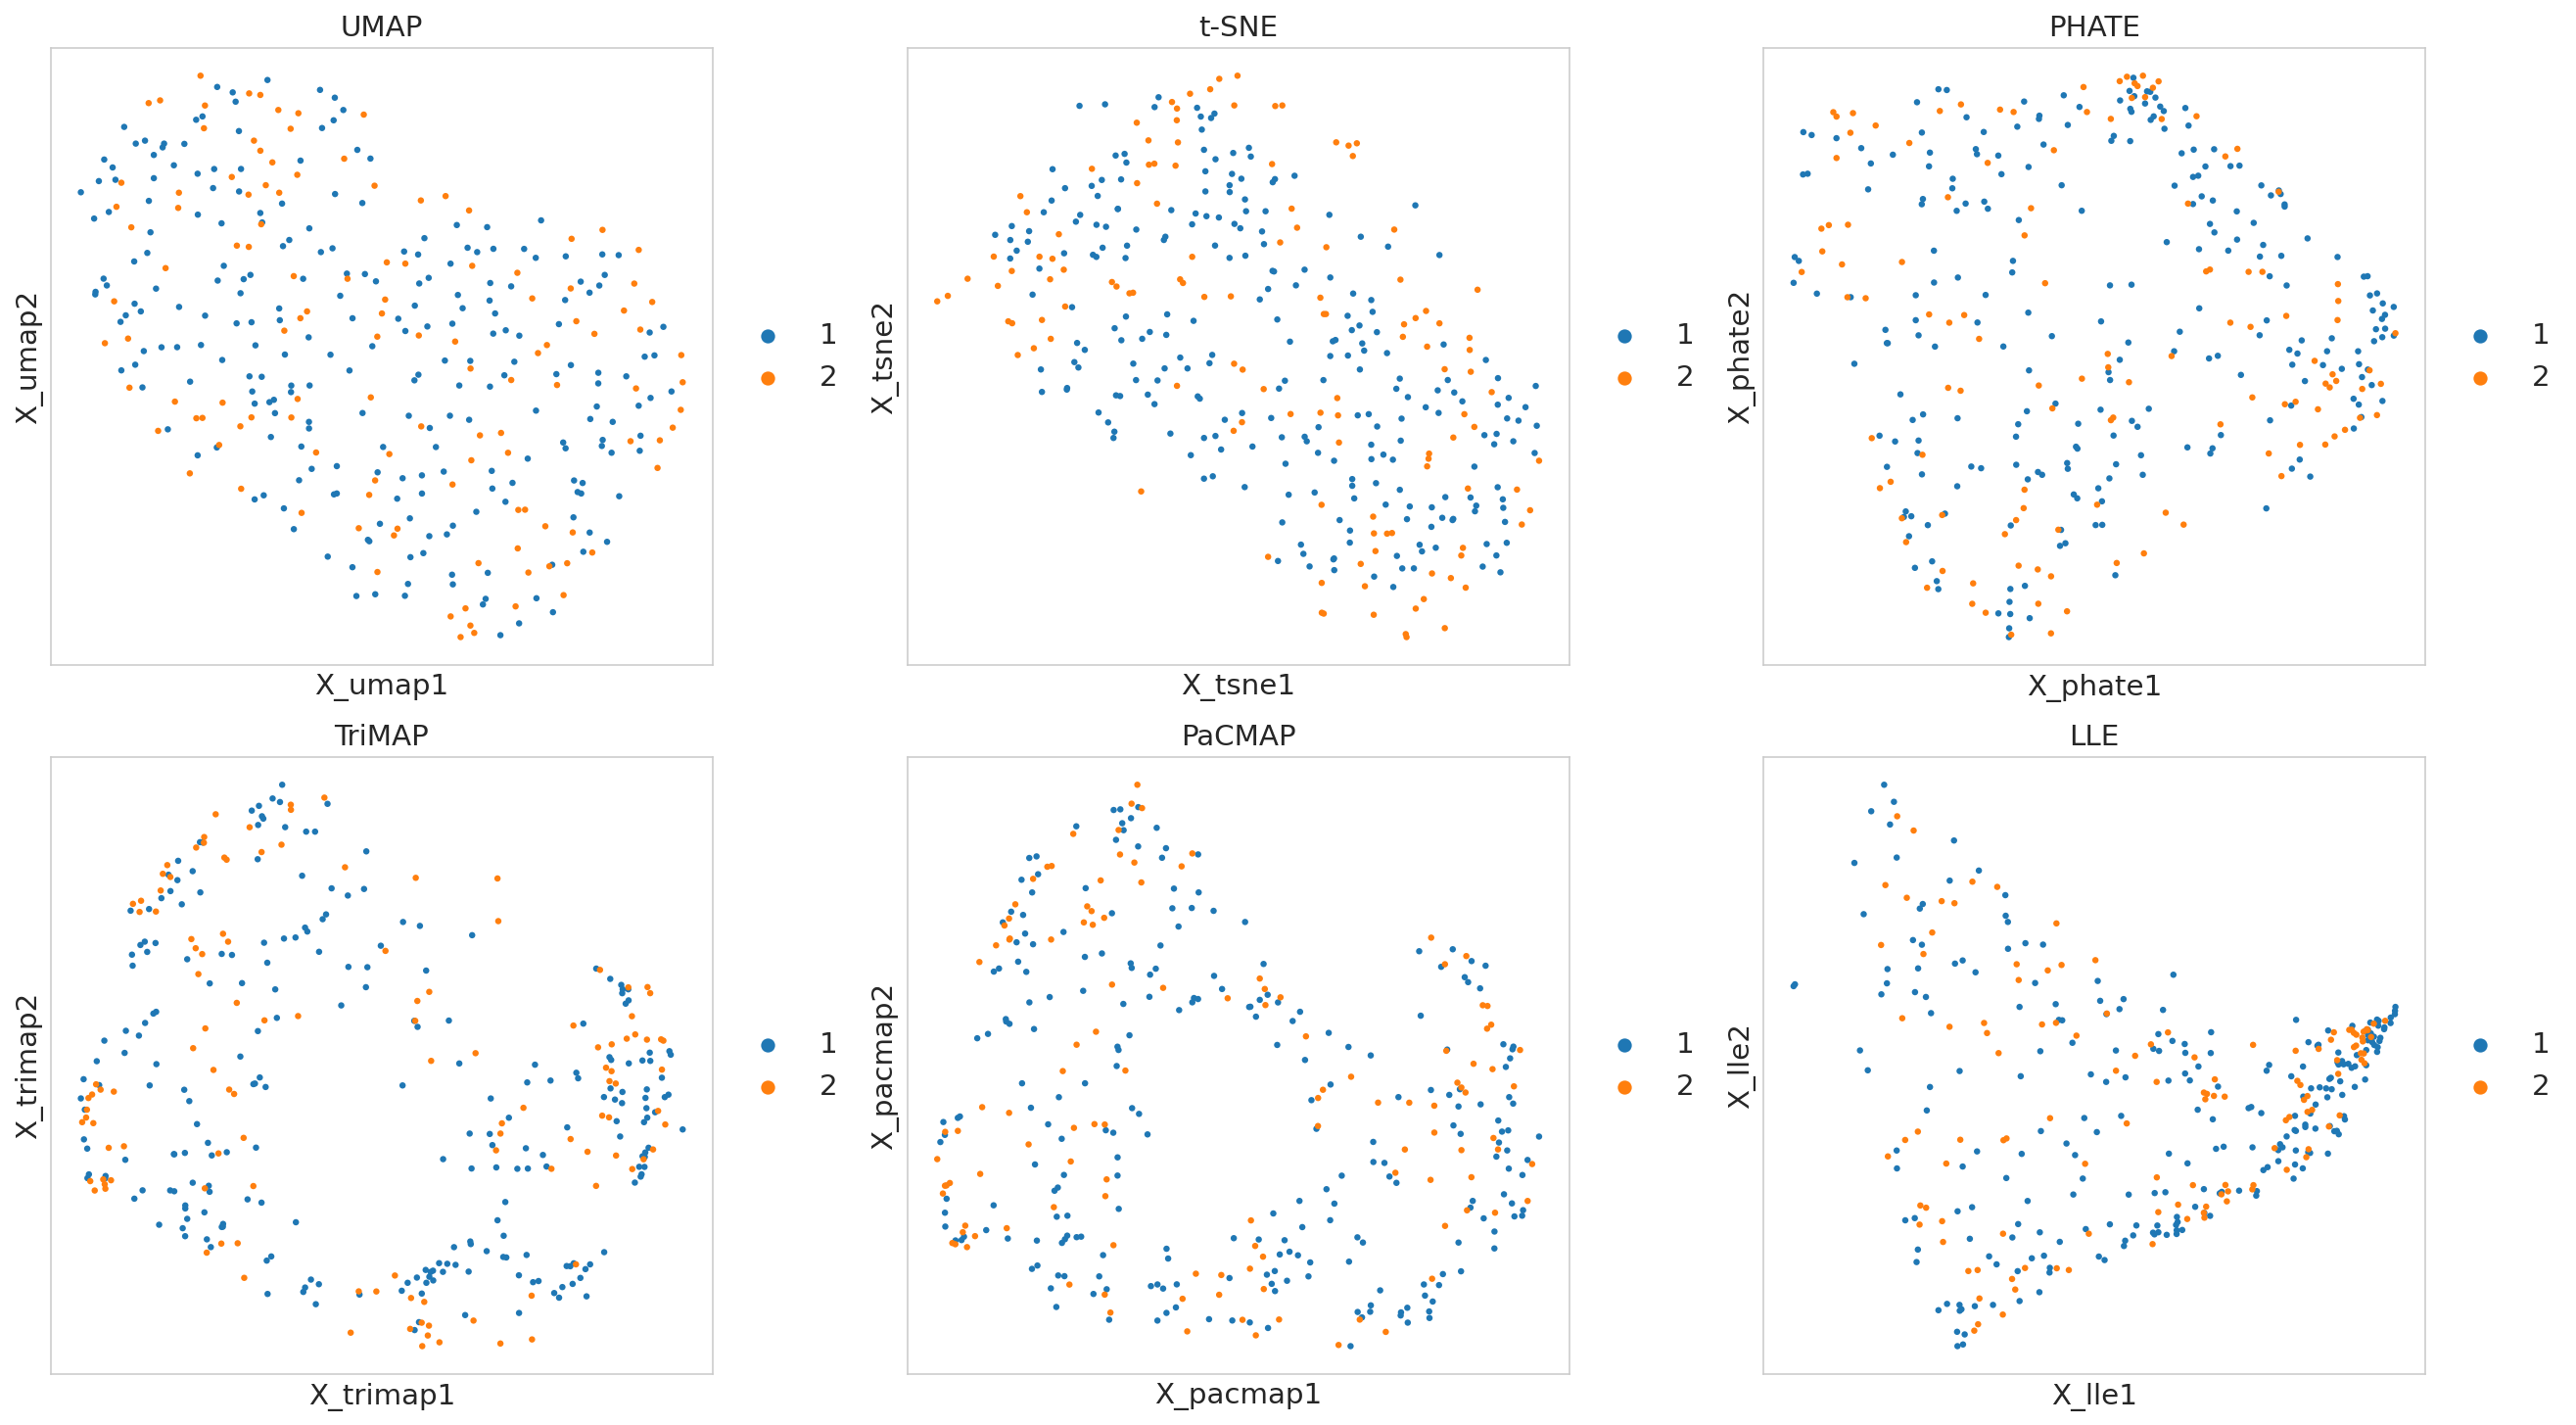

In [ ]:
# def plot_after_batch_correction(adata, point_size=40, random_state=0, color="batch"):
#     """
#     Plot embeddings: UMAP, t-SNE, PHATE, TriMAP, PaCMAP, and LLE
#     in a 2x3 grid layout using normalized/log1p/scaled preprocessing.
#     """
#     adata_ = adata.copy()

#     # -------------------------------
#     # UMAP
#     # -------------------------------
#     adata_umap = adata_.copy()
#     sc.pp.neighbors(adata_umap, use_rep="X")
#     sc.tl.umap(adata_umap, random_state=random_state)

#     # -------------------------------
#     # t-SNE
#     # -------------------------------
#     adata_tsne = adata_.copy()
#     sc.tl.tsne(adata_tsne, use_rep="X", random_state=random_state)

#     # -------------------------------
#     # PHATE
#     # -------------------------------
#     adata_phate = adata_.copy()
#     phate_op = phate.PHATE(n_components=2, n_jobs=-1, random_state=random_state, verbose=False)
#     adata_phate.obsm["X_phate"] = phate_op.fit_transform(adata_phate.X)

#     # -------------------------------
#     # TriMAP
#     # -------------------------------
#     adata_trimap = adata_.copy()
#     trimap_op = trimap.TRIMAP(n_dims=2)
#     adata_trimap.obsm["X_trimap"] = trimap_op.fit_transform(adata_trimap.X)

#     # -------------------------------
#     # PaCMAP
#     # -------------------------------
#     adata_pacmap = adata_.copy()
#     pacmap_op = pacmap.PaCMAP(n_components=2, random_state=random_state, verbose=False)
#     adata_pacmap.obsm["X_pacmap"] = pacmap_op.fit_transform(adata_pacmap.X)

#     # -------------------------------
#     # LLE
#     # -------------------------------
#     adata_lle = adata_.copy()
#     lle_op = LocallyLinearEmbedding(n_components=2, random_state=random_state)
#     adata_lle.obsm["X_lle"] = lle_op.fit_transform(adata_lle.X)

#     # -------------------------------
#     # Plot embeddings in 2x3 grid
#     # -------------------------------
#     embeddings = [
#         ("UMAP", adata_umap, "X_umap"),
#         ("t-SNE", adata_tsne, "X_tsne"),
#         ("PHATE", adata_phate, "X_phate"),
#         ("TriMAP", adata_trimap, "X_trimap"),
#         ("PaCMAP", adata_pacmap, "X_pacmap"),
#         ("LLE", adata_lle, "X_lle"),
#     ]

#     fig, axes = plt.subplots(2, 3, figsize=(18, 10))
#     axes = axes.flatten()

#     for i, (name, ad, key) in enumerate(embeddings):
#         sc.pl.embedding(
#             ad,
#             basis=key,
#             color=color,
#             ax=axes[i],
#             show=False,
#             title=name,
#             size=point_size
#         )

#     plt.tight_layout()
#     plt.show()

# plot_after_batch_correction(adata_batch_corrected, color="cohort")

In [48]:
adata_head(adata_batch_corrected, name="Adata Batch Corrected")

=== Adata Batch Corrected ===
Shape: (360, 4535)
Mean: 0.0148
Min:  0.0105
Max:  0.0243
Non-zero fraction: 1.0000
AnnData object with n_obs × n_vars = 360 × 4535
    obs: 'label', 'batch', 'cohort', 'batch_temp'
    var: 'taxid', 'root', 'domain', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'species', 'strain'
    layers: 'raw_counts', 'raw', 'imputed'



## Remove Non-Microbial Features



In [54]:
# adata_batch_corrected
print(adata_batch_corrected)
print(list(adata_batch_corrected.var["domain"].unique()))


def get_chordata_taxonomy(adata, return_df=True):
    tax_levels = ['kingdom', 'phylum', "class", "order", "family", "genus", "species", "strain"]
    chordata = adata.var[adata.var["domain"] == "Eukaryota"]
    result = {
        level: chordata[level].dropna().unique().tolist()
        for level in tax_levels
    }
    if return_df:
        return pd.DataFrame({k: pd.Series(v) for k, v in result.items()})
    return result

print(get_chordata_taxonomy(adata_batch_corrected))

AnnData object with n_obs × n_vars = 360 × 4535
    obs: 'label', 'batch', 'cohort', 'batch_temp'
    var: 'taxid', 'root', 'domain', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'species', 'strain'
    layers: 'raw_counts', 'raw', 'imputed'
['Eukaryota', 'Bacteria', nan]
   kingdom    phylum     class     order     family genus       species strain
0  Metazoa  Chordata  Mammalia  Primates  Hominidae  Homo  Homo sapiens    NaN


In [56]:
def remove_phylum(adata, phylum_to_remove="Chordata"):
    _adata = adata.copy()
    mask = _adata.var["phylum"] != phylum_to_remove
    adata_out = _adata[:, mask].copy()
    removed = (~mask).sum()
    print(f"Removing {removed} features from phylum '{phylum_to_remove}'")
    return adata_out

adata_microbial = remove_phylum(adata_batch_corrected, "Chordata")
adata_head(adata_microbial, name="Adata Microbial")

Removing 745 features from phylum 'Chordata'
=== Adata Microbial ===
Shape: (360, 3790)
Mean: 0.0147
Min:  0.0105
Max:  0.0216
Non-zero fraction: 1.0000
AnnData object with n_obs × n_vars = 360 × 3790
    obs: 'label', 'batch', 'cohort', 'batch_temp'
    var: 'taxid', 'root', 'domain', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'species', 'strain'
    layers: 'raw_counts', 'raw', 'imputed'



In [57]:
# adata_batch_corrected
print(adata_microbial)
print(list(adata_microbial.var["domain"].unique()))

AnnData object with n_obs × n_vars = 360 × 3790
    obs: 'label', 'batch', 'cohort', 'batch_temp'
    var: 'taxid', 'root', 'domain', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'species', 'strain'
    layers: 'raw_counts', 'raw', 'imputed'
['Bacteria', nan]


In [58]:
# Save final adata to Temp folder
sc.write(join(temp_adata_path, "adata_final.h5ad"), adata_microbial)
print("Done Saving Temp")

Done Saving Temp


## Plot 6 - After Removing Non-microbial Features

In [59]:
import matplotlib.font_manager as fm
import matplotlib.pyplot as plt

fm.fontManager.addfont(font_path)
plt.rcParams['font.family'] = 'Times New Roman'

print([f.name for f in fm.fontManager.ttflist if "Times" in f.name])
print(plt.rcParams['font.size'])

['Times New Roman', 'Times New Roman', 'Times New Roman', 'Times New Roman']
10.0


    SGD-MDS may not have converged: stress changed by 4.2% in final iterations. Consider increasing n_iter or adjusting learning_rate.


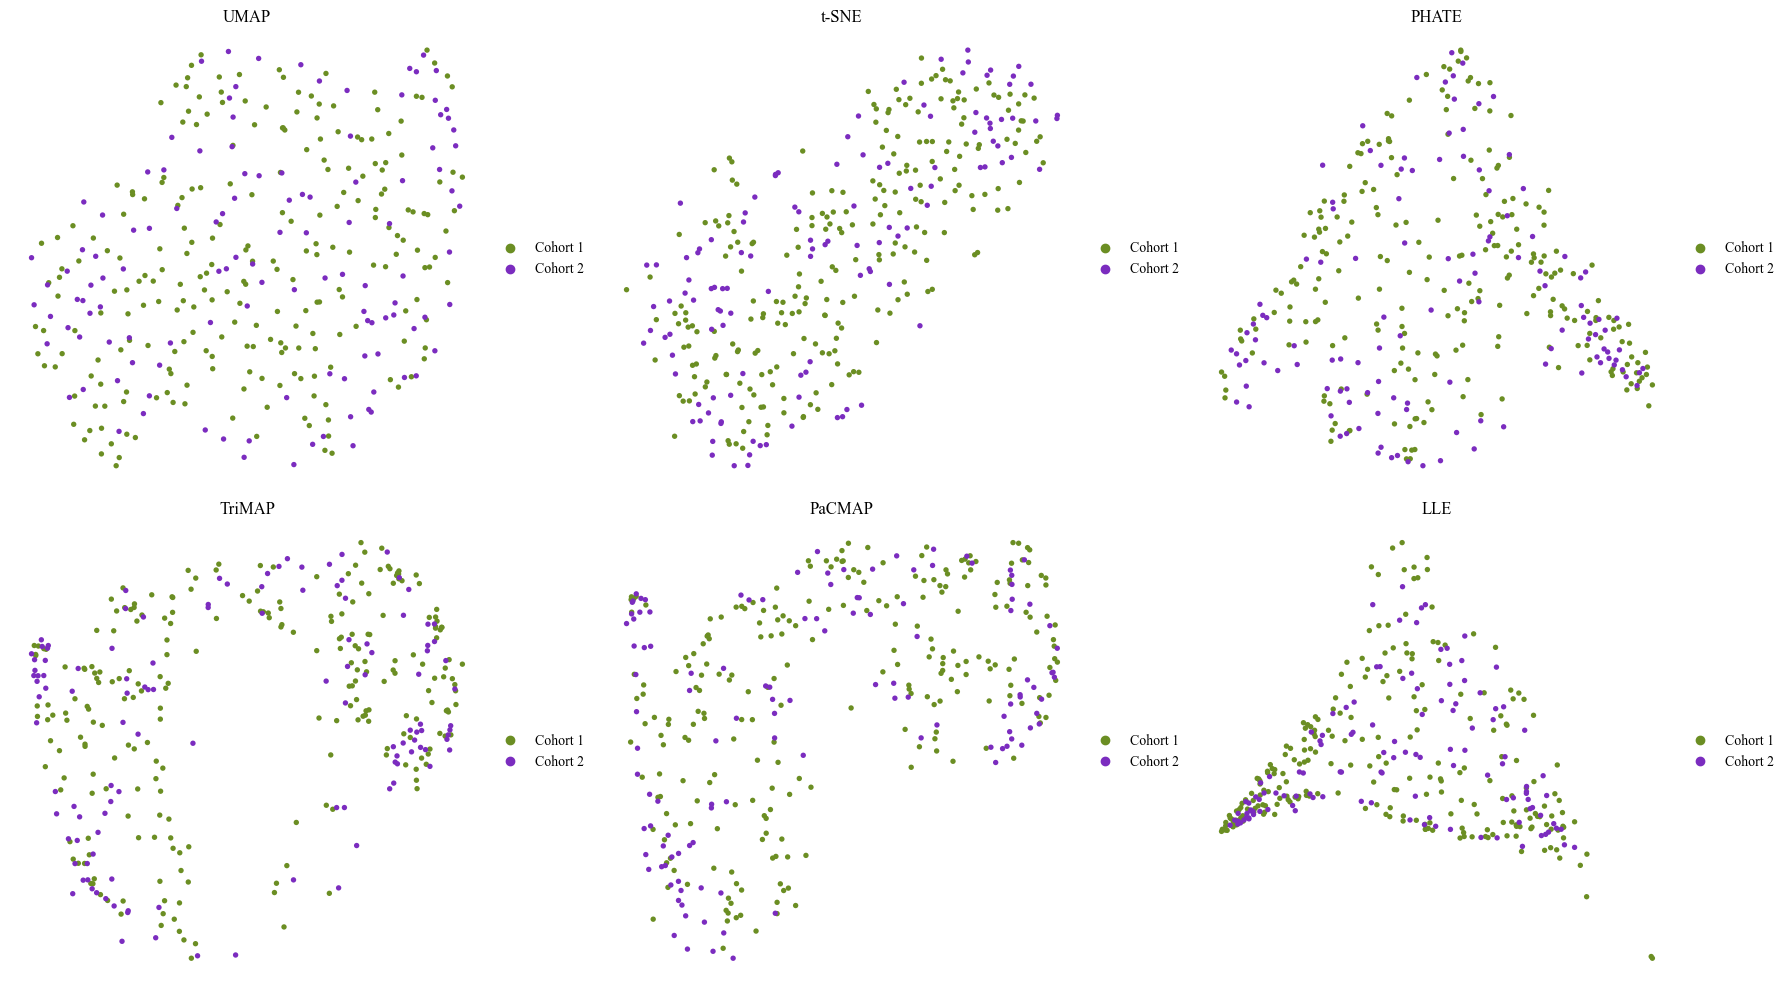

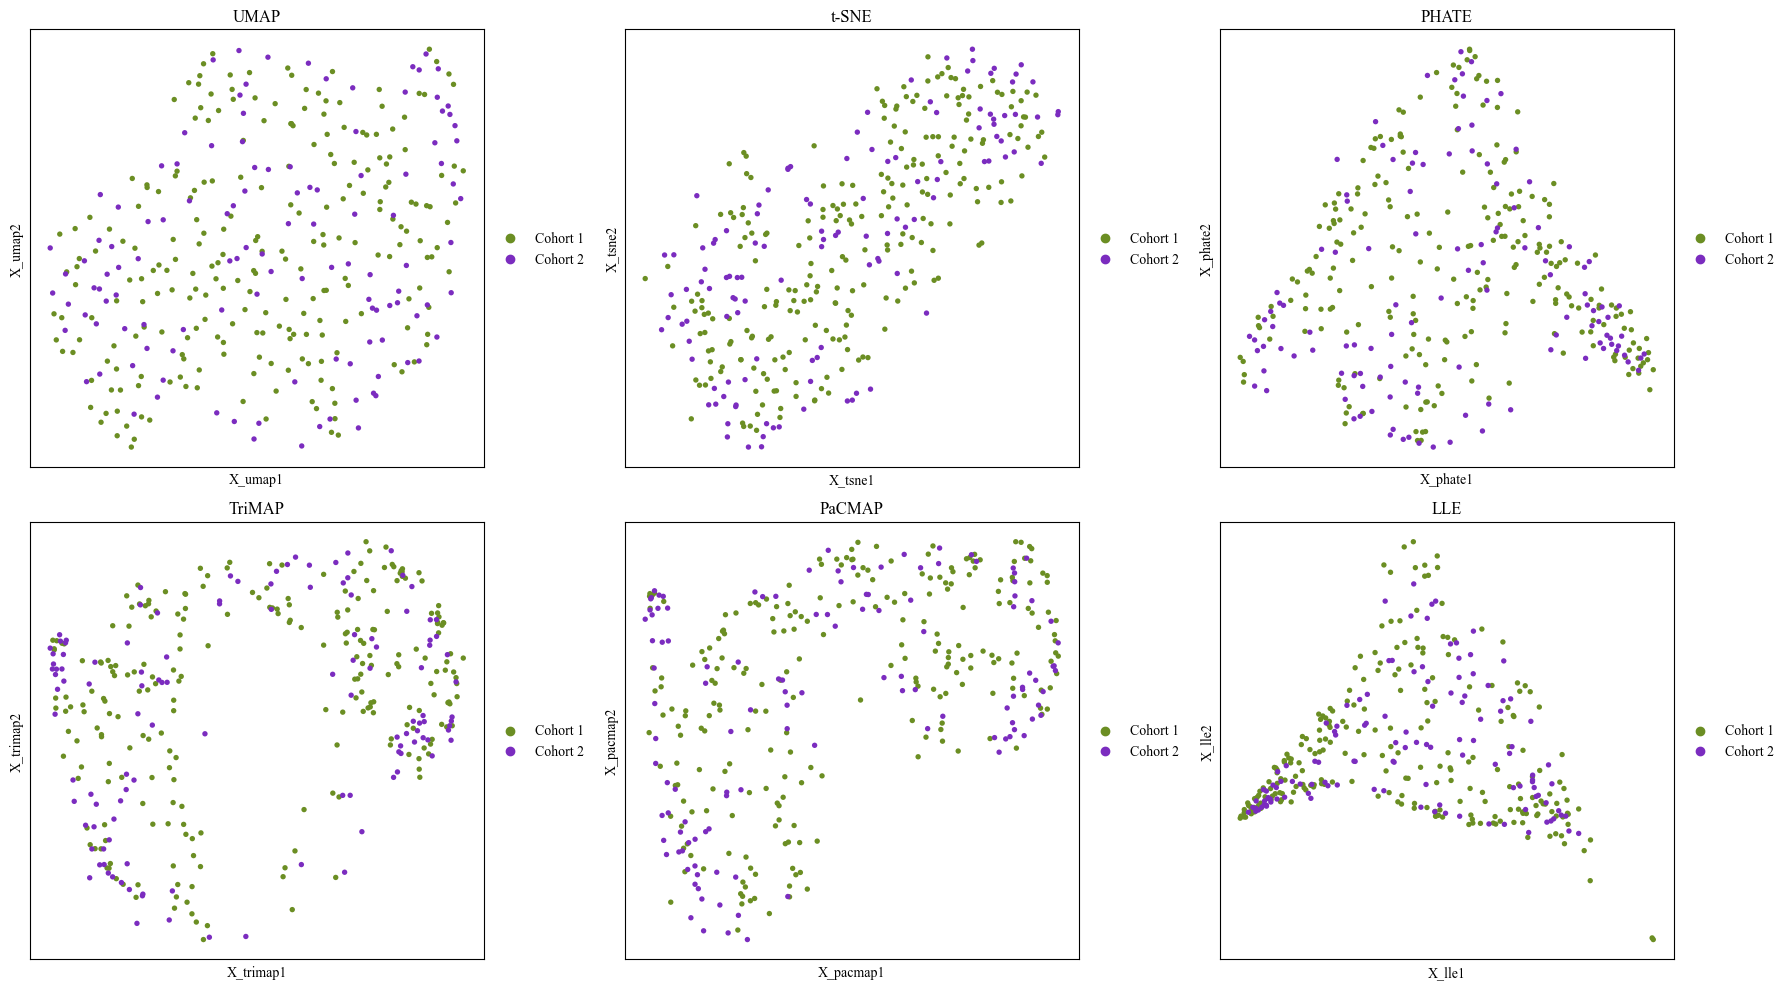

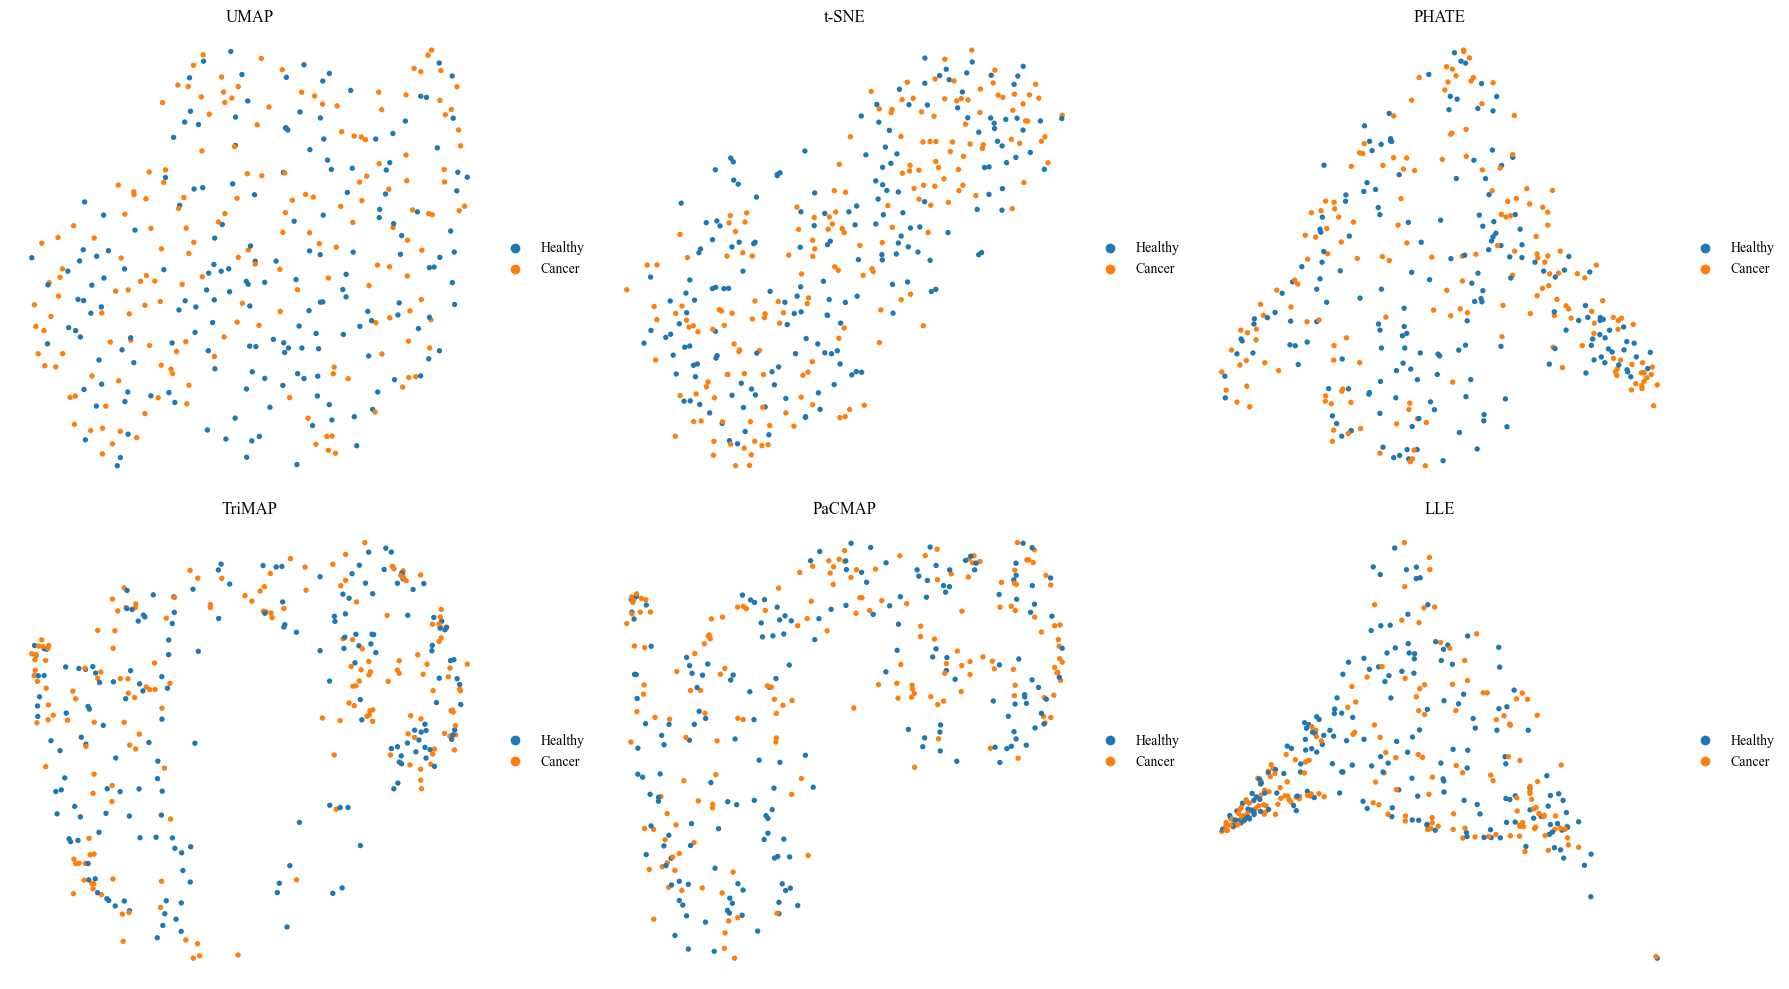

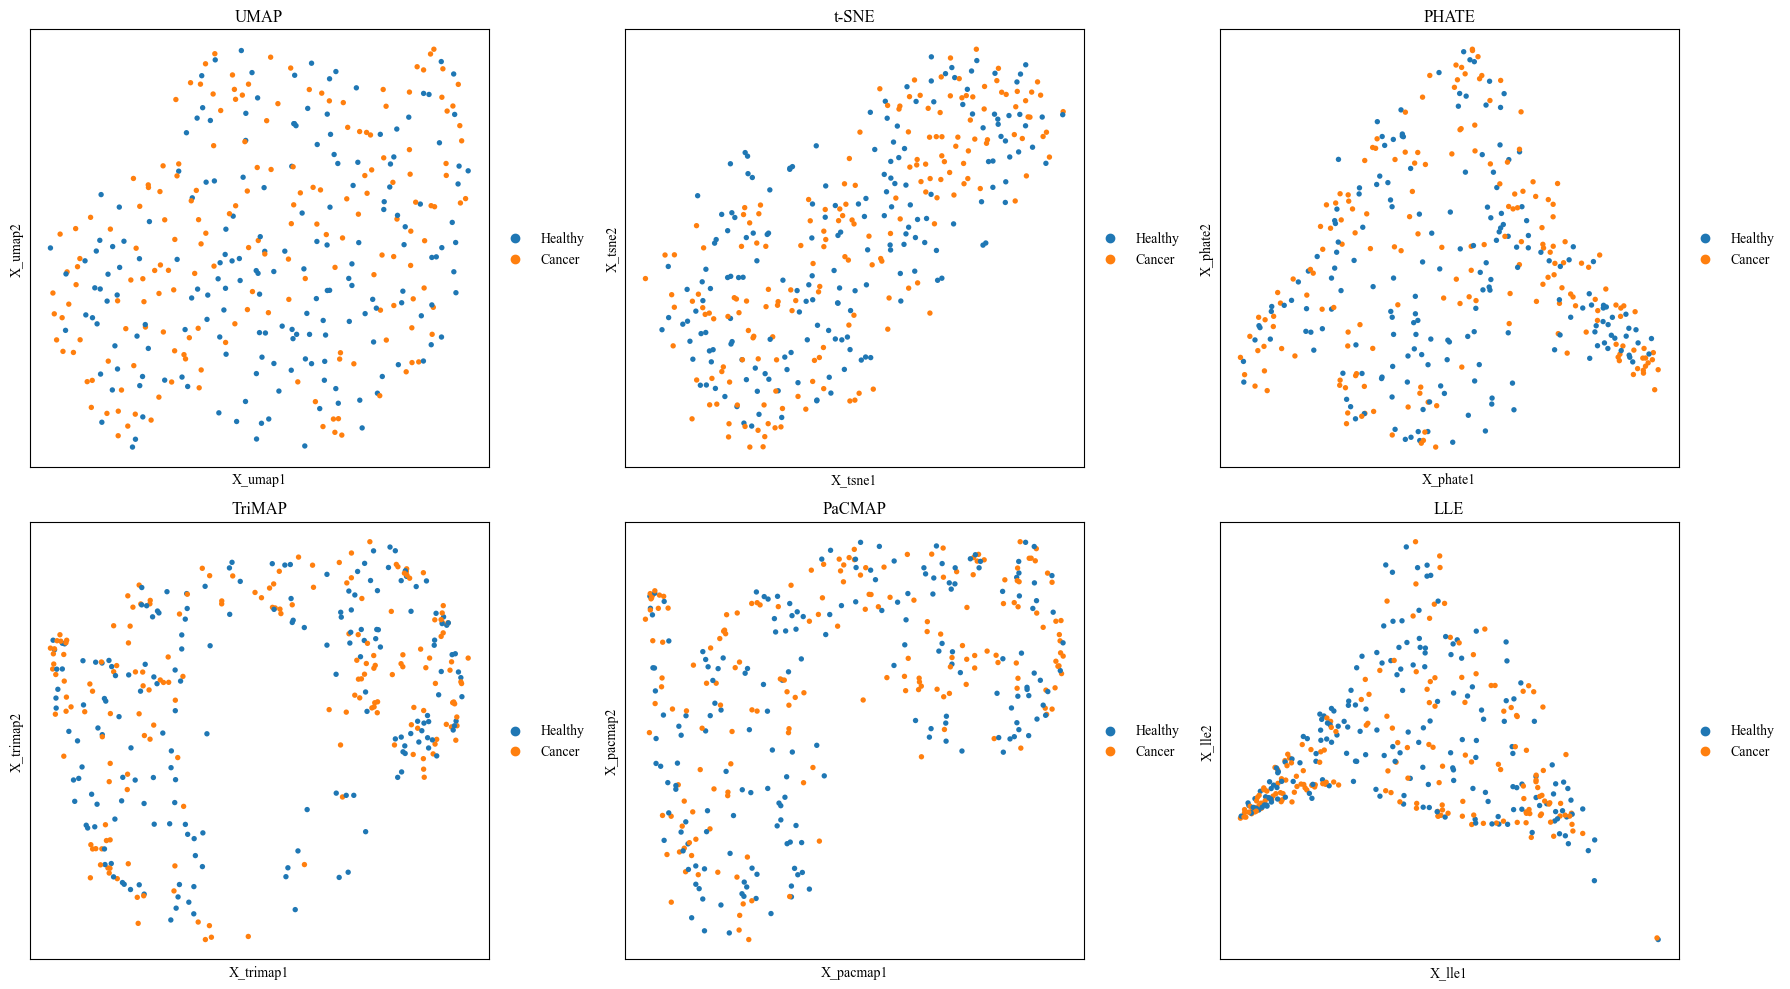

In [60]:
def plot_multiple_after_cleaning_non_microbial_features(adata, point_size=60, random_state=0):

    adata_ = adata.copy()

    # ---------------------------------------------------
    # Cohort relabeling
    # ---------------------------------------------------
    cohort_mapping = {
        "1": "Cohort 1",
        "2": "Cohort 2"
    }

    adata_.obs["cohort"] = adata_.obs["cohort"].astype(str).map(cohort_mapping)

    # -------------------------------
    # UMAP
    # -------------------------------
    adata_umap = adata_.copy()
    sc.pp.neighbors(adata_umap, use_rep="X")
    sc.tl.umap(adata_umap, random_state=random_state)

    # -------------------------------
    # t-SNE
    # -------------------------------
    adata_tsne = adata_.copy()
    sc.tl.tsne(adata_tsne, use_rep="X", random_state=random_state)

    # -------------------------------
    # PHATE
    # -------------------------------
    adata_phate = adata_.copy()
    phate_op = phate.PHATE(n_components=2, n_jobs=-1, random_state=random_state, verbose=False)
    adata_phate.obsm["X_phate"] = phate_op.fit_transform(adata_phate.X)

    # -------------------------------
    # TriMAP
    # -------------------------------
    adata_trimap = adata_.copy()
    trimap_op = trimap.TRIMAP(n_dims=2)
    adata_trimap.obsm["X_trimap"] = trimap_op.fit_transform(adata_trimap.X)

    # -------------------------------
    # PaCMAP
    # -------------------------------
    adata_pacmap = adata_.copy()
    pacmap_op = pacmap.PaCMAP(n_components=2, random_state=random_state, verbose=False)
    adata_pacmap.obsm["X_pacmap"] = pacmap_op.fit_transform(adata_pacmap.X)

    # -------------------------------
    # LLE
    # -------------------------------
    adata_lle = adata_.copy()
    lle_op = LocallyLinearEmbedding(n_components=2, random_state=random_state)
    adata_lle.obsm["X_lle"] = lle_op.fit_transform(adata_lle.X)

    embeddings = [
        ("UMAP", adata_umap, "X_umap"),
        ("t-SNE", adata_tsne, "X_tsne"),
        ("PHATE", adata_phate, "X_phate"),
        ("TriMAP", adata_trimap, "X_trimap"),
        ("PaCMAP", adata_pacmap, "X_pacmap"),
        ("LLE", adata_lle, "X_lle"),
    ]

    # ---------------------------------------------------
    # plotting helper
    # ---------------------------------------------------
    def make_grid(color_by, frameon, save_name):

        fig, axes = plt.subplots(2, 3, figsize=(18, 10))
        axes = axes.flatten()

        # Cohort-specific palette (ONLY here)
        cohort_palette = ["#6B8E23", "#7B2CBF"]

        for i, (name, ad, key) in enumerate(embeddings):

            sc.pl.embedding(
                ad,
                basis=key,
                color=color_by,
                ax=axes[i],
                show=False,
                title=name,
                size=point_size,
                frameon=frameon,
                palette=cohort_palette if color_by == "cohort" else None
            )

        plt.tight_layout()

        plt.savefig(
            join(figures_path, save_name),
            dpi=1200,
            bbox_inches="tight"
        )

        plt.show()
        plt.close(fig)

    # ---------------------------------------------------
    # 1 Cohort frameless
    # ---------------------------------------------------
    make_grid("cohort", False, "plot6_multiple_after_cleaning_non_microbial_features_by_cohort_frameless.png")

    # 2 Cohort framed
    make_grid("cohort", True, "plot6_multiple_after_cleaning_non_microbial_features_by_cohort_framed.png")

    # 3 Label frameless
    make_grid("label", False, "plot6_multiple_after_cleaning_non_microbial_features_by_label_frameless.png")

    # 4 Label framed
    make_grid("label", True, "plot6_multiple_after_cleaning_non_microbial_features_by_label_framed.png")


plot_multiple_after_cleaning_non_microbial_features(adata_microbial)